# Topic Modeling Ulasan Aplikasi MyIcon+: BERTopic vs Top2Vec dengan Embedding IndoBERT

Notebook eksperimen: preprocessing, embedding IndoBERT, tuning, model final, evaluasi, identifikasi topik,
perbandingan model, dan analisis tambahan (bagian 14). Kedua model memakai embedding, ruang tuning, dan aturan
seleksi yang sama. Output yang tersimpan berasal dari run 8 November 2026 (Colab, GPU T4).

| Paper | Bagian |
|---|---|
| Tabel I | 2, 3.5, 3.7 |
| Tabel II | 7.5 |
| Tabel III | 8.2, 14.1 |
| Tabel IV | 10.1, 10.2, 14.3 |
| Tabel V dan VI | 9.2, 14.5 |
| Tabel VII | 9.3 |
| Gambar 2 dan 3 | 14.5 |
| Diagnostik c-TF-IDF, kontrol parameter | 8.3, 14.2 |

## 0. Konfigurasi

In [ ]:
# Konfigurasi eksperimen
MODE_UJI = False          # True = uji cepat pada subset data (bukan hasil penelitian)
N_UJI    = 2500           # jumlah ulasan mentah yang diambil acak saat MODE_UJI

# ---- lokasi data (Google Drive) ----
ROOT_TA          = '/content/drive/MyDrive/DATASET TA'      # sesuaikan dengan lokasi data
FILE_PATH        = f'{ROOT_TA}/Dataset_Ulasan_MyIcon.csv'
BASE_DIR_HASIL   = f'{ROOT_TA}/hasil_revisi'                 # folder keluaran dan cache
KAMUS_LOKAL      = f'{ROOT_TA}/kamus/colloquial-indonesian-lexicon.csv'
URL_KAMUS        = ('https://raw.githubusercontent.com/nasalsabila/kamus-alay/'
                    'master/colloquial-indonesian-lexicon.csv')
LABEL_RUN        = 'revisiR2'   # nama folder run baru; folder run lain tidak ditimpa
LANJUTKAN_FOLDER = ''     # isi nama folder run (mis. run_20261016_1200_final) untuk melanjutkan run tersebut

# ---- reproduksibilitas ----
SEED            = 42
SEED_STABILITAS = [42, 7, 123, 2024, 777]   # uji stabilitas awal (8.4); uji 10 seed ada di 14.1

# ---- embedding ----
NAMA_MODEL_INDOBERT = 'indolem/indobert-base-uncased'
MAX_SEQ_LENGTH      = 128
BATCH_EMBEDDING     = 64
NAMA_MODEL_SEMANTIK = 'sentence-transformers/paraphrase-multilingual-mpnet-base-v2'  # penilai eksternal (bagian 10)

# ---- keputusan preprocessing (lihat penjelasan di bagian 3) ----
PETA_ICON_KE_ICONNET       = False   # 'icon' tidak dipetakan ke 'iconnet' karena ambigu (aplikasi vs layanan)
PERTAHANKAN_KATA_EVALUATIF = True    # good/nice/ok diseragamkan ke bagus/oke dan tidak dibuang
KATA_DOMAIN_DIPERTAHANKAN  = ['kurang', 'lama', 'sering', 'terus']  # dikeluarkan dari stopword
NEGASI_TUNGGAL_DIPERTAHANKAN = True  # negasi yang tidak tergabung tetap menjadi token
MIN_TOKEN = 2

# ---- representasi dan evaluasi ----
NGRAM_BERTOPIC       = (1, 2)   # untuk tampilan kata topik BERTopic
TOP_N_WORDS_BERTOPIC = 50       # diambil lebar agar tersedia 10 unigram untuk evaluasi
TOPN_EVAL            = 10       # jumlah kata per topik yang dinilai (unigram, kedua model)
TOP2VEC_MERGE_DELTA  = 0.1      # nilai bawaan Top2Vec 1.0.36, ditulis eksplisit
MIN_DF_TINGKAT       = 'dokumen'  # 'dokumen' = kata muncul di >= min_df ulasan; 'topik' = bawaan BERTopic
JENDELA_KOHERENSI    = {'c_v': 110, 'c_npmi': 10}   # nilai bawaan gensim, ditulis eksplisit agar konsisten antarversi

# ---- tuning ----
GRID_KLASTER = {
    'n_neighbors':              [5, 10, 15, 30],
    'n_components':             [5, 10],
    'min_cluster_size':         [30, 50, 75, 100, 150],
    'cluster_selection_method': ['leaf', 'eom'],
}
REPR_DEFAULT  = {'BERTopic': {'min_df': 5}, 'Top2Vec': {'min_count': 10}}   # nilai awal tahap 1
GRID_REPR     = {'BERTopic': {'min_df': [2, 5, 10]}, 'Top2Vec': {'min_count': [5, 10, 20]}}
N_KONFIG_TAHAP2 = 3        # jumlah konfigurasi klaster terbaik yang diuji ulang di tahap 2
BATAS_OUTLIER   = 0.50     # konfigurasi dengan rasio outlier/noise di atas ini tidak dipilih (lihat 7.2)
K_MIN           = 5        # jumlah topik minimum agar konfigurasi layak dipilih (kedua model)
K_MIN_SENSITIVITAS = [1, 3, 5, 8]   # pembanding pada tabel sensitivitas seleksi (1 = tanpa batas K)
# Tahap 1b: jika kandidat terbaik berada di batas grid, hanya parameter tersebut yang digeser ke nilai berikut
# (satu kali, maksimal 12 run tambahan per model).
PERLUASAN_GRID = {'n_neighbors':      {'bawah': [3],  'atas': [50]},
                  'min_cluster_size': {'bawah': [20], 'atas': [200, 300]}}
N_KANDIDAT_PERLUASAN = 3
PAKAI_CACHE     = True     # hasil tuning dengan SIDIK yang sama dipakai ulang

# ---- outlier BERTopic ----
AMBANG_REDUKSI_HILIR = 0.0                    # threshold reduksi outlier (bagian 13 dan 14.3)

# ---- analisis tambahan ----
JALANKAN_STABILITAS = True

if MODE_UJI:
    GRID_KLASTER = {'n_neighbors': [10, 15], 'n_components': [5],
                    'min_cluster_size': [15, 30], 'cluster_selection_method': ['leaf', 'eom']}
    GRID_REPR = {'BERTopic': {'min_df': [2, 5]}, 'Top2Vec': {'min_count': [3, 5]}}
    REPR_DEFAULT = {'BERTopic': {'min_df': 2}, 'Top2Vec': {'min_count': 3}}
    PERLUASAN_GRID = {'n_neighbors': {'bawah': [5], 'atas': [30]}, 'min_cluster_size': {'bawah': [10], 'atas': [50]}}
    N_KANDIDAT_PERLUASAN = 1
    K_MIN = 2
    N_KONFIG_TAHAP2 = 1
    SEED_STABILITAS = SEED_STABILITAS[:2]
    print('MODE_UJI aktif: hasil hanya untuk uji cepat, bukan hasil penelitian.')


## 1. Setup dan Instalasi Library
### 1.1 Instalasi
Versi library dicatat ke `versi_lingkungan.json` dan `pip_freeze.txt`. Kalau `requirements_final.txt` sudah ada,
versi yang sama dipasang lagi.

In [ ]:
import os, sys, subprocess
PAKAI_REQUIREMENTS_TERSIMPAN = True
FILE_REQ = f'{BASE_DIR_HASIL}/requirements_final.txt'

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Bukan Colab: mount Drive dilewati.')

PAKET_UTAMA = ['bertopic', 'top2vec', 'gensim>=4.3.3', 'sentence-transformers',
               'umap-learn', 'hdbscan', 'Sastrawi']
if PAKAI_REQUIREMENTS_TERSIMPAN and os.path.exists(FILE_REQ):
    print(f'Memasang versi tersimpan dari {FILE_REQ}')
    perintah = [sys.executable, '-m', 'pip', 'install', '-q', '-r', FILE_REQ]
else:
    print('Memasang versi terbaru (belum ada requirements tersimpan).')
    perintah = [sys.executable, '-m', 'pip', 'install', '-q'] + PAKET_UTAMA
hasil_pip = subprocess.run(perintah, capture_output=True, text=True)
print(hasil_pip.stdout[-2000:], hasil_pip.stderr[-2000:])
if hasil_pip.returncode != 0:
    raise RuntimeError('Instalasi gagal. Periksa pesan di atas sebelum melanjutkan.')
print('INSTALASI SELESAI')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Memasang versi tersimpan dari /content/drive/MyDrive/DATASET TA/hasil_revisi/requirements_final.txt
 
INSTALASI SELESAI


### 1.2 Patok Versi Library
Hasil UMAP berubah pada numpy/numba versi baru, jadi versinya disamakan dengan saat eksperimen.

In [ ]:
# Patok versi library yang memengaruhi UMAP dan embedding ke versi saat eksperimen.
# Dengan numpy/numba yang lebih baru, UMAP menghasilkan pengelompokan berbeda (BERTopic K=8, outlier 62%).
# Jika ada versi yang berbeda, sel ini memasang versi yang sesuai lalu me-restart runtime;
# setelah itu notebook dijalankan ulang dari awal.
import importlib.metadata as _md, subprocess, sys, os
TARGET_VERSI = {'numpy': '2.1.3', 'numba': '0.61.2', 'llvmlite': '0.44.0', 'torch': '2.11.0+cu130',
                'transformers': '5.18.0', 'tokenizers': '0.23.2'}
def _versi(p):
    try:
        return _md.version(p)
    except _md.PackageNotFoundError:
        return None
BEDA_VERSI = {p: (_versi(p), t) for p, t in TARGET_VERSI.items() if _versi(p) != t}
if BEDA_VERSI:
    print('Versi yang berbeda (terpasang, target):', BEDA_VERSI)
    perintah = [[sys.executable, '-m', 'pip', 'install', '-q', 'numpy==2.1.3', 'numba==0.61.2', 'llvmlite==0.44.0',
                 'transformers==5.18.0', 'tokenizers==0.23.2']]
    if 'torch' in BEDA_VERSI:
        perintah.append([sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchvision', 'torchaudio'])  # tidak dipakai notebook
        perintah.append([sys.executable, '-m', 'pip', 'install', '-q', 'torch==2.11.0',
                         '--index-url', 'https://download.pytorch.org/whl/cu130'])
    for p in perintah:
        r = subprocess.run(p, capture_output=True, text=True)
        print(' '.join(p[3:6]), '->', 'OK' if r.returncode == 0 else 'GAGAL'); print(r.stderr[-1500:])
        if r.returncode != 0 and 'uninstall' not in p:
            raise RuntimeError('Instalasi versi library gagal, periksa pesan di atas.')
    print('\nVersi library sudah dipasang. Runtime di-restart; jalankan ulang notebook dari awal.')
    os.kill(os.getpid(), 9)
else:
    print('Semua versi kunci sama dengan run paper:', TARGET_VERSI)


Semua versi kunci sama dengan run paper: {'numpy': '2.1.3', 'numba': '0.61.2', 'llvmlite': '0.44.0', 'torch': '2.11.0+cu130', 'transformers': '5.18.0', 'tokenizers': '0.23.2'}


### 1.3 Import Library, Seed, dan Pencatatan Versi

In [ ]:
import re, io, json, time, copy, random, string, hashlib, inspect, itertools, warnings, gc
from collections import Counter
from datetime import datetime
from zoneinfo import ZoneInfo
from importlib import metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

import torch
from sentence_transformers import SentenceTransformer, models
from transformers import AutoTokenizer
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
from top2vec import Top2Vec
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import normalize
from sklearn.cluster import dbscan
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from scipy.optimize import linear_sum_assignment
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
set_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

PAKET_DICATAT = ['bertopic', 'top2vec', 'sentence-transformers', 'transformers', 'tokenizers',
                 'huggingface-hub', 'torch', 'umap-learn', 'pynndescent', 'hdbscan', 'gensim',
                 'scikit-learn', 'numpy', 'scipy', 'pandas', 'numba', 'Sastrawi']
def versi_paket():
    v = {'python': sys.version.split()[0]}
    for p in PAKET_DICATAT:
        try:
            v[p] = metadata.version(p)
        except metadata.PackageNotFoundError:
            v[p] = 'tidak terpasang'
    return v
VERSI = versi_paket()
VERSI['device'] = DEVICE
VERSI['gpu'] = torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '-'

print('=' * 60); print('LIBRARY BERHASIL DIIMPORT'); print('=' * 60)
for k, v in VERSI.items():
    print(f'  {k:<22}: {v}')

LIBRARY BERHASIL DIIMPORT
  python                : 3.13.16
  bertopic              : 0.17.4
  top2vec               : 1.0.36
  sentence-transformers : 5.7.0
  transformers          : 5.18.0
  tokenizers            : 0.23.2
  huggingface-hub       : 1.33.0
  torch                 : 2.11.0+cu130
  umap-learn            : 0.5.12
  pynndescent           : 0.6.0
  hdbscan               : 0.8.44
  gensim                : 4.4.0
  scikit-learn          : 1.6.1
  numpy                 : 2.1.3
  scipy                 : 1.16.3
  pandas                : 2.2.3
  numba                 : 0.61.2
  Sastrawi              : 1.0.1
  device                : cuda
  gpu                   : Tesla T4


### 1.4 Folder Hasil dan Cache
Hasil disimpan di `run_<tanggal>_<jam>_<LABEL_RUN>`. Embedding dan hasil tuning disimpan di `_cache`.

In [ ]:
WAKTU_MULAI = datetime.now(ZoneInfo('Asia/Makassar'))
sufiks = '_UJI' if MODE_UJI else ''
if LANJUTKAN_FOLDER:
    assert '/' not in LANJUTKAN_FOLDER and LANJUTKAN_FOLDER.startswith('run_'), \
        'Isi hanya nama folder run (mis. run_20261020_1000_final), bukan path.'
    NAMA_FOLDER_RUN = LANJUTKAN_FOLDER
else:
    NAMA_FOLDER_RUN = f'run_{WAKTU_MULAI:%Y%m%d_%H%M}_{LABEL_RUN}{sufiks}'
OUTPUT_DIR = f'{BASE_DIR_HASIL}/{NAMA_FOLDER_RUN}'
CACHE_DIR  = f'{BASE_DIR_HASIL}/_cache{"_uji" if MODE_UJI else ""}'
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)

LOG_CACHE = []
def catat_cache(jenis, kunci, status, keterangan=''):
    LOG_CACHE.append({'waktu': datetime.now(ZoneInfo('Asia/Makassar')).strftime('%H:%M:%S'),
                      'jenis': jenis, 'kunci': kunci, 'status': status, 'keterangan': keterangan})
    print(f'[CACHE {jenis}] {status}: {keterangan}')

def sha256_file(path, blok=1 << 20):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(blok), b''):
            h.update(b)
    return h.hexdigest()

def sha256_teks(daftar):
    h = hashlib.sha256()
    for t in daftar:
        h.update(str(t).encode('utf-8')); h.update(b'\x00')
    return h.hexdigest()

with open(f'{OUTPUT_DIR}/versi_lingkungan.json', 'w') as f:
    json.dump(VERSI, f, indent=2)
pip_freeze = subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout
with open(f'{OUTPUT_DIR}/pip_freeze.txt', 'w') as f:
    f.write(pip_freeze)
# Hanya paket yang dipasang notebook ini yang dipatok; torch/numpy bawaan Colab cukup dicatat.
PAKET_DIPATOK = ['bertopic', 'top2vec', 'gensim', 'sentence-transformers', 'umap-learn',
                 'pynndescent', 'hdbscan', 'Sastrawi']
if not os.path.exists(FILE_REQ) and not MODE_UJI:
    baris_req = [f'{p}=={VERSI[p]}' for p in PAKET_DIPATOK if VERSI.get(p, 'tidak terpasang') != 'tidak terpasang']
    with open(FILE_REQ, 'w') as f:
        f.write('\n'.join(baris_req) + '\n')
    print(f'requirements_final.txt dibuat: {FILE_REQ}')
    print('  ' + ', '.join(baris_req))

print(f'Folder hasil run ini : {OUTPUT_DIR}')
print(f'Folder cache         : {CACHE_DIR}')

Folder hasil run ini : /content/drive/MyDrive/DATASET TA/hasil_revisi/run_20261108_2305_revisiR2
Folder cache         : /content/drive/MyDrive/DATASET TA/hasil_revisi/_cache


## 2. Pengumpulan Data
### 2.1 Load Dataset

In [ ]:
df_raw = pd.read_csv(FILE_PATH)
SHA_DATASET = sha256_file(FILE_PATH)
N_DATASET_PENUH = len(df_raw)
if MODE_UJI:
    df_raw = df_raw.sample(n=min(N_UJI, len(df_raw)), random_state=SEED).sort_index().reset_index(drop=True)

with open(f'{OUTPUT_DIR}/info_run.txt', 'a') as f:
    f.write(f"Mulai   : {WAKTU_MULAI:%Y-%m-%d %H:%M:%S} WITA\nLabel   : {LABEL_RUN}\nMode uji: {MODE_UJI}\n"
            f"Data    : {FILE_PATH}\nSHA256  : {SHA_DATASET}\n")

print('=' * 60); print('DATASET BERHASIL DIMUAT'); print('=' * 60)
print(f'Jumlah ulasan dataset : {N_DATASET_PENUH:,}')
if MODE_UJI:
    print(f'Subset MODE_UJI       : {len(df_raw):,}')
print(f'SHA-256 dataset       : {SHA_DATASET}')
print(f'Kolom                 : {df_raw.columns.tolist()}')
print(f'Periode               : {df_raw["Tanggal"].min()} s.d. {df_raw["Tanggal"].max()}')
df_raw.head()

DATASET BERHASIL DIMUAT
Jumlah ulasan dataset : 28,267
SHA-256 dataset       : 355a63cbaec3964fe46573aac700492855ea6b4682771a17ff80ee61a93a5d0e
Kolom                 : ['Nama Pengguna', 'Rating Bintang', 'Tanggal', 'Isi Ulasan']
Periode               : 2023-04-03 05:27:56 s.d. 2026-03-15 12:13:52


,Nama Pengguna,Rating Bintang,Tanggal,Isi Ulasan
0,Pengguna Google,5,2026-03-15 12:13:52,mantap
1,Pengguna Google,1,2026-03-15 07:19:52,2 tahun lebih pakai iconet bener-bener harus s...
2,Pengguna Google,4,2026-03-15 06:54:52,"pemasangan rapih cepat,profesional"
3,Pengguna Google,1,2026-03-15 04:52:48,semakin kesini semakin jelek kualitas internet...
4,Pengguna Google,5,2026-03-15 04:21:47,oke


### 2.2 Eksplorasi Awal Data

DISTRIBUSI RATING BINTANG
----------------------------------------
  1 bintang :  6,214  (21.98%)
  2 bintang :    522  ( 1.85%)
  3 bintang :    491  ( 1.74%)
  4 bintang :    550  ( 1.95%)
  5 bintang : 20,490  (72.49%)

STATISTIK PANJANG ULASAN (jumlah kata, data mentah)
----------------------------------------
  Rata-rata      : 8.06 kata
  Median         : 2 kata
  Maksimum       : 96 kata
  Ulasan < 3 kata: 14,410 (50.98%)
  Duplikat persis teks mentah: 12,692


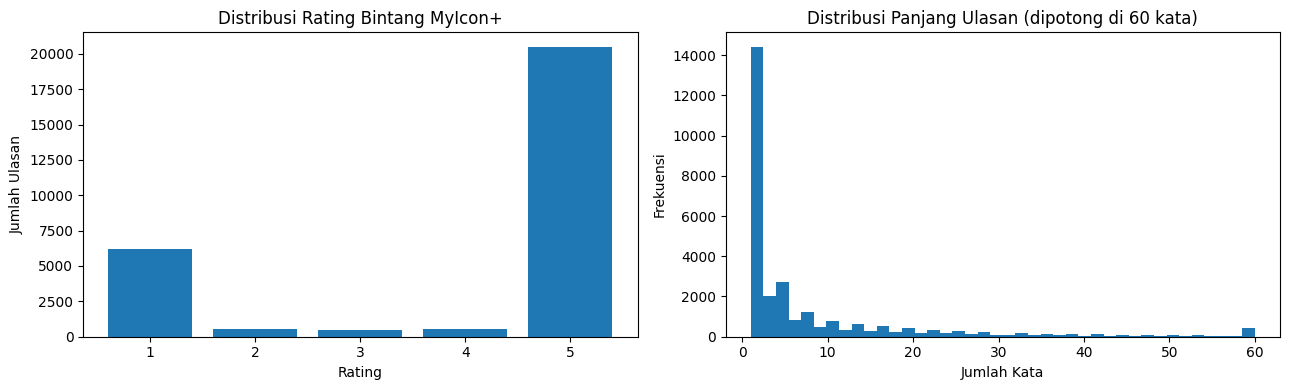

In [ ]:
df_raw['Tanggal'] = pd.to_datetime(df_raw['Tanggal'], errors='coerce')
panjang_kata = df_raw['Isi Ulasan'].astype(str).str.split().str.len()

print('DISTRIBUSI RATING BINTANG')
print('-' * 40)
dist_rating = df_raw['Rating Bintang'].value_counts().sort_index()
for r, n in dist_rating.items():
    print(f'  {r} bintang : {n:6,}  ({n/len(df_raw)*100:5.2f}%)')

print('\nSTATISTIK PANJANG ULASAN (jumlah kata, data mentah)')
print('-' * 40)
print(f'  Rata-rata      : {panjang_kata.mean():.2f} kata')
print(f'  Median         : {panjang_kata.median():.0f} kata')
print(f'  Maksimum       : {panjang_kata.max():.0f} kata')
print(f'  Ulasan < 3 kata: {(panjang_kata < 3).sum():,} ({(panjang_kata < 3).mean()*100:.2f}%)')
print(f'  Duplikat persis teks mentah: {df_raw["Isi Ulasan"].duplicated().sum():,}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(dist_rating.index.astype(str), dist_rating.values)
ax[0].set_title('Distribusi Rating Bintang MyIcon+'); ax[0].set_xlabel('Rating'); ax[0].set_ylabel('Jumlah Ulasan')
ax[1].hist(panjang_kata.clip(upper=60), bins=40)
ax[1].set_title('Distribusi Panjang Ulasan (dipotong di 60 kata)'); ax[1].set_xlabel('Jumlah Kata'); ax[1].set_ylabel('Frekuensi')
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/eda_rating_panjang.png', dpi=300, bbox_inches='tight'); plt.show()

### 2.3 Distribusi Ulasan per Tahun

JUMLAH ULASAN PER TAHUN (DATA MENTAH)


,jumlah_ulasan,tanggal_awal,tanggal_akhir,rata_rata_rating,persentase
tahun,,,,,
2023,10240,2023-04-03,2023-12-31,4.42,36.23
2024,11698,2024-01-01,2024-12-31,3.89,41.38
2025,5310,2025-01-01,2025-12-31,3.62,18.79
2026,1019,2026-01-01,2026-03-15,3.36,3.60



SEBARAN RATING PER TAHUN


,1 bintang,2 bintang,3 bintang,4 bintang,5 bintang
tahun,,,,,
2023,1332,109,97,110,8592
2024,2918,231,191,265,8093
2025,1603,141,165,148,3253
2026,361,41,38,27,552


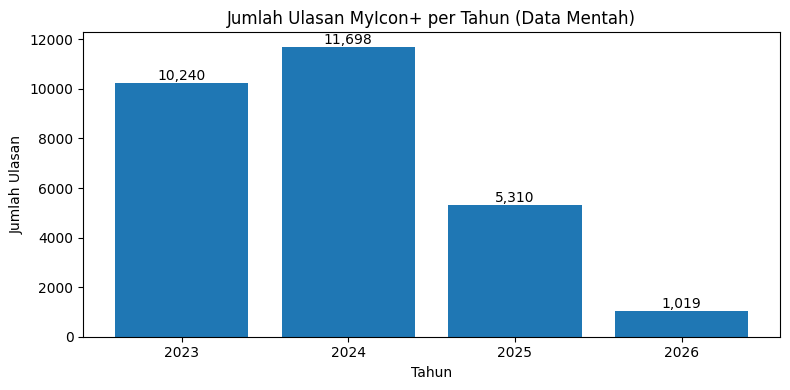

In [ ]:
data_th = pd.DataFrame({'tanggal': df_raw['Tanggal'], 'rating': df_raw['Rating Bintang']})
data_th['tahun'] = data_th['tanggal'].dt.year
gagal = data_th['tahun'].isna().sum()
if gagal > 0:
    print(f'Perhatian: {gagal} ulasan tanggalnya tidak terbaca dan tidak dihitung.\n')

g = data_th.groupby('tahun')
per_tahun = pd.DataFrame({'jumlah_ulasan': g.size(),
                          'tanggal_awal': g['tanggal'].min().dt.date,
                          'tanggal_akhir': g['tanggal'].max().dt.date,
                          'rata_rata_rating': g['rating'].mean().round(2)})
per_tahun['persentase'] = (per_tahun['jumlah_ulasan'] / per_tahun['jumlah_ulasan'].sum() * 100).round(2)
per_tahun.index = per_tahun.index.astype(int); per_tahun.index.name = 'tahun'
print('JUMLAH ULASAN PER TAHUN (DATA MENTAH)'); display(per_tahun)

rating_tahun = pd.crosstab(data_th['tahun'].astype('Int64'), data_th['rating'])
rating_tahun.columns = [f'{r} bintang' for r in rating_tahun.columns]
print('\nSEBARAN RATING PER TAHUN'); display(rating_tahun)
per_tahun.to_csv(f'{OUTPUT_DIR}/ulasan_mentah_per_tahun.csv')
rating_tahun.to_csv(f'{OUTPUT_DIR}/rating_per_tahun.csv')

fig, ax = plt.subplots(figsize=(8, 4))
batang = ax.bar(per_tahun.index.astype(str), per_tahun['jumlah_ulasan'])
ax.bar_label(batang, fmt='{:,.0f}')
ax.set_xlabel('Tahun'); ax.set_ylabel('Jumlah Ulasan'); ax.set_title('Jumlah Ulasan MyIcon+ per Tahun (Data Mentah)')
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/ulasan_per_tahun.png', dpi=300, bbox_inches='tight'); plt.show()

## 3. Preprocessing Data
Urutan: case folding, cleansing, normalisasi, stopword removal, penggabungan negasi, lalu penyaringan ulasan
kosong, duplikat, dan ulasan dengan kurang dari 2 token.

### 3.1 Case Folding

In [ ]:
df = df_raw[['Rating Bintang', 'Tanggal', 'Isi Ulasan']].copy()
df = df.rename(columns={'Rating Bintang': 'rating', 'Tanggal': 'tanggal', 'Isi Ulasan': 'ulasan_asli'})
N_AWAL = len(df)
df = df.dropna(subset=['ulasan_asli']).reset_index(drop=True)
N_NAN = N_AWAL - len(df)
df['case_folding'] = df['ulasan_asli'].astype(str).str.lower()

print(f'Ulasan awal: {N_AWAL:,} | isi kosong (NaN) dibuang: {N_NAN:,}')
print('CONTOH HASIL CASE FOLDING'); print('-' * 60)
contoh_cf = df[df['ulasan_asli'].astype(str).str[:60].str.contains(r'[A-Z]', regex=True)].head(3)
for _, row in contoh_cf.iterrows():
    print(f'Sebelum : {row["ulasan_asli"][:60]}')
    print(f'Sesudah : {row["case_folding"][:60]}\n')

Ulasan awal: 28,267 | isi kosong (NaN) dibuang: 0
CONTOH HASIL CASE FOLDING
------------------------------------------------------------
Sebelum : Bajuz.....tingkatkan lagi min 🙏
Sesudah : bajuz.....tingkatkan lagi min 🙏

Sebelum : Jaringan lambat sering gangguan, penanganan juga lambat
Sesudah : jaringan lambat sering gangguan, penanganan juga lambat

Sebelum : Alhamdulillah instalasi berjalan dengan lancar. Bapaknya bai
Sesudah : alhamdulillah instalasi berjalan dengan lancar. bapaknya bai



### 3.2 Cleansing
Tanda baca klausa dan emoji diganti penanda `|` supaya negasi tidak tergabung melewati batas kalimat. Penanda ini
tidak ikut ke input IndoBERT.

In [ ]:
BATAS = '|'
POLA_URL         = re.compile(r'http\S+|www\.\S+')
POLA_MENTION     = re.compile(r'[@#]\w+')
POLA_MBPS        = re.compile(r'\d+\s*(mbps|mb|mega)\b')
POLA_BATAS       = re.compile(r'[.,!?;:\n\r()\[\]"]+|[^\x00-\x7F]+')
POLA_ANGKA       = re.compile(r'\d+')
POLA_NONALFA     = re.compile(r'[^a-z\s|]')
POLA_ULANG       = re.compile(r'(.)\1{2,}')
POLA_BATAS_GANDA = re.compile(r'(\s*\|\s*)+')
POLA_SPASI       = re.compile(r'\s+')

def cleansing(teks: str) -> str:
    teks = POLA_URL.sub(' ', teks)
    teks = POLA_MENTION.sub(' ', teks)
    teks = POLA_MBPS.sub(' mbps ', teks)
    teks = POLA_BATAS.sub(' | ', teks)
    teks = POLA_ANGKA.sub(' ', teks)
    teks = POLA_NONALFA.sub(' ', teks)
    teks = POLA_ULANG.sub(r'\1', teks)
    teks = POLA_BATAS_GANDA.sub(' | ', teks)
    return POLA_SPASI.sub(' ', teks).strip(' |')

def tanpa_batas(teks: str) -> str:
    return POLA_SPASI.sub(' ', teks.replace(BATAS, ' ')).strip()

df['cleansing'] = df['case_folding'].apply(cleansing)

print('CONTOH HASIL CLEANSING'); print('-' * 60)
for t in ['jaringan tidak. saya kecewa 😡', 'Internet 20mbps lemot!!! cs gak respon', 'bener-bener mantappp 👍👍']:
    print(f'Sebelum : {t}')
    print(f'Sesudah : {cleansing(t.lower())}\n')

CONTOH HASIL CLEANSING
------------------------------------------------------------
Sebelum : jaringan tidak. saya kecewa 😡
Sesudah : jaringan tidak | saya kecewa

Sebelum : Internet 20mbps lemot!!! cs gak respon
Sesudah : internet mbps lemot | cs gak respon

Sebelum : bener-bener mantappp 👍👍
Sesudah : bener bener mantap



### 3.3 Kamus Normalisasi
Kamus slang umum dari kamus-alay (nasalsabila), ditambah kamus domain, typo, dan frasa dari ulasan MyIcon+.

In [ ]:
import requests
if os.path.exists(KAMUS_LOKAL):
    SUMBER_KAMUS = 'salinan lokal'
else:
    print(f'Salinan lokal belum ada. Mengunduh dari {URL_KAMUS}')
    r = requests.get(URL_KAMUS, timeout=60)
    r.raise_for_status()      # gagal unduh = berhenti, tidak ada fallback diam-diam
    os.makedirs(os.path.dirname(KAMUS_LOKAL), exist_ok=True)
    with open(KAMUS_LOKAL, 'wb') as f:
        f.write(r.content)
    SUMBER_KAMUS = 'unduhan baru, disimpan sebagai salinan lokal'
SHA_KAMUS = sha256_file(KAMUS_LOKAL)
kamus_df = pd.read_csv(KAMUS_LOKAL)
kamus_umum = dict(zip(kamus_df['slang'].astype(str).str.strip(), kamus_df['formal'].astype(str).str.strip()))
print(f'Kamus umum : {len(kamus_umum):,} entri unik ({SUMBER_KAMUS})')
print(f'SHA-256    : {SHA_KAMUS}')

# --- kamus domain ---
KAMUS_DOMAIN = {
    'gpp': 'tidak apa', 'gabisa': 'tidak bisa', 'ga': 'tidak', 'gak': 'tidak',
    'nggak': 'tidak', 'ngga': 'tidak', 'tdk': 'tidak', 'gk': 'tidak',
    'gapernah': 'tidak pernah', 'gaada': 'tidak ada', 'blm': 'belum',
    'udh': 'sudah', 'udah': 'sudah', 'sdh': 'sudah', 'bgt': 'banget',
    'bgs': 'bagus', 'jelek': 'jelek', 'knp': 'kenapa', 'kenapa': 'kenapa',
    'gimana': 'bagaimana', 'gmn': 'bagaimana', 'krn': 'karena',
    'karna': 'karena', 'sy': 'saya', 'aq': 'saya', 'gw': 'saya',
    'gue': 'saya', 'kl': 'kalau', 'klo': 'kalau', 'kalo': 'kalau',
    'jg': 'juga', 'aja': 'saja', 'utk': 'untuk', 'dgn': 'dengan',
    'tp': 'tapi', 'tpi': 'tapi', 'org': 'orang', 'bln': 'bulan',
    'thn': 'tahun', 'jgn': 'jangan', 'bs': 'bisa', 'sm': 'sama',
    'dr': 'dari', 'yg': 'yang', 'dpt': 'dapat', 'sngt': 'sangat',
    'bnyk': 'banyak', 'byk': 'banyak', 'lg': 'lagi', 'lgi': 'lagi',
    'wif': 'wifi', 'wify': 'wifi', 'wifiny': 'wifi', 'inet': 'internet',
    'intenet': 'internet', 'internetnya': 'internet', 'iconet': 'iconnet',
    'icon': 'iconnet', 'iconnet': 'iconnet', 'myiconnet': 'myicon',
    'konek': 'koneksi', 'konek si': 'koneksi', 'disconnect': 'putus',
    'dc': 'putus', 'los': 'loss', 'lemot': 'lambat', 'lelet': 'lambat',
    'lola': 'lambat', 'eror': 'error', 'erorr': 'error', 'ero': 'error',
    'apk': 'aplikasi', 'app': 'aplikasi', 'aplikasinya': 'aplikasi',
    'cs': 'customer service', 'teknisi': 'teknisi', 'tehnisi': 'teknisi',
    'tagihan': 'tagihan', 'bayar': 'bayar', 'tf': 'transfer',
    'gangguan': 'gangguan', 'ganguan': 'gangguan', 'gngguan': 'gangguan',
    'trobel': 'gangguan', 'troubel': 'gangguan', 'trouble': 'gangguan',
    'trobl': 'gangguan', 'troble': 'gangguan', 'problem': 'masalah',
    'gngguam': 'gangguan', 'gangguannya': 'gangguan',
    'enggak': 'tidak', 'engga': 'tidak', 'dahlah': 'sudahlah',
    'inconet': 'iconnet', 'icontl': 'iconnet',
}

# --- penyesuaian kamus domain ---
KAMUS_DOMAIN.pop('konek si', None)        # entri berspasi tidak pernah cocok per token; dipindah ke KAMUS_FRASA
if not PETA_ICON_KE_ICONNET:
    KAMUS_DOMAIN.pop('icon', None)        # 'icon' ambigu: aplikasi MyIcon+ atau layanan ICONNET
if PERTAHANKAN_KATA_EVALUATIF:
    KAMUS_DOMAIN.update({'good': 'bagus', 'nice': 'bagus', 'ok': 'oke', 'okay': 'oke', 'okey': 'oke',
                         'oke': 'oke', 'very': 'sangat', 'mantab': 'mantap'})

# --- kamus typo ---
KAMUS_TYPO = {
    'iconnect': 'iconnet', 'iconect': 'iconnet', 'iconek': 'iconnet',
    'inconnet': 'iconnet', 'icoonet': 'iconnet', 'icconnet': 'iconnet',
    'iconnec': 'iconnet', 'iconeet': 'iconnet', 'lconnet': 'iconnet',
    'gangguang': 'gangguan', 'ganggua': 'gangguan', 'gannguan': 'gangguan',
    'ngangguan': 'gangguan', 'gangguann': 'gangguan',
    'playanan': 'pelayanan', 'pelayana': 'pelayanan', 'pelanyanan': 'pelayanan',
    'palayanan': 'pelayanan', 'pelayann': 'pelayanan', 'pelayan': 'pelayanan',
    'aplikasih': 'aplikasi',
    'intrnet': 'internet', 'intetnet': 'internet', 'internat': 'internet',
    'jaringn': 'jaringan', 'jaringa': 'jaringan', 'jringan': 'jaringan',
    'jaringanx': 'jaringan', 'jaringam': 'jaringan', 'jariangan': 'jaringan',
    'jaringgan': 'jaringan',
    'tekhnisi': 'teknisi', 'tekniksi': 'teknisi',
    'pemasngan': 'pemasangan',
    'respons': 'respon', 'respond': 'respon', 'respone': 'respon',
    'respont': 'respon', 'repon': 'respon',
    'custumer': 'customer', 'custemer': 'customer',
    'lmbat': 'lambat', 'lamban': 'lambat',
    'sinya': 'sinyal', 'sinyak': 'sinyal',
    'wfi': 'wifi', 'waifi': 'wifi',
    'erro': 'error',
    'ngelag': 'lag', 'ngeleg': 'lag', 'mantaps': 'mantap',
    'penaganan': 'penanganan', 'penangananya': 'penanganan',
}
KAMUS_TYPO['mntap'] = 'mantap'            # ditemukan pada kata topik percobaan awal

KAMUS_FRASA = {'konek si': 'koneksi', 'mudah mudahan': 'semoga', 'semua nya': 'semua'}

kamus_normalisasi = dict(kamus_umum)
kamus_normalisasi.update(KAMUS_DOMAIN)     # kamus domain menimpa kamus umum (termasuk entri penjaga x->x)
print(f'Total entri kamus slang (umum + domain): {len(kamus_normalisasi):,}')
print(f'Entri typo domain: {len(KAMUS_TYPO)} | entri frasa: {len(KAMUS_FRASA)}')

Kamus umum : 4,330 entri unik (salinan lokal)
SHA-256    : a8323c7bd8002622d7b4eb6232fc9843e91c8301e91cee87905e8609d3c7a8c3
Total entri kamus slang (umum + domain): 4,385
Entri typo domain: 54 | entri frasa: 3


### 3.4 Normalisasi
Urutan per token: kamus typo → kamus slang → koreksi huruf dobel → lepas akhiran `-nya`, diulang sampai tidak
berubah (maks. 6 putaran). Koreksi huruf dobel hanya dipakai kalau hasilnya ada di kamus atau jauh lebih sering
muncul di korpus.

In [ ]:
frek_cleansing = Counter(w for t in df['cleansing'] for w in t.split() if w != BATAS)
KATA_BAKU = set()
for v in list(kamus_normalisasi.values()) + list(KAMUS_TYPO.values()):
    KATA_BAKU.update(str(v).split())
KUNCI_DIKENAL = set(kamus_normalisasi) | set(KAMUS_TYPO)
PENGECUALIAN_NYA = {'punya', 'hanya', 'tanya', 'bertanya', 'ditanya', 'menanya', 'nya', 'bahwasanya', 'sesungguhnya'}
MAKS_PUTARAN = 6
STAT_NORMAL = Counter()

def dikenal(w):
    return w in KUNCI_DIKENAL or w in KATA_BAKU

def koreksi_dobel(w):
    if dikenal(w):
        return w
    kelompok = [m.span() for m in re.finditer(r'(.)\1+', w)]
    if not kelompok or len(kelompok) > 4:
        return w
    kandidat = []
    for pilih in itertools.product([False, True], repeat=len(kelompok)):
        if not any(pilih):
            continue
        hasil, akhir = [], 0
        for (a, b), lepas in zip(kelompok, pilih):
            hasil.append(w[akhir:a]); hasil.append(w[a] if lepas else w[a:b]); akhir = b
        hasil.append(w[akhir:])
        kandidat.append((sum(pilih), ''.join(hasil)))
    for _, w2 in sorted(kandidat):
        if dikenal(w2) or frek_cleansing.get(w2, 0) >= 3 * max(frek_cleansing.get(w, 0), 1):
            return w2
    return w

def lepas_nya(w):
    if not w.endswith('nya') or w in PENGECUALIAN_NYA:
        return w
    dasar = w[:-3]
    if len(dasar) < 3:
        return w
    if dikenal(dasar) or frek_cleansing.get(dasar, 0) >= 3:
        return dasar
    d2 = koreksi_dobel(dasar)
    return d2 if d2 != dasar else w

_cache_token = {}
def normalisasi_token(w):
    if w == BATAS:
        return w
    if w in _cache_token:
        return _cache_token[w]
    asal, terlihat = w, [w]
    for _ in range(MAKS_PUTARAN):
        baru = KAMUS_TYPO.get(w, w)
        baru = kamus_normalisasi.get(baru, baru)
        if ' ' in baru:              # hasil berupa frasa (mis. 'tidak apa'), berhenti
            w = baru; STAT_NORMAL['hasil_frasa'] += 1; break
        baru = koreksi_dobel(baru)
        baru = lepas_nya(baru)
        if baru == w:
            break
        if baru in terlihat:
            STAT_NORMAL['siklus'] += 1; w = baru; break
        terlihat.append(baru); w = baru
    else:
        STAT_NORMAL['batas_putaran'] += 1
    _cache_token[asal] = w
    return w

def ganti_frasa(teks):
    for a, b in KAMUS_FRASA.items():
        teks = re.sub(rf'(?<![a-z_]){a}(?![a-z_])', b, teks)
    return teks

def normalisasi(teks: str) -> str:
    teks = ganti_frasa(teks)
    teks = ' '.join(normalisasi_token(w) for w in teks.split())
    return ganti_frasa(teks)

df['normal_berbatas'] = df['cleansing'].apply(normalisasi)
df['teks_embedding']  = df['normal_berbatas'].apply(tanpa_batas)

berubah = {a: b for a, b in _cache_token.items() if a != b}
print(f'Jenis token unik             : {len(_cache_token):,}')
print(f'Jenis token yang dinormalisasi: {len(berubah):,}')
print(f'Statistik khusus             : {dict(STAT_NORMAL)} (siklus/batas_putaran harus 0 atau sangat kecil)')

UJI_NORMAL = ['lemotnya', 'apknya', 'jaringanya', 'internetnya', 'pelayanannya', 'punya', 'hanya', 'tanya',
              'okee', 'mantappp', 'maaf', 'saat', 'tunggu', 'gaa', 'mntap', 'gpp', 'cs', 'icon', 'myiconnet',
              'good', 'ok']
print('\nUJI NORMALISASI TOKEN (pipeline lengkap)')
for w in UJI_NORMAL:
    w_c = cleansing(w)
    print(f'  {w:<14} -> {normalisasi(w_c)}')

print('\nCONTOH HASIL NORMALISASI KALIMAT (pipeline lengkap: cleansing + normalisasi)')
for t in ['gpp lah aplikasinya lumayan', 'inet nya lemot bgt gabisa dipake', 'cs nya ga respon udh 3 hari',
          'konek si sering putus, mudah-mudahan cepat diperbaiki']:
    print(f'  Sebelum : {t}')
    print(f'  Sesudah : {normalisasi(cleansing(t))}\n')

Jenis token unik             : 10,527
Jenis token yang dinormalisasi: 1,991
Statistik khusus             : {'hasil_frasa': 35} (siklus/batas_putaran harus 0 atau sangat kecil)

UJI NORMALISASI TOKEN (pipeline lengkap)
  lemotnya       -> lambat
  apknya         -> aplikasi
  jaringanya     -> jaringan
  internetnya    -> internet
  pelayanannya   -> pelayanan
  punya          -> punya
  hanya          -> hanya
  tanya          -> tanya
  okee           -> oke
  mantappp       -> mantap
  maaf           -> maaf
  saat           -> saat
  tunggu         -> tunggu
  gaa            -> tidak
  mntap          -> mantap
  gpp            -> tidak apa
  cs             -> customer service
  icon           -> icon
  myiconnet      -> myicon
  good           -> bagus
  ok             -> oke

CONTOH HASIL NORMALISASI KALIMAT (pipeline lengkap: cleansing + normalisasi)
  Sebelum : gpp lah aplikasinya lumayan
  Sesudah : tidak apa lah aplikasi lumayan

  Sebelum : inet nya lemot bgt gabisa dipake
  S

### 3.5 Stopword
Stopword Sastrawi ditambah stopword ulasan. Kata negasi, kata domain (`kurang`, `lama`, `sering`, `terus`), dan
kata evaluatif (`bagus`, `oke`) tidak dibuang. Tabel di bawah menunjukkan proporsi rating 1–2 pada ulasan yang
memuat kata tersebut.

In [ ]:
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
STOPWORDS_SASTRAWI = set(StopWordRemoverFactory().get_stop_words())
STOPWORDS = set(STOPWORDS_SASTRAWI)
# --- stopword tambahan khusus ulasan ---
STOPWORDS.update([
    'yg', 'nya', 'sih', 'deh', 'dong', 'kok', 'nih', 'tuh', 'ya', 'iya',
    'aja', 'saja', 'banget', 'bgt', 'gitu', 'gini', 'kayak', 'biar', 'lah',
    'kah', 'pun', 'toh', 'mah', 'eh', 'wah', 'loh', 'kan', 'yah', 'nah',
    'min', 'mimin', 'admin', 'tolong', 'mohon', 'terima', 'kasih',
    'terimakasih', 'makasih', 'thanks', 'semoga', 'mudah mudahan',
    'selamat', 'maaf', 'permisi', 'gan', 'bang', 'pak', 'bu', 'mas', 'mbak',
    'kalau', 'kalo', 'klo', 'jika', 'bila', 'maka', 'namun', 'tetapi',
    'tapi', 'sedangkan', 'melainkan', 'padahal', 'walaupun', 'meskipun',
    'sehingga', 'supaya', 'agar', 'ketika', 'saat', 'sambil', 'hingga',
    'sampai', 'sejak', 'setelah', 'sebelum', 'selama', 'sementara',
    'saya', 'aku', 'kamu', 'anda', 'dia', 'kita', 'kami', 'kalian',
    'mereka', 'nya', 'ini', 'itu', 'sini', 'situ', 'sana', 'begitu',
    'begini', 'tersebut', 'yaitu', 'yakni',
    'mau', 'ingin', 'harus', 'bisa', 'dapat', 'boleh', 'perlu', 'akan',
    'sudah', 'telah', 'belum', 'pernah', 'sedang', 'masih', 'lagi',
    'buat', 'bikin', 'jadi', 'menjadi', 'adalah', 'ada', 'punya',
    'suruh', 'coba', 'kasih', 'beri', 'pakai', 'pake', 'guna',
    'sangat', 'sekali', 'paling', 'lebih', 'kurang', 'cukup', 'agak',
    'semua', 'semua nya', 'seluruh', 'setiap', 'tiap', 'banyak',
    'sedikit', 'beberapa', 'sama', 'juga', 'malah', 'justru', 'bahkan',
    'terus', 'selalu', 'sering', 'kadang', 'jarang', 'baru', 'lama',
    'depan', 'belakang', 'atas', 'bawah', 'dalam', 'luar', 'antara',
    'sekarang', 'nanti', 'tadi', 'kemarin', 'besok', 'dulu',
    'orang', 'hal', 'cara', 'kali', 'nomor', 'via', 'kalu', 'gimana',
    'bagaimana', 'kenapa', 'mengapa', 'apa', 'siapa', 'mana', 'dimana',
    'the', 'is', 'are', 'was', 'this', 'that', 'you', 'your', 'and',
    'for', 'with', 'not', 'but', 'its', 'have', 'has', 'can', 'will',
    'app', 'apps', 'very', 'good', 'nice', 'ok', 'oke', 'okay', 'yes',
    'kec', 'kel', 'kab', 'kota', 'jln', 'jalan', 'rt', 'rw', 'no',
    'sudahlah', 'eeh', 'tb', 'mudahan'
])

STOPWORDS.update(['doang', 'mulu', 'melulu', 'maupun', 'benar'])

STOPWORD_BERSPASI = sorted(w for w in STOPWORDS if ' ' in w)
STOPWORDS -= set(STOPWORD_BERSPASI)
STOPWORDS -= set(KATA_DOMAIN_DIPERTAHANKAN)
KATA_EVALUATIF_INGGRIS = {'good', 'nice', 'ok', 'oke', 'okay'}
if PERTAHANKAN_KATA_EVALUATIF:
    STOPWORDS -= KATA_EVALUATIF_INGGRIS

# kata negasi tidak diperlakukan sebagai stopword
KATA_NEGASI_DASAR = {'tidak', 'belum', 'bukan', 'kurang', 'jangan', 'tanpa'}
NEGASI_DI_SASTRAWI = sorted(KATA_NEGASI_DASAR & STOPWORDS_SASTRAWI)
if NEGASI_TUNGGAL_DIPERTAHANKAN:
    STOPWORDS -= KATA_NEGASI_DASAR
else:
    STOPWORDS |= KATA_NEGASI_DASAR - {'kurang'}
assert not any(' ' in w for w in STOPWORDS)

print(f'Stopword Sastrawi: {len(STOPWORDS_SASTRAWI)} | total dipakai: {len(STOPWORDS)}')
print(f'Entri berspasi dikeluarkan: {STOPWORD_BERSPASI}')
print(f'Kata domain dipertahankan : {KATA_DOMAIN_DIPERTAHANKAN}')
print(f'Negasi yang ada di stopword Sastrawi: {NEGASI_DI_SASTRAWI} -> '
      f'{"dipertahankan (bukan stopword)" if NEGASI_TUNGGAL_DIPERTAHANKAN else "dibuang"}')

KANDIDAT = ['lama', 'sering', 'baru', 'terus', 'lebih', 'kurang', 'good', 'ok', 'oke', 'nice',
            'bagus', 'mantap', 'baik', 'tidak', 'belum', 'bukan', 'jangan', 'tanpa']
tok_cleansing = df['cleansing'].str.split()
tok_normal = df['normal_berbatas'].str.split()
negatif_semua = (df['rating'] <= 2).mean()
baris = []
for w in KANDIDAT:
    ada_asli = tok_cleansing.apply(lambda t: w in t)
    ada_norm = tok_normal.apply(lambda t: w in t)
    sub = df.loc[ada_norm, 'rating']
    baris.append({'kata': w, 'ulasan_memuat_asli': int(ada_asli.sum()), 'ulasan_memuat_setelah_normalisasi': int(ada_norm.sum()),
                  'rata_rata_rating': round(sub.mean(), 2) if len(sub) else np.nan,
                  'persen_rating_1_2': round((sub <= 2).mean() * 100, 1) if len(sub) else np.nan,
                  'stopword': w in STOPWORDS})
diag_stop = pd.DataFrame(baris)
print(f'\nPembanding: persen rating 1-2 di seluruh ulasan = {negatif_semua*100:.1f}% (penyebut: {len(df):,} ulasan)')
display(diag_stop)
diag_stop.to_csv(f'{OUTPUT_DIR}/diagnostik_stopword.csv', index=False)


Stopword Sastrawi: 123 | total dipakai: 274
Entri berspasi dikeluarkan: ['mudah mudahan', 'semua nya']
Kata domain dipertahankan : ['kurang', 'lama', 'sering', 'terus']
Negasi yang ada di stopword Sastrawi: ['belum', 'tanpa', 'tidak'] -> dipertahankan (bukan stopword)

Pembanding: persen rating 1-2 di seluruh ulasan = 23.8% (penyebut: 28,267 ulasan)


,kata,ulasan_memuat_asli,ulasan_memuat_setelah_normalisasi,rata_rata_rating,persen_rating_1_2,stopword
0,lama,985,998,1.38,89.3,False
1,sering,1234,1239,1.44,87.1,False
2,baru,719,737,1.86,77.3,True
3,terus,769,968,1.73,80.9,False
4,lebih,691,712,2.36,63.2,True
5,kurang,211,213,1.62,84.0,False
6,good,592,0,NaN,NaN,False
7,ok,4093,0,NaN,NaN,False
8,oke,1504,5839,4.93,0.9,False
9,nice,63,0,NaN,NaN,False


### 3.6 Penanganan Negasi dan Tokenisasi
Negasi digabung dengan kata berikutnya (`tidak stabil` → `tidak_stabil`), berhenti di penanda `|`. Negasi yang
tidak bisa digabung tetap disimpan. Token ini dipakai untuk c-TF-IDF, kosakata Top2Vec, dan evaluasi.

In [ ]:
KATA_NEGASI   = {'tidak', 'belum', 'bukan', 'kurang', 'jangan', 'tanpa'}
KATA_SISIPAN  = {'di', 'ke', 'yang', 'juga', 'lagi', 'nya', 'terlalu', 'begitu', 'sangat'}
FRASA_SISIPAN = {('sama', 'sekali')}
NEGASI_BOLEH_KE_STOPWORD = {'ada', 'bisa', 'dapat', 'pernah', 'mau', 'boleh', 'perlu', 'jadi', 'sama', 'cukup',
                            # kata fungsi yang maknanya berubah bila dinegasikan
                            'apa', 'lebih', 'semua', 'pakai', 'guna', 'baru', 'sampai', 'harus', 'ingin',
                            'punya', 'kasih', 'beri', 'sesuai'}
KATA_PENDEK_PENTING = {'wa'}
assert KATA_NEGASI == KATA_NEGASI_DASAR

def gabung_negasi(teks: str) -> str:
    kata = teks.split()
    hasil, i = [], 0
    while i < len(kata):
        w = kata[i]
        if w in KATA_NEGASI:
            j = i + 1
            while j < len(kata):
                if kata[j] in KATA_SISIPAN:
                    j += 1; continue
                if j + 1 < len(kata) and (kata[j], kata[j + 1]) in FRASA_SISIPAN:
                    j += 2; continue
                break
            if (j < len(kata) and kata[j] != BATAS and kata[j] not in KATA_NEGASI
                    and (kata[j] not in STOPWORDS or kata[j] in NEGASI_BOLEH_KE_STOPWORD)):
                hasil.append(f'{w}_{kata[j]}')
                i = j + 1
                continue
        hasil.append(w)
        i += 1
    return ' '.join(hasil)

def token_valid(t):
    return t != BATAS and (len(t) >= 3 or t in KATA_PENDEK_PENTING) and t not in STOPWORDS

def segmen_token(teks: str) -> list:
    # daftar segmen klausa, tiap segmen berisi token valid
    segmen, kini = [], []
    for t in gabung_negasi(teks).split():
        if t == BATAS:
            if kini: segmen.append(kini)
            kini = []
        elif token_valid(t):
            kini.append(t)
    if kini: segmen.append(kini)
    return segmen

def tokenisasi(teks: str) -> list:
    return [t for seg in segmen_token(teks) for t in seg]

UJI_NEGASI = [
    ('sinyal kurang', 'negatif'),
    ('tidak sama sekali membantu', 'negatif'),
    ('kurang dari seminggu sudah terpasang', 'netral'),
    ('jaringan tidak. saya kecewa', 'negatif, dua klausa'),
    ('internet tidak stabil', 'negatif'),
    ('aplikasi tidak bisa login', 'negatif'),
    ('pelayanan cepat, tidak ada kendala', 'positif, dua klausa'),
    ('sudah tidak lagi gangguan', 'positif'),
    ('respon lama, sering putus', 'negatif, dua klausa'),
    ('tidak sama dengan yang diiklankan', 'negatif'),
    ('gpp lah aplikasinya lumayan', 'positif'),
    ('belum juga diperbaiki sampai sekarang', 'negatif'),
    ('bukan internet cepat tapi lambat', 'negatif'),
    ('tidak sesuai harapan', 'negatif'),
    ('tidak semua teknisi ramah', 'campuran'),
]
print('UJI NEGASI DAN TOKENISASI (input melewati cleansing + normalisasi)')
uji_neg = []
for kalimat, jenis in UJI_NEGASI:
    norm = normalisasi(cleansing(kalimat))
    tok = tokenisasi(norm)
    n_neg_norm = sum(1 for w in norm.split() if w in KATA_NEGASI)
    n_neg_tok = sum(1 for t in tok if t in KATA_NEGASI or t.split('_')[0] in KATA_NEGASI)
    uji_neg.append({'kalimat': kalimat, 'jenis': jenis, 'setelah_normalisasi': norm, 'token': tok,
                    'negasi_setelah_normalisasi': n_neg_norm, 'negasi_di_token': n_neg_tok})
    print(f'  [{jenis:<20}] {kalimat:<40} -> {tok}')
uji_neg = pd.DataFrame(uji_neg)
uji_neg.to_csv(f'{OUTPUT_DIR}/uji_negasi.csv', index=False)
assert (uji_neg['negasi_di_token'] == uji_neg['negasi_setelah_normalisasi']).all(), \
    'Ada negasi yang hilang pada kalimat uji.'

df['tokens'] = df['normal_berbatas'].apply(tokenisasi)
df['jumlah_token'] = df['tokens'].apply(len)

# audit negasi pada seluruh korpus: negasi boleh berubah bentuk, tetapi tidak boleh hilang
def hitung_negasi_teks(teks):
    return Counter(w for w in teks.split() if w in KATA_NEGASI)
def hitung_negasi_token(tokens):
    return Counter(t.split('_')[0] for t in tokens if t.split('_')[0] in KATA_NEGASI)
neg_cleansing = sum((hitung_negasi_teks(t) for t in df['cleansing']), Counter())
neg_normal = sum((hitung_negasi_teks(t) for t in df['normal_berbatas']), Counter())
neg_token = sum((hitung_negasi_token(t) for t in df['tokens']), Counter())
neg_gabung = sum((Counter(t.split('_')[0] for t in tk if '_' in t and t.split('_')[0] in KATA_NEGASI)
                  for tk in df['tokens']), Counter())
AUDIT_NEGASI = pd.DataFrame({'setelah_cleansing': neg_cleansing, 'setelah_normalisasi': neg_normal,
                             'di_token_akhir': neg_token, 'di_antaranya_tergabung': neg_gabung}
                            ).reindex(sorted(KATA_NEGASI)).fillna(0).astype(int)
AUDIT_NEGASI['tunggal'] = AUDIT_NEGASI['di_token_akhir'] - AUDIT_NEGASI['di_antaranya_tergabung']
AUDIT_NEGASI['hilang'] = AUDIT_NEGASI['setelah_normalisasi'] - AUDIT_NEGASI['di_token_akhir']
print('\nAUDIT NEGASI SELURUH KORPUS (penambahan cleansing -> normalisasi berasal dari slang seperti gak/ga/tdk/blm)')
display(AUDIT_NEGASI)
AUDIT_NEGASI.to_csv(f'{OUTPUT_DIR}/audit_negasi.csv')
if NEGASI_TUNGGAL_DIPERTAHANKAN:
    assert (AUDIT_NEGASI['hilang'] == 0).all(), 'Ada negasi yang hilang setelah tokenisasi.'
gabungan_teratas = Counter(t for tk in df['tokens'] for t in tk if '_' in t).most_common(25)
print('Token negasi gabungan terbanyak:', ', '.join(f'{t} ({n})' for t, n in gabungan_teratas))

tokenizer_indobert = AutoTokenizer.from_pretrained(NAMA_MODEL_INDOBERT)
contoh_teks = 'koneksi internet sering putus dan aplikasi error'
print('\nTOKEN UNTUK c-TF-IDF / KOSAKATA TOP2VEC / EVALUASI :', tokenisasi(contoh_teks))
print('TOKEN WORDPIECE YANG DIBACA INDOBERT (teks embedding):', tokenizer_indobert.tokenize(contoh_teks))


UJI NEGASI DAN TOKENISASI (input melewati cleansing + normalisasi)
  [negatif             ] sinyal kurang                            -> ['sinyal', 'kurang']
  [negatif             ] tidak sama sekali membantu               -> ['tidak_membantu']
  [netral              ] kurang dari seminggu sudah terpasang     -> ['kurang', 'seminggu', 'terpasang']
  [negatif, dua klausa ] jaringan tidak. saya kecewa              -> ['jaringan', 'tidak', 'kecewa']
  [negatif             ] internet tidak stabil                    -> ['internet', 'tidak_stabil']
  [negatif             ] aplikasi tidak bisa login                -> ['aplikasi', 'tidak_bisa', 'login']
  [positif, dua klausa ] pelayanan cepat, tidak ada kendala       -> ['pelayanan', 'cepat', 'tidak_ada', 'kendala']
  [positif             ] sudah tidak lagi gangguan                -> ['tidak_gangguan']
  [negatif, dua klausa ] respon lama, sering putus                -> ['respon', 'lama', 'sering', 'putus']
  [negatif             ] tidak sama

,setelah_cleansing,setelah_normalisasi,di_token_akhir,di_antaranya_tergabung,tunggal,hilang
belum,658,945,945,893,52,0
bukan,159,194,194,154,40,0
jangan,406,495,495,405,90,0
kurang,221,224,224,186,38,0
tanpa,206,208,208,204,4,0
tidak,2830,6878,6878,6612,266,0


Token negasi gabungan terbanyak: tidak_ada (1955), tidak_bisa (1344), belum_ada (269), tidak_pernah (241), tidak_jelas (229), tidak_usah (83), tidak_mau (81), belum_bisa (77), tidak_stabil (77), tidak_guna (73), jangan_pakai (69), tidak_membantu (59), tidak_dapat (56), tidak_sesuai (54), tidak_bagus (51), tidak_respon (50), jangan_mau (47), tidak_memuaskan (47), tanpa_ada (47), tidak_profesional (46), tidak_tau (42), jangan_pasang (39), tidak_berguna (38), jangan_pernah (36), belum_selesai (36)


config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/234k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]


TOKEN UNTUK c-TF-IDF / KOSAKATA TOP2VEC / EVALUASI : ['koneksi', 'internet', 'sering', 'putus', 'aplikasi', 'error']
TOKEN WORDPIECE YANG DIBACA INDOBERT (teks embedding): ['koneksi', 'internet', 'sering', 'putus', 'dan', 'aplikasi', 'error']


### 3.7 Penyaringan Dokumen dan Deduplikasi
- **Ulasan bermakna**: tidak kosong dan minimal `MIN_TOKEN` token, termasuk duplikat (dipakai untuk distribusi
  rating dan tren per tahun).
- **Ulasan unik**: ulasan bermakna tanpa duplikat (dipakai untuk melatih model).

In [ ]:
df_valid = df[df['teks_embedding'].str.strip() != ''].copy()
N_KOSONG = len(df) - len(df_valid)
df_unik = df_valid.drop_duplicates(subset='teks_embedding', keep='first')
N_DUPLIKAT = len(df_valid) - len(df_unik)
df_bersih = df_unik[df_unik['jumlah_token'] >= MIN_TOKEN].reset_index(drop=True)
N_PENDEK = len(df_unik) - len(df_bersih)
df_semua_dasar = df_valid[df_valid['jumlah_token'] >= MIN_TOKEN].copy()
df_semua_dasar['tahun'] = pd.to_datetime(df_semua_dasar['tanggal'], errors='coerce').dt.year

CATATAN_TAHAP = {
    'ulasan_dataset_penuh': int(N_DATASET_PENUH), 'ulasan_awal_diproses': int(N_AWAL),
    'dibuang_nan': int(N_NAN), 'dibuang_kosong_setelah_cleansing': int(N_KOSONG),
    'dibuang_duplikat': int(N_DUPLIKAT), 'dibuang_kurang_dari_min_token': int(N_PENDEK),
    'ulasan_unik_dimodelkan': int(len(df_bersih)),
    'ulasan_bermakna_termasuk_duplikat': int(len(df_semua_dasar)),
    'min_token': MIN_TOKEN, 'mode_uji': MODE_UJI,
}
assert N_AWAL - N_NAN - N_KOSONG - N_DUPLIKAT - N_PENDEK == len(df_bersih)
assert df_bersih['teks_embedding'].is_unique

print('=' * 64); print('RINGKASAN PENYARINGAN DOKUMEN'); print('=' * 64)
print(f'  Ulasan awal                          : {N_AWAL:7,}')
print(f'  (-) Isi kosong (NaN)                 : {N_NAN:7,}')
print(f'  (-) Kosong setelah cleansing         : {N_KOSONG:7,}')
print(f'  (-) Duplikat (teks setelah normalisasi): {N_DUPLIKAT:7,}')
print(f'  (-) Kurang dari {MIN_TOKEN} token bermakna      : {N_PENDEK:7,}')
print('-' * 64)
print(f'  ULASAN UNIK SIAP PEMODELAN           : {len(df_bersih):7,}')
print(f'  Ulasan bermakna termasuk duplikat    : {len(df_semua_dasar):7,}')
print('=' * 64)

dokumen        = df_bersih['teks_embedding'].tolist()     # teks untuk IndoBERT
# Penanda batas di akhir dokumen: BERTopic menggabungkan ulasan per topik dengan spasi sebelum c-TF-IDF,
# sehingga tanpa penanda ini bigram dapat terbentuk dari kata terakhir satu ulasan dan kata pertama ulasan berikutnya.
dokumen_batas  = (df_bersih['normal_berbatas'] + f' {BATAS}').tolist()   # teks untuk c-TF-IDF dan kosakata Top2Vec
tokens_korpus  = df_bersih['tokens'].tolist()             # korpus referensi evaluasi
assert len(dokumen) == len(dokumen_batas) == len(tokens_korpus)

simpan = df_bersih.copy()
simpan['teks_final'] = simpan['tokens'].apply(' '.join)
simpan.drop(columns=['tokens']).to_csv(f'{OUTPUT_DIR}/ulasan_preprocessed.csv', index=False)
df_bersih[['ulasan_asli', 'teks_embedding', 'jumlah_token']].head()

RINGKASAN PENYARINGAN DOKUMEN
  Ulasan awal                          :  28,267
  (-) Isi kosong (NaN)                 :       0
  (-) Kosong setelah cleansing         :     156
  (-) Duplikat (teks setelah normalisasi):  14,271
  (-) Kurang dari 2 token bermakna      :     739
----------------------------------------------------------------
  ULASAN UNIK SIAP PEMODELAN           :  13,101
  Ulasan bermakna termasuk duplikat    :  16,166


,ulasan_asli,teks_embedding,jumlah_token
0,2 tahun lebih pakai iconet bener-bener harus s...,tahun lebih pakai iconnet benar benar harus sa...,24
1,"pemasangan rapih cepat,profesional",pemasangan rapi cepat profesional,4
2,semakin kesini semakin jelek kualitas internet...,semakin kesini semakin jelek kualitas internet...,24
3,Bajuz.....tingkatkan lagi min 🙏,bajuz tingkatkan lagi min,2
4,oke siap,oke siap,2


### 3.8 Tabel Duplikat Ulasan

In [ ]:
kelompok = df_valid.groupby('teks_embedding')
tabel_dup = pd.DataFrame({
    'jumlah_kemunculan':    kelompok.size(),
    'jumlah_token':         kelompok['jumlah_token'].first(),
    'variasi_tulisan_asli': kelompok['ulasan_asli'].nunique(),
    'contoh_tulisan_asli':  kelompok['ulasan_asli'].apply(lambda s: ' | '.join(s.drop_duplicates().head(3).astype(str).str[:40])),
})
tabel_dup = tabel_dup[tabel_dup['jumlah_kemunculan'] > 1].sort_values('jumlah_kemunculan', ascending=False)
tabel_dup['duplikat_dibuang'] = tabel_dup['jumlah_kemunculan'] - 1
tabel_dup['lolos_filter_token'] = tabel_dup['jumlah_token'] >= MIN_TOKEN
tabel_dup.index.name = 'teks_setelah_normalisasi'
total_dibuang = int(tabel_dup['duplikat_dibuang'].sum())
assert total_dibuang == N_DUPLIKAT
dibuang_panjang = int(tabel_dup.loc[tabel_dup['lolos_filter_token'], 'duplikat_dibuang'].sum())

print(f'Teks yang muncul lebih dari sekali : {len(tabel_dup):,}')
print(f'Total duplikat dibuang             : {total_dibuang:,}')
print(f'  - di antaranya >= {MIN_TOKEN} token        : {dibuang_panjang:,}')
print(f'  - di antaranya <  {MIN_TOKEN} token        : {total_dibuang - dibuang_panjang:,}')
display(tabel_dup.head(15))
display(tabel_dup[tabel_dup['lolos_filter_token']].head(10))
tabel_dup.to_csv(f'{OUTPUT_DIR}/tabel_duplikat.csv')

Teks yang muncul lebih dari sekali : 730
Total duplikat dibuang             : 14,271
  - di antaranya >= 2 token        : 3,065
  - di antaranya <  2 token        : 11,206


,jumlah_kemunculan,jumlah_token,variasi_tulisan_asli,contoh_tulisan_asli,duplikat_dibuang,lolos_filter_token
teks_setelah_normalisasi,,,,,,
oke,4809,1,50,oke | ok | okk,4808,False
mantap,2630,1,132,mantap | Mantab | mantappp,2629,False
bagus,1429,1,65,Bagus | good | bagus,1428,False
baik,416,1,10,Baik | baik | BAIK,415,False
terbaik,184,1,20,terbaik | Terbaik | terbaik👍,183,False
aplikasi bagus,183,2,23,Aplikasinya bagus | aplikasi bagus | apk bagus...,182,True
oke mantap,167,2,39,ok mantap | ok Mantap | oke mantap,166,True
sangat membantu,163,1,15,Sangat membantu 👍🏻 | sangat membantu | Sangat ...,162,False
keren,125,1,39,Keren | keren | Keren.....,124,False


,jumlah_kemunculan,jumlah_token,variasi_tulisan_asli,contoh_tulisan_asli,duplikat_dibuang,lolos_filter_token
teks_setelah_normalisasi,,,,,,
aplikasi bagus,183,2,23,Aplikasinya bagus | aplikasi bagus | apk bagus...,182,True
oke mantap,167,2,39,ok mantap | ok Mantap | oke mantap,166,True
pelayanan baik,111,2,14,pelayanan baik | Pelayanan baik | pelayanan ba...,110,True
oke baik,81,2,7,ok baik | ok baikkk | Ok baik,80,True
semoga internet lancar,75,2,6,Semoga internetnya lancar | Semoga internet la...,74,True
pelayanan bagus,64,2,15,pelayanan bagus | Pelayanannya bagus :). | pel...,63,True
iconnet oke,60,2,10,Iconnet oke | Iconnet ok | Iconet ok,59,True
pemasangan iconnet sangat baik,56,3,3,pemasangan iconet sangat baik | pemasangan ico...,55,True
pelayanan cepat,54,2,9,Pelayanan cepat | pelayanan cepat | pelayana c...,53,True


## 4. Embedding IndoBERT
### 4.1 Model Embedding dan Pemeriksaan Panjang Teks
Mean pooling dengan attention mask. Panjang token diperiksa terhadap `MAX_SEQ_LENGTH`.

In [ ]:
layer_transformer = models.Transformer(NAMA_MODEL_INDOBERT, max_seq_length=MAX_SEQ_LENGTH)
layer_pooling = models.Pooling(layer_transformer.get_word_embedding_dimension(), pooling_mode='mean')
model_embedding = SentenceTransformer(modules=[layer_transformer, layer_pooling], device=DEVICE)
model_embedding.eval()
DIM_EMBEDDING = model_embedding.get_sentence_embedding_dimension()
assert model_embedding.max_seq_length == MAX_SEQ_LENGTH

try:
    from huggingface_hub import HfApi
    REVISI_MODEL = HfApi().model_info(NAMA_MODEL_INDOBERT).sha
except Exception as e:
    REVISI_MODEL = f'tidak diketahui ({type(e).__name__})'

panjang_wp = np.array([len(ids) for ids in tokenizer_indobert(dokumen, add_special_tokens=True,
                                                               truncation=False)['input_ids']])
terpotong = np.where(panjang_wp > MAX_SEQ_LENGTH)[0]
INFO_EMBEDDING = {'model': NAMA_MODEL_INDOBERT, 'revisi': REVISI_MODEL, 'pooling': 'mean (attention mask)',
                  'max_seq_length': MAX_SEQ_LENGTH, 'dimensi': int(DIM_EMBEDDING), 'device': DEVICE,
                  'batch_size': BATCH_EMBEDDING, 'n_dokumen': len(dokumen),
                  'n_terpotong': int(len(terpotong)),
                  'persen_terpotong': round(len(terpotong) / len(dokumen) * 100, 3),
                  'panjang_wordpiece_maks': int(panjang_wp.max()),
                  'panjang_wordpiece_median': float(np.median(panjang_wp))}
pd.DataFrame({'indeks': terpotong, 'panjang_wordpiece': panjang_wp[terpotong],
              'teks': [dokumen[i][:200] for i in terpotong]}).to_csv(f'{OUTPUT_DIR}/dokumen_terpotong.csv', index=False)
for k, v in INFO_EMBEDDING.items():
    print(f'  {k:<26}: {v}')

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  445MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: indolem/indobert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  model                     : indolem/indobert-base-uncased
  revisi                    : 7ccb3cd0f5b08ffbaa465aade22328e8600e23eb
  pooling                   : mean (attention mask)
  max_seq_length            : 128
  dimensi                   : 768
  device                    : cuda
  batch_size                : 64
  n_dokumen                 : 13101
  n_terpotong               : 0
  persen_terpotong          : 0.0
  panjang_wordpiece_maks    : 126
  panjang_wordpiece_median  : 12.0


### 4.2 Embedding dengan Cache
Cache hanya dipakai kalau model, revisi, panjang maksimum, versi library, dan teksnya sama.

In [ ]:
META_EMB = {'model': NAMA_MODEL_INDOBERT, 'revisi': REVISI_MODEL, 'max_seq_length': MAX_SEQ_LENGTH,
            'pooling': 'mean', 'n': len(dokumen), 'sha_teks': sha256_teks(dokumen),
            'torch': VERSI['torch'], 'transformers': VERSI['transformers'],
            'sentence-transformers': VERSI['sentence-transformers']}
KUNCI_EMB = hashlib.sha256(json.dumps(META_EMB, sort_keys=True).encode()).hexdigest()[:16]
import glob

def berkas_cache(stem):
    return f'{stem}.npy', f'{stem}_meta.json', f'{stem}_teks.json'

def cek_cache(stem):
    f_npy, f_meta, f_teks = berkas_cache(stem)
    if not (os.path.exists(f_npy) and os.path.exists(f_meta) and os.path.exists(f_teks)):
        return None, 'set file tidak lengkap'
    e = np.load(f_npy)
    if e.shape != (len(dokumen), DIM_EMBEDDING): return None, f'bentuk {e.shape} tidak cocok'
    if json.load(open(f_meta)) != META_EMB: return None, 'metadata berbeda'
    if json.load(open(f_teks)) != dokumen: return None, 'daftar teks/urutan berbeda'
    if not np.isfinite(e).all(): return None, 'mengandung NaN/inf'
    return e, 'valid'

# Setiap set cache punya nama sendiri: embedding_<kunci>[_<waktu>].npy/_meta.json/_teks.json.
# Set yang tidak valid tidak pernah dihapus atau ditimpa.
embeddings_indobert, alasan, stem_dipakai = None, 'file cache belum ada', None
if PAKAI_CACHE:
    kandidat = sorted(glob.glob(f'{CACHE_DIR}/embedding_{KUNCI_EMB}*.npy'), key=os.path.getmtime, reverse=True)
    for f in kandidat:
        stem = f[:-4]
        e, ket = cek_cache(stem)
        if e is not None:
            embeddings_indobert, alasan, stem_dipakai = e, ket, stem
            break
        alasan = f'{os.path.basename(f)}: {ket}'
        catat_cache('embedding', KUNCI_EMB, 'tidak valid', alasan)
else:
    alasan = 'PAKAI_CACHE=False'

if embeddings_indobert is not None:
    catat_cache('embedding', KUNCI_EMB, 'dipakai', f'{stem_dipakai}.npy ({alasan})')
else:
    mulai = time.time()
    with torch.no_grad():
        embeddings_indobert = model_embedding.encode(dokumen, batch_size=BATCH_EMBEDDING, show_progress_bar=True,
                                                     convert_to_numpy=True).astype(np.float32)
    INFO_EMBEDDING['waktu_menit'] = round((time.time() - mulai) / 60, 2)
    stem = f'{CACHE_DIR}/embedding_{KUNCI_EMB}'
    if any(os.path.exists(x) for x in berkas_cache(stem)):
        stem = f'{stem}_{WAKTU_MULAI:%Y%m%d%H%M%S}'
    f_npy, f_meta, f_teks = berkas_cache(stem)
    np.save(f_npy, embeddings_indobert)
    json.dump(META_EMB, open(f_meta, 'w'), indent=2)
    json.dump(dokumen, open(f_teks, 'w'))
    catat_cache('embedding', KUNCI_EMB, 'dihitung', f'alasan: {alasan}; disimpan ke {f_npy}')

assert embeddings_indobert.shape == (len(dokumen), DIM_EMBEDDING)
np.save(f'{OUTPUT_DIR}/embeddings_indobert.npy', embeddings_indobert)
print(f'Embedding: {embeddings_indobert.shape}, dtype {embeddings_indobert.dtype}')

[CACHE embedding] dipakai: /content/drive/MyDrive/DATASET TA/hasil_revisi/_cache/embedding_3fcf9ab07003cccb.npy (valid)
Embedding: (13101, 768), dtype float32


### 4.3 Verifikasi Embedding
Cek padding (batch vs satu per satu), urutan baris, dan tidak ada vektor nol atau NaN.

In [ ]:
def cos_baris(a, b):
    return np.sum(normalize(a) * normalize(b), axis=1)

urut_panjang = np.argsort(panjang_wp)
idx_uji = np.unique(np.concatenate([urut_panjang[:8], urut_panjang[-8:]]))
with torch.no_grad():
    e_batch = model_embedding.encode([dokumen[i] for i in idx_uji], batch_size=len(idx_uji), convert_to_numpy=True)
    e_satu = np.vstack([model_embedding.encode([dokumen[i]], convert_to_numpy=True) for i in idx_uji])
    rng = np.random.default_rng(SEED)
    idx_acak = rng.choice(len(dokumen), size=min(5, len(dokumen)), replace=False)
    e_ulang = model_embedding.encode([dokumen[i] for i in idx_acak], convert_to_numpy=True)
cek_padding = float(cos_baris(e_batch, e_satu).min())
cek_urutan = float(cos_baris(e_ulang, embeddings_indobert[idx_acak]).min())
norma = np.linalg.norm(embeddings_indobert, axis=1)
VERIFIKASI_EMBEDDING = {'cos_min_batch_vs_tunggal': round(cek_padding, 6), 'cos_min_urutan': round(cek_urutan, 6),
                        'norma_min': float(norma.min()), 'ada_nan': bool(~np.isfinite(embeddings_indobert).all())}
print(VERIFIKASI_EMBEDDING)
assert cek_padding > 0.9999, 'Embedding batch berbeda dari embedding tunggal: periksa padding/attention mask.'
assert cek_urutan > 0.9999, 'Baris embedding tidak cocok dengan dokumennya: periksa urutan/cache.'
assert norma.min() > 0 and not VERIFIKASI_EMBEDDING['ada_nan']
INFO_EMBEDDING.update(VERIFIKASI_EMBEDDING)
print('Verifikasi padding, urutan, dan numerik: LULUS')

{'cos_min_batch_vs_tunggal': 1.0, 'cos_min_urutan': 1.0, 'norma_min': 12.576895713806152, 'ada_nan': False}
Verifikasi padding, urutan, dan numerik: LULUS


### 4.4 Fungsi Embedding untuk Top2Vec
Top2Vec memakai vektor dokumen IndoBERT yang sama dari 4.2. Token negasi seperti `tidak_bisa` dikodekan sebagai
"tidak bisa".

In [ ]:
CACHE_DOK = {}
for i, (tb, te) in enumerate(zip(dokumen_batas, dokumen)):
    CACHE_DOK[tb] = embeddings_indobert[i]
    CACHE_DOK[te] = embeddings_indobert[i]
CACHE_KATA = {}
STAT_EMBED = Counter()

def embed_indobert(daftar_teks):
    daftar_teks = list(daftar_teks)
    hasil, perlu = [None] * len(daftar_teks), []
    for i, t in enumerate(daftar_teks):
        v = CACHE_DOK.get(t)
        if v is not None:
            STAT_EMBED['dokumen_dari_cache'] += 1
        else:
            v = CACHE_KATA.get(t)
            if v is None:
                if ' ' in t or BATAS in t:
                    raise KeyError(f'Dokumen tidak ditemukan di cache embedding: {t[:80]!r}')
                perlu.append(i)
            else:
                STAT_EMBED['kata_dari_cache'] += 1
        hasil[i] = v
    if perlu:
        with torch.no_grad():
            baru = model_embedding.encode([daftar_teks[i].replace('_', ' ') for i in perlu], batch_size=BATCH_EMBEDDING,
                                          show_progress_bar=False, convert_to_numpy=True)
        for i, v in zip(perlu, baru):
            CACHE_KATA[daftar_teks[i]] = v; hasil[i] = v
        STAT_EMBED['kata_dikodekan'] += len(perlu)
    return np.vstack(hasil).astype(np.float32)

assert np.allclose(embed_indobert(dokumen_batas[:5]), embeddings_indobert[:5])
assert not any('_' in d for d in dokumen), 'Teks embedding tidak boleh memuat garis bawah.'
print('Top2Vec memakai vektor dokumen yang sama persis dengan BERTopic.')

Top2Vec memakai vektor dokumen yang sama persis dengan BERTopic.


## 5. Fungsi Model
### 5.1 Komponen Bersama
Argumen UMAP dan HDBSCAN sama untuk kedua model. Bedanya: Top2Vec menggabungkan topik yang mirip
(`topic_merge_delta`) dan menempatkan semua dokumen ke topik terdekat, sedangkan BERTopic membiarkan outlier (−1).

In [ ]:
UMAP_DEFAULT = {'n_neighbors': 15, 'n_components': 5, 'min_dist': 0.0, 'metric': 'cosine'}
HDBSCAN_DEFAULT = {'min_cluster_size': 50, 'metric': 'euclidean', 'cluster_selection_method': 'leaf'}
KUNCI_UMAP = {'n_neighbors', 'n_components', 'min_dist', 'metric', 'spread'}
KUNCI_HDBSCAN = {'min_cluster_size', 'min_samples', 'cluster_selection_method', 'cluster_selection_epsilon', 'alpha'}
KUNCI_REPR = {'min_df', 'min_count'}

def pisah_parameter(params, seed=SEED):
    umap_args, hdb_args = dict(UMAP_DEFAULT), dict(HDBSCAN_DEFAULT)
    umap_args['random_state'] = seed
    for k, v in params.items():
        if k in KUNCI_UMAP: umap_args[k] = v
        elif k in KUNCI_HDBSCAN: hdb_args[k] = v
        elif k in KUNCI_REPR: continue
        else: raise ValueError(f'Parameter tidak dikenal: {k}')
    return umap_args, hdb_args

def bersihkan_tipe(params):
    # nilai dari CSV/numpy diubah ke tipe Python biasa agar konsisten
    return {k: (int(v) if isinstance(v, (np.integer,)) or (isinstance(v, float) and float(v).is_integer())
                else v) for k, v in params.items()}
print('Konfigurasi komponen bersama siap.')

Konfigurasi komponen bersama siap.


### 5.2 Fungsi BERTopic
c-TF-IDF memakai unigram dan bigram dalam satu klausa. `min_df` dihitung per ulasan unik, bukan per topik, supaya
konfigurasi dengan sedikit topik tetap bisa dijalankan.

In [ ]:
def analyzer_bertopic(teks):
    hasil = []
    for seg in segmen_token(teks):
        hasil.extend(seg)
        if NGRAM_BERTOPIC[1] >= 2:
            hasil.extend(f'{a} {b}' for a, b in zip(seg, seg[1:]))
    return hasil

_VOCAB_MIN_DF = {}
def vocab_min_df(min_df):
    # kosakata (unigram + bigram dalam klausa) yang muncul di >= min_df ulasan unik
    min_df = int(min_df)
    if min_df not in _VOCAB_MIN_DF:
        cv_ = CountVectorizer(analyzer=analyzer_bertopic, min_df=min_df, lowercase=False).fit(dokumen_batas)
        _VOCAB_MIN_DF[min_df] = sorted(cv_.vocabulary_)
    return _VOCAB_MIN_DF[min_df]

def buat_vectorizer(min_df):
    if MIN_DF_TINGKAT == 'dokumen':
        return CountVectorizer(analyzer=analyzer_bertopic, vocabulary=vocab_min_df(min_df), lowercase=False)
    if MIN_DF_TINGKAT == 'topik':
        return CountVectorizer(analyzer=analyzer_bertopic, min_df=min_df, lowercase=False)
    raise ValueError(f'MIN_DF_TINGKAT tidak dikenal: {MIN_DF_TINGKAT}')

def verifikasi_parameter_bertopic(topic_model, umap_args, hdb_args, min_df=None):
    um, hd = topic_model.umap_model, topic_model.hdbscan_model
    for k, v in umap_args.items():
        assert getattr(um, k) == v, f'UMAP {k}: diminta {v}, terpakai {getattr(um, k)}'
    for k, v in hdb_args.items():
        assert getattr(hd, k) == v, f'HDBSCAN {k}: diminta {v}, terpakai {getattr(hd, k)}'
    if min_df is not None and MIN_DF_TINGKAT == 'dokumen':
        assert list(topic_model.vectorizer_model.vocabulary) == vocab_min_df(min_df), 'Kosakata BERTopic tidak sesuai min_df.'
    elif min_df is not None:
        assert topic_model.vectorizer_model.min_df == min_df, 'min_df BERTopic tidak sesuai.'

def jalankan_bertopic(params, seed=SEED, verbose=False):
    params = bersihkan_tipe(params)
    umap_args, hdb_args = pisah_parameter(params, seed)
    min_df = params.get('min_df', REPR_DEFAULT['BERTopic']['min_df'])
    topic_model = BERTopic(
        embedding_model=model_embedding,
        umap_model=UMAP(**umap_args),
        hdbscan_model=HDBSCAN(**hdb_args, prediction_data=True),
        vectorizer_model=buat_vectorizer(min_df),
        ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
        top_n_words=TOP_N_WORDS_BERTOPIC,
        calculate_probabilities=False,
        verbose=verbose)
    topics, _ = topic_model.fit_transform(dokumen_batas, embeddings=embeddings_indobert)
    verifikasi_parameter_bertopic(topic_model, umap_args, hdb_args, min_df)
    return topic_model, np.array(topics)

def kata_topik_bertopic(topic_model, topn=TOPN_EVAL):
    # dict topik -> {'tampil': 10 kata (uni+bigram), 'eval': <=10 unigram}
    hasil = {}
    for t in sorted(topic_model.get_topics()):
        if t == -1:
            continue
        semua = [w for w, s in (topic_model.get_topic(t) or []) if w]   # kata kosong (skor 0 pengisi) dibuang
        hasil[int(t)] = {'tampil': semua[:topn], 'eval': [w for w in semua if ' ' not in w][:topn]}
    return hasil

if MIN_DF_TINGKAT == 'dokumen':
    for m in sorted({REPR_DEFAULT['BERTopic']['min_df'], *GRID_REPR['BERTopic']['min_df']}):
        v = vocab_min_df(m)
        print(f'Kosakata c-TF-IDF min_df={m:<3} (>= {m} ulasan): {len(v):,} kata/bigram '
              f'({sum(" " not in w for w in v):,} unigram)')
print('Fungsi BERTopic siap digunakan.')


Kosakata c-TF-IDF min_df=2   (>= 2 ulasan): 12,404 kata/bigram (3,691 unigram)
Kosakata c-TF-IDF min_df=5   (>= 5 ulasan): 4,059 kata/bigram (1,725 unigram)
Kosakata c-TF-IDF min_df=10  (>= 10 ulasan): 2,049 kata/bigram (1,076 unigram)
Fungsi BERTopic siap digunakan.


### 5.3 Fungsi Top2Vec dan Replikasi Noise HDBSCAN
Top2Vec tidak menyimpan label noise, jadi UMAP dan HDBSCAN dijalankan ulang dengan argumen yang sama. Replikasi
dianggap sah kalau centroidnya cocok dengan vektor topik Top2Vec (cosine > 0,999).

In [ ]:
def tokenizer_top2vec(teks):
    return tokenisasi(teks)

def jalankan_top2vec(params, seed=SEED, verbose=False):
    params = bersihkan_tipe(params)
    umap_args, hdb_args = pisah_parameter(params, seed)
    model = Top2Vec(documents=dokumen_batas, embedding_model=embed_indobert, embedding_batch_size=BATCH_EMBEDDING,
                    min_count=params.get('min_count', REPR_DEFAULT['Top2Vec']['min_count']),
                    topic_merge_delta=TOP2VEC_MERGE_DELTA, tokenizer=tokenizer_top2vec,
                    umap_args=dict(umap_args), hdbscan_args=dict(hdb_args), verbose=verbose)
    return model, umap_args, hdb_args

def replikasi_klaster_top2vec(model, umap_args, hdb_args):
    dv = model.document_vectors
    emb_umap = UMAP(**umap_args).fit(dv).embedding_
    label = HDBSCAN(**hdb_args).fit(emb_umap).labels_
    klaster = sorted(set(label) - {-1})
    hasil = {'label_hdbscan': label, 'rasio_noise': float(np.mean(label == -1)),
             'n_noise': int(np.sum(label == -1)), 'K_hdbscan': len(klaster),
             'K_setelah_merge': int(model.topic_vectors.shape[0]), 'replikasi_terverifikasi': False}
    if not klaster:
        return hasil
    cent = normalize(np.vstack([dv[label == l].mean(axis=0) for l in klaster]))
    _, lbl = dbscan(X=cent, eps=TOP2VEC_MERGE_DELTA, min_samples=2, metric='cosine')
    unik = [cent[i] for i in np.where(lbl == -1)[0]]
    for g in sorted(set(lbl) - {-1}):
        unik.append(normalize(cent[lbl == g].mean(axis=0).reshape(1, -1))[0])
    unik = np.vstack(unik)
    if unik.shape[0] == model.topic_vectors.shape[0]:
        s = model.topic_vectors @ unik.T
        r, c = linear_sum_assignment(-s)
        hasil['replikasi_terverifikasi'] = bool(s[r, c].min() > 0.999)
    return hasil

def kata_topik_top2vec(model, topn=TOPN_EVAL):
    topic_words, _, topic_nums = model.get_topics()
    return {int(t): {'tampil': list(w[:topn]), 'eval': list(w[:topn])} for t, w in zip(topic_nums, topic_words)}
print('Fungsi Top2Vec siap digunakan.')

Fungsi Top2Vec siap digunakan.


## 6. Fungsi Evaluasi
- Kata yang dinilai: 10 unigram teratas per topik untuk kedua model.
- C_v (jendela 110) dan NPMI (jendela 10) dengan gensim, korpus referensi = ulasan unik.
- Topic diversity = kata unik / total kata.

In [ ]:
dictionary = Dictionary(tokens_korpus)
print(f'Ukuran kamus referensi (tanpa filter): {len(dictionary):,} token')

def siapkan_topik_eval(kata_per_topik, topn=TOPN_EVAL):
    valid, n_efektif = [], []
    for kata in kata_per_topik:
        k = [w for w in kata[:topn] if w in dictionary.token2id]
        n_efektif.append(len(k))
        if len(k) >= 2:
            valid.append(k)
    return valid, n_efektif

def hitung_coherence(topik_valid, ukuran='c_v', per_topik=False):
    if not topik_valid:
        return (np.nan, []) if per_topik else np.nan
    cm = CoherenceModel(topics=topik_valid, texts=tokens_korpus, dictionary=dictionary,
                        coherence=ukuran, topn=TOPN_EVAL, window_size=JENDELA_KOHERENSI[ukuran], processes=1)
    per = [float(x) for x in cm.get_coherence_per_topic()]
    rata = float(np.mean(per))
    return (rata, per) if per_topik else rata

def hitung_diversity(topik_valid):
    semua = [w for k in topik_valid for w in k]
    return len(set(semua)) / len(semua) if semua else np.nan

def evaluasi_model(kata_per_topik, per_topik=False):
    valid, n_ef = siapkan_topik_eval(kata_per_topik)
    cv, cv_per = hitung_coherence(valid, 'c_v', per_topik=True)
    npmi, npmi_per = hitung_coherence(valid, 'c_npmi', per_topik=True)
    hasil = {'jumlah_topik': len(kata_per_topik),
             'topik_dinilai': len(valid),
             'topik_tidak_dinilai': len(kata_per_topik) - len(valid),
             'kata_efektif_min': int(min(n_ef)) if n_ef else 0,
             'kata_efektif_rata': round(float(np.mean(n_ef)), 2) if n_ef else 0.0,
             'coherence_cv': cv,
             'coherence_npmi': npmi,
             'topic_diversity': hitung_diversity(valid)}
    if per_topik:
        it_cv, it_np = iter(cv_per), iter(npmi_per)
        hasil['cv_per_topik'] = [next(it_cv) if n >= 2 else np.nan for n in n_ef]   # sejajar dengan semua topik
        hasil['npmi_per_topik'] = [next(it_np) if n >= 2 else np.nan for n in n_ef]
        hasil['kata_efektif_per_topik'] = n_ef
    return hasil

# uji konsistensi: rata-rata per topik sama dengan nilai agregat gensim
_uji = [['gangguan', 'internet'], ['pelayanan', 'cepat']]
_uji = [[w for w in k if w in dictionary.token2id] for k in _uji]
_uji = [k for k in _uji if len(k) >= 2]
if _uji:
    _cm = CoherenceModel(topics=_uji, texts=tokens_korpus, dictionary=dictionary, coherence='c_v',
                         topn=TOPN_EVAL, window_size=JENDELA_KOHERENSI['c_v'], processes=1)
    assert abs(_cm.get_coherence() - hitung_coherence(_uji, 'c_v')) < 1e-9
print('Fungsi evaluasi siap digunakan.')


Ukuran kamus referensi (tanpa filter): 9,053 token
Fungsi evaluasi siap digunakan.


## 7. Skenario Pengujian dan Tuning
### 7.1 Fungsi Latih-Evaluasi dan Kunci Cache
`SIDIK` adalah hash dari data, kamus, kode fungsi, parameter, dan versi library. Kalau salah satu berubah, tuning
dihitung ulang.

In [ ]:
def sidik_label(label):
    return hashlib.sha256(np.asarray(label, dtype=np.int64).tobytes()).hexdigest()[:12]

def latih_evaluasi(nama, params, seed=SEED):
    if nama == 'BERTopic':
        model, topics = jalankan_bertopic(params, seed)
        kata = kata_topik_bertopic(model)
        ev = evaluasi_model([v['eval'] for v in kata.values()])
        ev.update({'rasio_outlier': float(np.mean(topics == -1)), 'n_outlier': int(np.sum(topics == -1)),
                   'K_hdbscan': len(kata), 'outlier_terverifikasi': True,
                   'ukuran_kosakata': len(model.vectorizer_model.get_feature_names_out()),
                   'sidik_label': sidik_label(topics),
                   'definisi_outlier': 'label -1 HDBSCAN (BERTopic alami)'})
        return ev, {'model': model, 'topics': topics, 'kata': kata}
    model, ua, ha = jalankan_top2vec(params, seed)
    rep = replikasi_klaster_top2vec(model, ua, ha)
    kata = kata_topik_top2vec(model)
    ev = evaluasi_model([v['eval'] for v in kata.values()])
    topics = np.array(model.doc_top)
    ev.update({'rasio_outlier': rep['rasio_noise'] if rep['replikasi_terverifikasi'] else np.nan,
               'rasio_noise_replikasi': rep['rasio_noise'], 'n_outlier': rep['n_noise'],
               'K_hdbscan': rep['K_hdbscan'], 'outlier_terverifikasi': rep['replikasi_terverifikasi'],
               'ukuran_kosakata': int(len(model.vocab)), 'sidik_label': sidik_label(topics),
               'definisi_outlier': 'noise HDBSCAN internal Top2Vec (replikasi)'})
    return ev, {'model': model, 'replikasi': rep, 'kata': kata, 'topics': topics,
                'umap_args': ua, 'hdb_args': ha}

def _isi_kode(co):
    # representasi bytecode yang deterministik (tanpa alamat memori), termasuk fungsi bersarang
    bagian = [co.co_code.hex(), repr(co.co_names), repr(co.co_varnames)]
    for c in co.co_consts:
        bagian.append(_isi_kode(c) if hasattr(c, 'co_code') else repr(c))
    return '|'.join(bagian)

def sidik_fungsi(f):
    try:
        src = inspect.getsource(f)
    except (OSError, TypeError):
        src = 'bytecode:' + _isi_kode(f.__code__)
    return hashlib.sha256(src.encode()).hexdigest()[:12]

FUNGSI_KUNCI = [cleansing, tanpa_batas, ganti_frasa, normalisasi, normalisasi_token, koreksi_dobel, lepas_nya,
                gabung_negasi, token_valid, segmen_token, tokenisasi, analyzer_bertopic, vocab_min_df, buat_vectorizer,
                embed_indobert, pisah_parameter, bersihkan_tipe, jalankan_bertopic, kata_topik_bertopic,
                jalankan_top2vec, replikasi_klaster_top2vec, kata_topik_top2vec, siapkan_topik_eval,
                hitung_coherence, hitung_diversity, evaluasi_model, sidik_label, latih_evaluasi]
KONFIG_KUNCI = {
    'versi_pipeline': 'revisi-audit-2',
    'sha_dokumen': sha256_teks(dokumen), 'sha_dokumen_batas': sha256_teks(dokumen_batas),
    'kunci_embedding': KUNCI_EMB, 'sha_kamus': SHA_KAMUS,
    'kamus_domain': KAMUS_DOMAIN, 'kamus_typo': KAMUS_TYPO, 'kamus_frasa': KAMUS_FRASA,
    'pengecualian_nya': sorted(PENGECUALIAN_NYA), 'maks_putaran': MAKS_PUTARAN,
    'stopwords': sorted(STOPWORDS), 'negasi': sorted(KATA_NEGASI), 'sisipan': sorted(KATA_SISIPAN),
    'frasa_sisipan': sorted(FRASA_SISIPAN), 'negasi_boleh': sorted(NEGASI_BOLEH_KE_STOPWORD),
    'negasi_tunggal_dipertahankan': NEGASI_TUNGGAL_DIPERTAHANKAN,
    'kata_pendek': sorted(KATA_PENDEK_PENTING), 'min_token': MIN_TOKEN,
    'umap_default': UMAP_DEFAULT, 'hdbscan_default': HDBSCAN_DEFAULT, 'ngram': NGRAM_BERTOPIC,
    'top_n_words': TOP_N_WORDS_BERTOPIC, 'topn_eval': TOPN_EVAL, 'merge_delta': TOP2VEC_MERGE_DELTA,
    'min_df_tingkat': MIN_DF_TINGKAT, 'jendela_koherensi': JENDELA_KOHERENSI,
    'repr_default': REPR_DEFAULT, 'kamus_eval': 'tanpa filter_extremes',
    'fungsi': {f.__name__: sidik_fungsi(f) for f in FUNGSI_KUNCI},
    'versi': {k: VERSI[k] for k in ['bertopic', 'top2vec', 'umap-learn', 'hdbscan', 'gensim', 'scikit-learn',
                                     'numpy', 'sentence-transformers', 'transformers', 'torch']},
    'mode_uji': MODE_UJI, 'seed': SEED,
}
SIDIK = hashlib.sha256(json.dumps(KONFIG_KUNCI, sort_keys=True, default=str).encode()).hexdigest()[:12]
with open(f'{CACHE_DIR}/sidik_{SIDIK}.json', 'w') as f:
    json.dump(KONFIG_KUNCI, f, indent=1, sort_keys=True, default=str)
print(f'SIDIK: {SIDIK} (rincian: {CACHE_DIR}/sidik_{SIDIK}.json)')

# kunci cache dan embedding dibandingkan dengan run yang dilaporkan di paper
if SIDIK != 'c34fa09c8bc3' or KUNCI_EMB != '3fcf9ab07003cccb':
    print(f'PERINGATAN: SIDIK {SIDIK} / KUNCI_EMB {KUNCI_EMB} berbeda dari run paper (c34fa09c8bc3 / 3fcf9ab07003cccb). '
          'Periksa versi library dan data; hasil dapat berbeda.')
else:
    print('Cache run paper dipakai (SIDIK dan embedding cocok).')


SIDIK: c34fa09c8bc3 (rincian: /content/drive/MyDrive/DATASET TA/hasil_revisi/_cache/sidik_c34fa09c8bc3.json)
Cache run paper dipakai (SIDIK dan embedding cocok).


### 7.2 Prosedur Tuning dan Seleksi
1. Tahap 1: kombinasi `n_neighbors`, `n_components`, `min_cluster_size`, dan `cluster_selection_method`.
2. Tahap 1b: kalau konfigurasi terbaik ada di batas grid, parameter itu digeser keluar batas (sekali saja).
3. Tahap 2: tiga konfigurasi terbaik diuji dengan variasi `min_df` / `min_count`.
4. Layak = minimal `K_MIN = 5` topik dan outlier/noise ≤ 50%. Dipilih skor `(C_v + TD) / 2` tertinggi.

`K_MIN` ditambahkan karena percobaan awal memilih Top2Vec dengan 2 topik yang tidak bisa ditafsirkan.

In [ ]:
STATUS_VALID = ('berhasil', 'gagal', 'dilewati')
LOG_EKSEKUSI = []   # catatan setiap percobaan, termasuk yang dilewati karena duplikat

def buat_kombinasi(grid):
    return [dict(zip(grid.keys(), nilai)) for nilai in itertools.product(*grid.values())]

def id_konfig(params):
    return json.dumps(bersihkan_tipe(dict(params)), sort_keys=True)

def cek_prasyarat(params):
    n = len(dokumen)
    if params.get('min_cluster_size', 0) > n // 2:
        return f'min_cluster_size={params["min_cluster_size"]} lebih dari separuh jumlah dokumen ({n:,})'
    if params.get('n_neighbors', 0) >= n:
        return f'n_neighbors={params["n_neighbors"]} >= jumlah dokumen ({n:,})'
    if params.get('n_components', 0) >= n - 1:
        return f'n_components={params["n_components"]} >= jumlah dokumen - 1'
    return None

def _baca_cache(f):
    if not os.path.exists(f):
        return {}
    if not PAKAI_CACHE:
        catat_cache('tuning', os.path.basename(f), 'dilewati', 'PAKAI_CACHE=False; file tidak dibaca')
        return {}
    d = pd.read_csv(f)
    if 'id_konfig' not in d or 'status' not in d:
        return {}
    d = d.drop_duplicates('id_konfig', keep='last')            # satu baris per konfigurasi
    return {r['id_konfig']: r for r in d.to_dict('records')}

def grid_search(nama, daftar_params, tahap, sudah=None):
    # sudah: dict id_konfig -> baris dari tahap sebelumnya (tidak dijalankan ulang)
    f = f'{CACHE_DIR}/tuning_{nama.lower()}_{SIDIK}.csv'
    cache = _baca_cache(f)
    sudah = sudah or {}
    hasil, n = [], Counter()
    for params in daftar_params:
        idk = id_konfig(params)
        if idk in sudah:
            n['dilewati (duplikat)'] += 1
            LOG_EKSEKUSI.append({'model': nama, 'tahap': tahap, 'id_konfig': idk, 'status': 'dilewati',
                                 'alasan': f'kombinasi sama sudah dijalankan pada {sudah[idk]["tahap"]}'})
            continue
        if idk in cache and cache[idk].get('status') == 'berhasil':
            row = dict(cache[idk]); row['sumber'] = 'cache'; n['cache'] += 1
        else:
            label = ' '.join(f'{k}={v}' for k, v in params.items())
            print(f'[{nama:<8}] {label:<92} ... ', end='')
            t0 = time.time()
            alasan_lewat = cek_prasyarat(params)
            if alasan_lewat:
                row = {'model': nama, 'id_konfig': idk, **bersihkan_tipe(params), 'status': 'dilewati',
                       'alasan_status': alasan_lewat, 'pesan_error': ''}
                print(f'DILEWATI -> {alasan_lewat}'); n['dilewati'] += 1
            else:
                try:
                    ev, _ = latih_evaluasi(nama, params)
                    row = {'model': nama, 'id_konfig': idk, **bersihkan_tipe(params), **ev, 'status': 'berhasil',
                           'alasan_status': f'K={ev["jumlah_topik"]}', 'pesan_error': ''}
                    print(f"K={ev['jumlah_topik']:<3} Cv={ev['coherence_cv']:.4f} NPMI={ev['coherence_npmi']:.4f} "
                          f"TD={ev['topic_diversity']:.4f} outlier={ev['rasio_outlier']:.1%}")
                    n['dihitung'] += 1
                except Exception as e:
                    pesan = f'{type(e).__name__}: {e}'
                    alasan = 'error saat pelatihan/evaluasi'
                    if 'max_df corresponds' in pesan:
                        alasan = 'jumlah topik + 1 lebih kecil dari min_df (min_df per topik; pakai MIN_DF_TINGKAT="dokumen")'
                    elif 'at least one array' in pesan or 'zero-size' in pesan:
                        alasan = 'HDBSCAN tidak menemukan klaster'
                    row = {'model': nama, 'id_konfig': idk, **bersihkan_tipe(params), 'status': 'gagal',
                           'alasan_status': alasan, 'pesan_error': pesan[:300]}
                    print(f'GAGAL -> {pesan[:150]}')
                    n['gagal'] += 1
            row.update({'waktu_detik': round(time.time() - t0, 1), 'seed': SEED, 'sidik': SIDIK,
                        'dihitung_pada': datetime.now(ZoneInfo('Asia/Makassar')).strftime('%Y-%m-%d %H:%M:%S')})
            cache[idk] = dict(row)                       # baris lama untuk konfigurasi ini diganti, bukan ditambah
            tmp = f + '.tmp'
            pd.DataFrame(list(cache.values())).to_csv(tmp, index=False); os.replace(tmp, f)
            row['sumber'] = 'dihitung'
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        assert row['status'] in STATUS_VALID
        row['tahap'] = tahap
        LOG_EKSEKUSI.append({'model': nama, 'tahap': tahap, 'id_konfig': idk, 'status': row['status'],
                             'alasan': row.get('alasan_status', '')})
        hasil.append(row)
    catat_cache('tuning', f'{nama}_{SIDIK}', 'ringkasan', f'{tahap}: {dict(n)} dari {len(daftar_params)} konfigurasi')
    return pd.DataFrame(hasil)

def tandai_pareto(d):
    x = d[['coherence_cv', 'coherence_npmi', 'topic_diversity']].values
    o = d['rasio_outlier'].fillna(1.0).values
    pareto = []
    for i in range(len(d)):
        lebih_baik_sama = (x >= x[i]).all(axis=1) & (o <= o[i])
        lebih_baik_ketat = (x > x[i]).any(axis=1) | (o < o[i])
        pareto.append(not (lebih_baik_sama & lebih_baik_ketat).any())
    return pareto

def pilih_konfigurasi(df_hasil, n_teratas=1, batas=BATAS_OUTLIER, k_min=None, skor='cv_td'):
    k_min = K_MIN if k_min is None else k_min
    d = df_hasil[df_hasil['status'] == 'berhasil'].copy()
    if d.empty:
        raise RuntimeError('Tidak ada konfigurasi yang berhasil dijalankan.')
    d['skor_gabungan'] = (d['coherence_cv'] + d['topic_diversity']) / 2
    d['skor_dengan_npmi'] = (d['coherence_cv'] + (d['coherence_npmi'] + 1) / 2 + d['topic_diversity']) / 3
    kol_skor = 'skor_gabungan' if skor == 'cv_td' else 'skor_dengan_npmi'
    k_eff, catatan_k = max(k_min, 2), ''
    dinilai = d['topik_tidak_dinilai'] == 0
    if not (dinilai & (d['jumlah_topik'] >= k_eff)).any():
        k_maks = d.loc[dinilai, 'jumlah_topik'].max() if dinilai.any() else 0
        if pd.isna(k_maks) or k_maks < 2:
            raise RuntimeError('Tidak ada konfigurasi berhasil dengan K >= 2 dan semua topik dapat dinilai. '
                               'Periksa grid (min_cluster_size mungkin terlalu besar untuk jumlah data).')
        catatan_k = (f'CADANGAN K: tidak ada konfigurasi dengan K >= {k_eff}; batas K diturunkan ke K maksimum '
                     f'yang tersedia ({int(k_maks)}), laporkan sebagai keterbatasan; ')
        k_eff = int(k_maks)
    alasan = pd.Series('', index=d.index, dtype=object)
    def tambah(mask, teks):
        alasan.loc[mask] = alasan.loc[mask].where(alasan.loc[mask] == '', alasan.loc[mask] + '; ') + teks
    tambah(d['jumlah_topik'] < k_eff, f'K < {k_eff}')
    tambah(~dinilai, 'ada topik yang tidak dapat dinilai')
    tambah(d['rasio_outlier'].isna(), 'outlier/noise tidak terverifikasi')
    tambah(d['rasio_outlier'] > batas, f'outlier/noise > {batas:.0%}')
    d['alasan_tidak_layak'] = alasan
    syarat = (d['jumlah_topik'] >= k_eff) & dinilai
    layak = d[syarat & (d['rasio_outlier'] <= batas)]
    aturan = catatan_k + f'K >= {k_eff}, semua topik dinilai, rasio outlier/noise terverifikasi <= {batas:.0%}'
    if layak.empty and d.loc[syarat, 'rasio_outlier'].notna().any():
        q = d.loc[syarat, 'rasio_outlier'].quantile(0.25)
        layak = d[syarat & (d['rasio_outlier'] <= q)]
        aturan = catatan_k + (f'CADANGAN 1: tidak ada konfigurasi dengan outlier <= {batas:.0%}; '
                              f'dipakai kuartil bawah rasio outlier (<= {q:.1%}) di antara K >= {k_eff}')
    if layak.empty:
        layak = d[syarat]
        aturan = catatan_k + ('CADANGAN 2: rasio outlier/noise tidak terverifikasi untuk semua konfigurasi; '
                  'dipilih hanya dari skor gabungan (laporkan sebagai keterbatasan)')
    urut = layak.sort_values([kol_skor, 'rasio_outlier', 'coherence_cv'], ascending=[False, True, False])
    d['layak'] = d['id_konfig'].isin(layak['id_konfig'])
    d.loc[d['layak'], 'alasan_tidak_layak'] = ''
    return urut.head(n_teratas), aturan, d

def di_batas(baris, grid):
    # parameter numerik yang nilainya sama dengan batas bawah/atas grid -> {param: 'bawah'/'atas'}
    hasil = {}
    for k, nilai in grid.items():
        if k in PERLUASAN_GRID and all(isinstance(x, (int, float)) for x in nilai) and len(nilai) > 1:
            if baris[k] == min(nilai): hasil[k] = 'bawah'
            elif baris[k] == max(nilai): hasil[k] = 'atas'
    return hasil

GRID_AKHIR, LOG_PERLUASAN, ARSIP_TUNING = {}, [], {}

def rencana_perluasan(nama, df1):
    # konfigurasi tambahan satu-faktor untuk kandidat teratas yang berada di batas grid
    top, aturan, _ = pilih_konfigurasi(df1, n_teratas=N_KANDIDAT_PERLUASAN)
    rencana, asal = [], {}
    for peringkat, (_, r) in enumerate(top.iterrows(), 1):
        batas = di_batas(r, GRID_KLASTER)
        diuji = []
        for k, arah in batas.items():
            for v in PERLUASAN_GRID[k][arah]:
                p = {**{kk: bersihkan_tipe({kk: r[kk]})[kk] for kk in GRID_KLASTER}, **REPR_DEFAULT[nama], k: v}
                idk = id_konfig(p)
                diuji.append(f'{k}={v}')
                if idk not in asal:
                    rencana.append(p)
                    asal[idk] = f'kandidat #{peringkat}: {k} {arah} {r[k]} -> {v}'
        LOG_PERLUASAN.append({'model': nama, 'peringkat_kandidat': peringkat, 'konfigurasi_kandidat': r['id_konfig'],
                              'skor_gabungan': r['skor_gabungan'], 'parameter_di_batas': json.dumps(batas),
                              'konfigurasi_tambahan': ', '.join(diuji) or '(tidak di batas, tidak ada tambahan)'})
    return rencana, asal, aturan

def tuning_dua_tahap(nama):
    kombinasi = [{**k, **REPR_DEFAULT[nama]} for k in buat_kombinasi(GRID_KLASTER)]
    print(f'{nama} tahap 1: {len(kombinasi)} konfigurasi klaster')
    df1 = grid_search(nama, kombinasi, 'tahap 1 (klaster)')

    rencana, asal, aturan1 = rencana_perluasan(nama, df1)
    sudah = {r['id_konfig']: r for r in df1.to_dict('records')}
    if rencana:
        print(f'\n{nama} tahap 1b (perluasan terarah, satu kali): {len(rencana)} konfigurasi tambahan')
        df_b = grid_search(nama, rencana, 'tahap 1b (perluasan terarah)', sudah=sudah)
        if len(df_b):
            df_b['asal_perluasan'] = df_b['id_konfig'].map(asal)
            df1 = pd.concat([df1, df_b], ignore_index=True)
    else:
        print(f'{nama}: tidak ada kandidat teratas di batas grid, tahap 1b tidak diperlukan.')
    GRID_AKHIR[nama] = {k: sorted({int(float(x)) for x in df1[k]}) if k in PERLUASAN_GRID else list(v)
                        for k, v in GRID_KLASTER.items()}

    top, aturan1, _ = pilih_konfigurasi(df1, n_teratas=N_KONFIG_TAHAP2)   # error jelas jika tidak ada kandidat
    tahap2 = []
    for _, r in top.iterrows():
        for kunci, nilai in GRID_REPR[nama].items():
            for v in nilai:
                tahap2.append({**{k: r[k] for k in GRID_KLASTER}, kunci: v})
    print(f'\n{nama} tahap 2: {len(tahap2)} konfigurasi representasi (aturan tahap 1: {aturan1})')
    sudah = {r['id_konfig']: r for r in df1.to_dict('records')}
    df2 = grid_search(nama, tahap2, 'tahap 2 (representasi)', sudah=sudah)
    # kombinasi tahap 2 yang sama dengan tahap sebelumnya tidak dijalankan ulang; tahapnya dicatat pada baris lama
    for idk in {id_konfig(p) for p in tahap2} & set(sudah):
        df1.loc[df1['id_konfig'] == idk, 'tahap'] = df1.loc[df1['id_konfig'] == idk, 'tahap'] + ' + tahap 2 (representasi)'
    gabung = pd.concat([df1, df2], ignore_index=True)
    assert gabung['id_konfig'].is_unique, 'Tabel tuning berisi konfigurasi duplikat.'

    # hasil di cache yang berada di luar ruang pencarian disimpan terpisah dan tidak dipakai untuk seleksi
    cache = _baca_cache(f'{CACHE_DIR}/tuning_{nama.lower()}_{SIDIK}.csv')
    arsip = [dict(r) for idk, r in cache.items() if idk not in set(gabung['id_konfig'])]
    ARSIP_TUNING[nama] = pd.DataFrame(arsip)
    if arsip:
        ARSIP_TUNING[nama]['tahap'] = 'di luar ruang pencarian'
        ARSIP_TUNING[nama]['sumber'] = 'cache'
        ARSIP_TUNING[nama].to_csv(f'{OUTPUT_DIR}/tuning_{nama.lower()}_di_luar_ruang_pencarian.csv', index=False)
        print(f'{nama}: {len(arsip)} hasil cache di luar ruang pencarian disimpan terpisah (tidak dipakai untuk seleksi).')
    n_baru = int((gabung['sumber'] == 'dihitung').sum()) if 'sumber' in gabung else 0
    print(f'{nama}: {len(gabung)} konfigurasi dalam ruang pencarian ({n_baru} dihitung baru, sisanya dari cache).')
    return gabung.reset_index(drop=True)

n1 = len(buat_kombinasi(GRID_KLASTER))
n2 = N_KONFIG_TAHAP2 * sum(len(v) for v in GRID_REPR['BERTopic'].values())
n1b = N_KANDIDAT_PERLUASAN * sum(max(len(v['bawah']), len(v['atas'])) for v in PERLUASAN_GRID.values())
print(f'Konfigurasi per model: tahap 1 = {n1}, tahap 1b <= {n1b} (terarah, satu kali), tahap 2 <= {n2}. '
      f'Maksimum <= {n1 + n1b + n2} per model; konfigurasi yang sudah ada di cache tidak dijalankan ulang.')
print('Perkiraan kasar di GPU Colab: 20 s.d. 40 detik per run BERTopic, 30 s.d. 60 detik per run Top2Vec '
      '(Top2Vec menjalankan UMAP dua kali karena replikasi noise). Hasil tersimpan per run, jadi aman jika terputus.')


Konfigurasi per model: tahap 1 = 80, tahap 1b <= 9 (terarah, satu kali), tahap 2 <= 9. Maksimum <= 98 per model; konfigurasi yang sudah ada di cache tidak dijalankan ulang.
Perkiraan kasar di GPU Colab: 20 s.d. 40 detik per run BERTopic, 30 s.d. 60 detik per run Top2Vec (Top2Vec menjalankan UMAP dua kali karena replikasi noise). Hasil tersimpan per run, jadi aman jika terputus.


### 7.3 Tuning BERTopic

In [ ]:
df_tuning_bt = tuning_dua_tahap('BERTopic')
print(df_tuning_bt['status'].value_counts().to_string())
display(df_tuning_bt[[c for c in ['tahap', 'sumber', 'status', 'alasan_status'] + list(GRID_KLASTER) + ['min_df', 'jumlah_topik',
        'coherence_cv', 'coherence_npmi', 'topic_diversity', 'rasio_outlier', 'pesan_error'] if c in df_tuning_bt]])


BERTopic tahap 1: 80 konfigurasi klaster
[CACHE tuning] ringkasan: tahap 1 (klaster): {'cache': 80} dari 80 konfigurasi

BERTopic tahap 1b (perluasan terarah, satu kali): 9 konfigurasi tambahan
[CACHE tuning] ringkasan: tahap 1b (perluasan terarah): {'cache': 9} dari 9 konfigurasi

BERTopic tahap 2: 9 konfigurasi representasi (aturan tahap 1: K >= 5, semua topik dinilai, rasio outlier/noise terverifikasi <= 50%)
[CACHE tuning] ringkasan: tahap 2 (representasi): {'cache': 6, 'dilewati (duplikat)': 3} dari 9 konfigurasi
BERTopic: 95 konfigurasi dalam ruang pencarian (0 dihitung baru, sisanya dari cache).
status
berhasil    95


,tahap,sumber,status,alasan_status,n_neighbors,n_components,min_cluster_size,cluster_selection_method,min_df,jumlah_topik,coherence_cv,coherence_npmi,topic_diversity,rasio_outlier,pesan_error
0,tahap 1 (klaster),cache,berhasil,K=53,5,5,30,leaf,5,53,0.423661,-0.290396,0.769376,0.662774,NaN
1,tahap 1 (klaster),cache,berhasil,K=2,5,5,30,eom,5,2,0.381839,-0.019728,0.700000,0.000000,NaN
2,tahap 1 (klaster),cache,berhasil,K=27,5,5,50,leaf,5,27,0.402864,-0.165541,0.755556,0.719258,NaN
3,tahap 1 (klaster),cache,berhasil,K=2,5,5,50,eom,5,2,0.381839,-0.019728,0.700000,0.000000,NaN
4,tahap 1 (klaster),cache,berhasil,K=16,5,5,75,leaf,5,16,0.465750,-0.034924,0.681250,0.673613,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90,tahap 2 (representasi),cache,berhasil,K=7,5,5,150,leaf,10,7,0.501540,0.059044,0.700000,0.361652,NaN
91,tahap 2 (representasi),cache,berhasil,K=7,5,10,150,leaf,2,7,0.509437,0.047444,0.671429,0.365316,NaN
92,tahap 2 (representasi),cache,berhasil,K=7,5,10,150,leaf,10,7,0.518053,0.056485,0.700000,0.365316,NaN
93,tahap 2 (representasi),cache,berhasil,K=5,30,5,150,leaf,2,5,0.468878,0.038380,0.720000,0.317228,NaN


### 7.4 Tuning Top2Vec

In [ ]:
df_tuning_t2v = tuning_dua_tahap('Top2Vec')
print(df_tuning_t2v['status'].value_counts().to_string())
display(df_tuning_t2v[[c for c in ['tahap', 'sumber', 'status', 'alasan_status'] + list(GRID_KLASTER) + ['min_count', 'jumlah_topik',
        'K_hdbscan', 'coherence_cv', 'coherence_npmi', 'topic_diversity', 'rasio_outlier', 'outlier_terverifikasi', 'pesan_error']
        if c in df_tuning_t2v]])


Top2Vec tahap 1: 80 konfigurasi klaster
[CACHE tuning] ringkasan: tahap 1 (klaster): {'cache': 80} dari 80 konfigurasi

Top2Vec tahap 1b (perluasan terarah, satu kali): 6 konfigurasi tambahan
[CACHE tuning] ringkasan: tahap 1b (perluasan terarah): {'cache': 6} dari 6 konfigurasi

Top2Vec tahap 2: 9 konfigurasi representasi (aturan tahap 1: K >= 5, semua topik dinilai, rasio outlier/noise terverifikasi <= 50%)
[CACHE tuning] ringkasan: tahap 2 (representasi): {'cache': 6, 'dilewati (duplikat)': 3} dari 9 konfigurasi
Top2Vec: 92 konfigurasi dalam ruang pencarian (0 dihitung baru, sisanya dari cache).
status
berhasil    92


,tahap,sumber,status,alasan_status,n_neighbors,n_components,min_cluster_size,cluster_selection_method,min_count,jumlah_topik,K_hdbscan,coherence_cv,coherence_npmi,topic_diversity,rasio_outlier,outlier_terverifikasi,pesan_error
0,tahap 1 (klaster),cache,berhasil,K=12,5,5,30,leaf,10,12,50,0.421456,-0.373550,0.6750,0.677353,True,NaN
1,tahap 1 (klaster),cache,berhasil,K=2,5,5,30,eom,10,2,2,0.498487,-0.455895,0.9000,0.000000,True,NaN
2,tahap 1 (klaster),cache,berhasil,K=8,5,5,50,leaf,10,8,26,0.436916,-0.382415,0.7625,0.689947,True,NaN
3,tahap 1 (klaster),cache,berhasil,K=2,5,5,50,eom,10,2,2,0.498487,-0.455895,0.9000,0.000000,True,NaN
4,tahap 1 (klaster),cache,berhasil,K=4,5,5,75,leaf,10,4,18,0.480507,-0.419000,0.8000,0.675597,True,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87,tahap 2 (representasi),cache,berhasil,K=5,30,5,200,leaf,20,5,5,0.392386,-0.359313,0.8600,0.288451,True,NaN
88,tahap 2 (representasi),cache,berhasil,K=5,30,10,200,leaf,5,5,5,0.530939,-0.450446,0.8400,0.290894,True,NaN
89,tahap 2 (representasi),cache,berhasil,K=5,30,10,200,leaf,20,5,5,0.385650,-0.353252,0.8600,0.290894,True,NaN
90,tahap 2 (representasi),cache,berhasil,K=6,50,5,150,leaf,5,6,7,0.526811,-0.439749,0.8500,0.495000,True,NaN


### 7.5 Pemilihan Konfigurasi
Konfigurasi terpilih, tabel semua konfigurasi, dan tabel sensitivitas aturan seleksi.

KONFIGURASI TERPILIH BERTOPIC
  Aturan       : K >= 5, semua topik dinilai, rasio outlier/noise terverifikasi <= 50%
  n_neighbors              : 5
  n_components             : 10
  min_cluster_size         : 150
  cluster_selection_method : leaf
  min_df                   : 10
  jumlah_topik             : 7
  K_hdbscan                : 7
  coherence_cv             : 0.5181
  coherence_npmi           : 0.0565
  topic_diversity          : 0.7000
  rasio_outlier            : 0.3653
  Status: berhasil 95, gagal 0, dilewati 0 | layak 15
  Konfigurasi lain dengan label dokumen identik: 2
KONFIGURASI TERPILIH TOP2VEC
  Aturan       : K >= 5, semua topik dinilai, rasio outlier/noise terverifikasi <= 50%
  n_neighbors              : 50
  n_components             : 5
  min_cluster_size         : 150
  cluster_selection_method : leaf
  min_count                : 5
  jumlah_topik             : 6
  K_hdbscan                : 7
  coherence_cv             : 0.5268
  coherence_npmi           : -0.439

,model,tahap,status,jumlah
0,BERTopic,tahap 1 (klaster),berhasil,77
1,BERTopic,tahap 1 (klaster) + tahap 2 (representasi),berhasil,3
2,BERTopic,tahap 1b (perluasan terarah),berhasil,9
3,BERTopic,tahap 2 (representasi),berhasil,6
4,Top2Vec,tahap 1 (klaster),berhasil,80
5,Top2Vec,tahap 1b (perluasan terarah),berhasil,3
6,Top2Vec,tahap 1b (perluasan terarah) + tahap 2 (repres...,berhasil,3
7,Top2Vec,tahap 2 (representasi),berhasil,6


,model,peringkat_kandidat,konfigurasi_kandidat,skor_gabungan,parameter_di_batas,konfigurasi_tambahan
0,BERTopic,1,"{""cluster_selection_method"": ""leaf"", ""min_clus...",0.598647,"{""n_neighbors"": ""bawah"", ""min_cluster_size"": ""...","n_neighbors=3, min_cluster_size=200, min_clust..."
1,BERTopic,2,"{""cluster_selection_method"": ""leaf"", ""min_clus...",0.597130,"{""n_neighbors"": ""bawah"", ""min_cluster_size"": ""...","n_neighbors=3, min_cluster_size=200, min_clust..."
2,BERTopic,3,"{""cluster_selection_method"": ""leaf"", ""min_clus...",0.594439,"{""n_neighbors"": ""atas"", ""min_cluster_size"": ""a...","n_neighbors=50, min_cluster_size=200, min_clus..."
3,Top2Vec,1,"{""cluster_selection_method"": ""leaf"", ""min_clus...",0.626886,"{""n_neighbors"": ""atas"", ""min_cluster_size"": ""a...","n_neighbors=50, min_cluster_size=200, min_clus..."
4,Top2Vec,2,"{""cluster_selection_method"": ""leaf"", ""min_clus...",0.626886,"{""n_neighbors"": ""atas"", ""min_cluster_size"": ""a...","n_neighbors=50, min_cluster_size=200, min_clus..."



SENSITIVITAS ATURAN SELEKSI (K_MIN=1 berarti tanpa batas jumlah topik)


,model,skor,K_MIN,aturan_utama,n_neighbors,n_components,min_cluster_size,cluster_selection_method,repr,jumlah_topik,coherence_cv,coherence_npmi,topic_diversity,rasio_outlier,aturan
0,BERTopic,(Cv+TD)/2,1,False,5,5,300,leaf,5,3,0.550808,0.049100,0.866667,0.171361,"K >= 2, semua topik dinilai, rasio outlier/noi..."
1,BERTopic,(Cv+TD)/2,3,False,5,5,300,leaf,5,3,0.550808,0.049100,0.866667,0.171361,"K >= 3, semua topik dinilai, rasio outlier/noi..."
2,BERTopic,(Cv+TD)/2,5,True,5,10,150,leaf,10,7,0.518053,0.056485,0.700000,0.365316,"K >= 5, semua topik dinilai, rasio outlier/noi..."
3,BERTopic,(Cv+TD)/2,8,False,3,5,150,leaf,5,8,0.512853,0.035311,0.700000,0.641249,CADANGAN 1: tidak ada konfigurasi dengan outli...
4,BERTopic,(Cv+NPMI01+TD)/3,1,False,5,5,300,leaf,5,3,0.550808,0.049100,0.866667,0.171361,"K >= 2, semua topik dinilai, rasio outlier/noi..."
5,BERTopic,(Cv+NPMI01+TD)/3,3,False,5,5,300,leaf,5,3,0.550808,0.049100,0.866667,0.171361,"K >= 3, semua topik dinilai, rasio outlier/noi..."
6,BERTopic,(Cv+NPMI01+TD)/3,5,False,5,10,150,leaf,10,7,0.518053,0.056485,0.700000,0.365316,"K >= 5, semua topik dinilai, rasio outlier/noi..."
7,BERTopic,(Cv+NPMI01+TD)/3,8,False,3,5,150,leaf,5,8,0.512853,0.035311,0.700000,0.641249,CADANGAN 1: tidak ada konfigurasi dengan outli...
8,Top2Vec,(Cv+TD)/2,1,False,5,5,30,eom,10,2,0.498487,-0.455895,0.900000,0.000000,"K >= 2, semua topik dinilai, rasio outlier/noi..."
9,Top2Vec,(Cv+TD)/2,3,False,50,5,150,leaf,5,6,0.526811,-0.439749,0.850000,0.495000,"K >= 3, semua topik dinilai, rasio outlier/noi..."


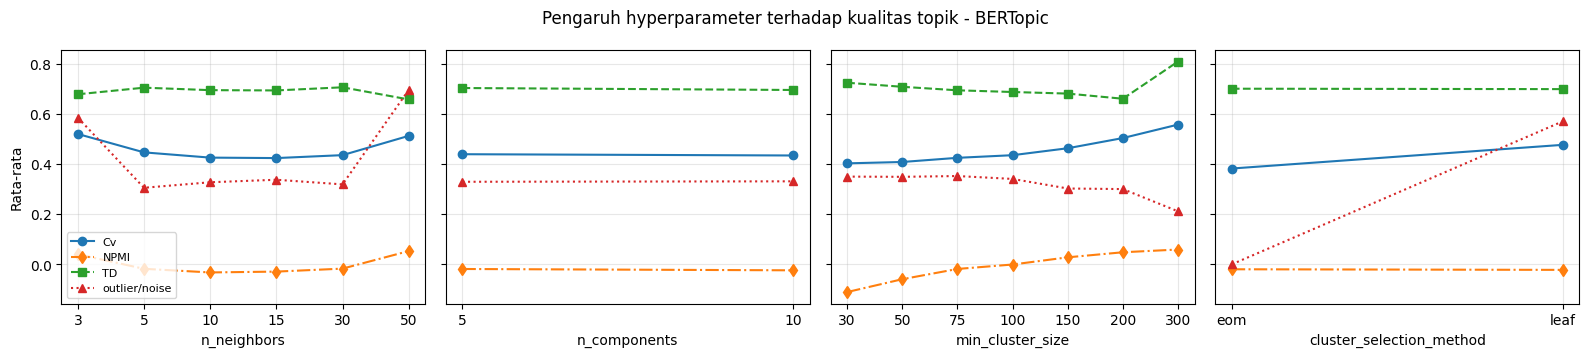

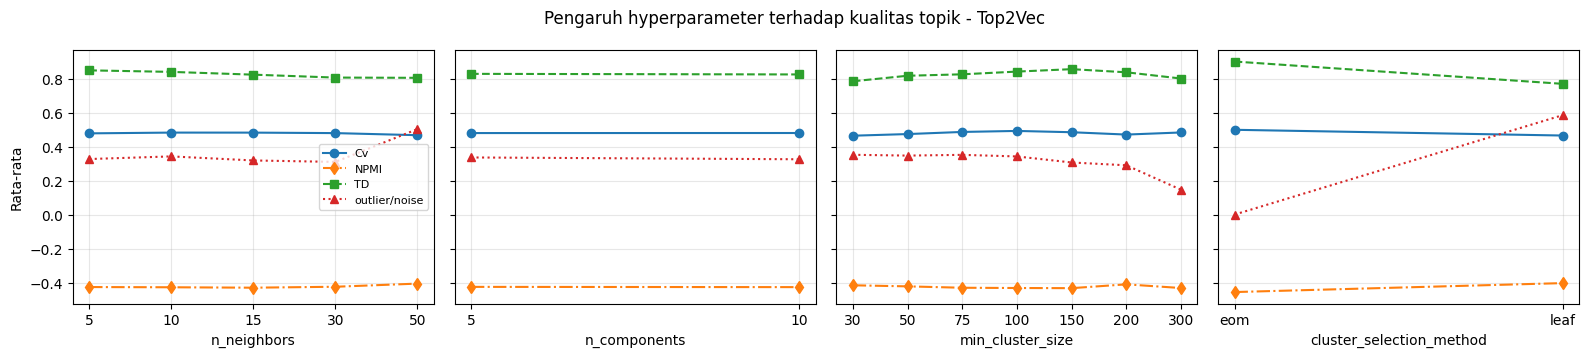

In [ ]:
def ringkas_pemilihan(nama, df_t, kolom_repr):
    terbaik, aturan, d = pilih_konfigurasi(df_t)
    baris = terbaik.iloc[0]
    params = bersihkan_tipe({k: baris[k] for k in list(GRID_KLASTER) + [kolom_repr]})
    d['pareto'] = False
    d.loc[d['layak'], 'pareto'] = tandai_pareto(d[d['layak']]) if d['layak'].any() else []
    d['terpilih'] = d['id_konfig'] == baris['id_konfig']
    d['alasan'] = np.where(d['terpilih'], f'TERPILIH: skor gabungan tertinggi di antara konfigurasi layak ({aturan})',
                  np.where(d['layak'], 'layak, skor gabungan lebih rendah',
                           'berhasil, tidak layak: ' + d['alasan_tidak_layak'].astype(str)))
    # kelompok hasil identik (konfigurasi berbeda, label dokumen sama persis)
    d['n_konfig_hasil_identik'] = d.groupby('sidik_label')['id_konfig'].transform('count')
    lain = df_t[df_t['status'] != 'berhasil'].copy()
    if len(lain):
        lain['layak'] = False; lain['terpilih'] = False; lain['pareto'] = False
        lain['alasan'] = lain['status'] + ': ' + lain['alasan_status'].astype(str)
    tabel = pd.concat([d, lain], ignore_index=True)
    print('=' * 70); print(f'KONFIGURASI TERPILIH {nama.upper()}'); print('=' * 70)
    print(f'  Aturan       : {aturan}')
    for k, v in params.items():
        print(f'  {k:<25}: {v}')
    for k in ['jumlah_topik', 'K_hdbscan', 'coherence_cv', 'coherence_npmi', 'topic_diversity', 'rasio_outlier']:
        print(f'  {k:<25}: {baris[k]:.4f}' if isinstance(baris[k], float) else f'  {k:<25}: {baris[k]}')
    st = df_t['status'].value_counts()
    print(f'  Status: berhasil {st.get("berhasil", 0)}, gagal {st.get("gagal", 0)}, dilewati {st.get("dilewati", 0)} '
          f'| layak {int(d["layak"].sum())}')
    n_identik = int(d.loc[d['terpilih'], 'n_konfig_hasil_identik'].iloc[0]) - 1
    print(f'  Konfigurasi lain dengan label dokumen identik: {n_identik}')
    batas = di_batas(baris, GRID_AKHIR[nama])
    for k, arah in batas.items():
        print(f'  PERHATIAN: {k}={params[k]} masih berada di batas {arah} rentang akhir {GRID_AKHIR[nama][k]} '
              '(tidak diperluas lagi; dicatat sebagai keterbatasan)')
    # catatan tertulis alasan pemilihan model final
    kol = list(GRID_KLASTER) + [kolom_repr, 'jumlah_topik', 'coherence_cv', 'coherence_npmi', 'topic_diversity',
                                'rasio_outlier', 'skor_gabungan']
    lima = d[d['layak']].sort_values(['skor_gabungan', 'rasio_outlier'], ascending=[False, True]).head(5)[kol]
    per_tahap = df_t.groupby(['tahap', 'status']).size().to_string()
    teks = [f'MODEL {nama}', f'Aturan seleksi: {aturan}',
            f'Ruang pencarian: {len(df_t)} konfigurasi unik', per_tahap,
            'Konfigurasi terpilih: ' + json.dumps(params),
            f"Metrik terpilih: K={baris['jumlah_topik']}, Cv={baris['coherence_cv']:.4f}, NPMI={baris['coherence_npmi']:.4f}, "
            f"TD={baris['topic_diversity']:.4f}, outlier/noise={baris['rasio_outlier']:.4f}, skor={baris['skor_gabungan']:.4f}",
            'Alasan: skor gabungan (Cv+TD)/2 tertinggi di antara konfigurasi yang memenuhi syarat layak; seri diputus '
            'dengan outlier lebih rendah. NPMI, K, dan outlier dilaporkan untuk setiap konfigurasi dan ditinjau di '
            'tabel sensitivitas.',
            'Lima konfigurasi layak teratas:', lima.to_string(index=False),
            'Batas rentang: ' + (', '.join(f'{k}={params[k]} di batas {a} rentang yang diuji {GRID_AKHIR[nama][k]} '
                                           '(tidak diperluas lagi; keterbatasan)' for k, a in batas.items()) or 'tidak di batas'), '']
    ALASAN_PEMILIHAN.append('\n'.join(teks))
    return params, baris, aturan, tabel

ALASAN_PEMILIHAN = []
params_bt,  baris_bt,  aturan_bt,  tabel_bt  = ringkas_pemilihan('BERTopic', df_tuning_bt, 'min_df')
params_t2v, baris_t2v, aturan_t2v, tabel_t2v = ringkas_pemilihan('Top2Vec', df_tuning_t2v, 'min_count')

tabel_tuning = pd.concat([tabel_bt, tabel_t2v], ignore_index=True)
KOLOM_DEPAN = ['model', 'tahap', 'status', 'alasan_status', 'pesan_error', 'layak', 'terpilih', 'pareto', 'alasan',
               *GRID_KLASTER, 'min_df', 'min_count', 'jumlah_topik', 'K_hdbscan', 'coherence_cv', 'coherence_npmi',
               'topic_diversity', 'rasio_outlier', 'outlier_terverifikasi', 'skor_gabungan', 'skor_dengan_npmi',
               'sidik_label', 'n_konfig_hasil_identik']
tabel_tuning = tabel_tuning[[c for c in KOLOM_DEPAN if c in tabel_tuning] +
                            [c for c in tabel_tuning if c not in KOLOM_DEPAN]]
tabel_tuning.to_csv(f'{OUTPUT_DIR}/tabel_tuning_lengkap.csv', index=False)
pd.DataFrame(LOG_EKSEKUSI).to_csv(f'{OUTPUT_DIR}/log_eksekusi_tuning.csv', index=False)
pd.DataFrame(LOG_PERLUASAN).to_csv(f'{OUTPUT_DIR}/log_perluasan_grid.csv', index=False)
with open(f'{OUTPUT_DIR}/alasan_pemilihan_model_final.txt', 'w') as f:
    f.write('\n'.join(ALASAN_PEMILIHAN))
print('\n' + '\n'.join(ALASAN_PEMILIHAN))
print(f'\nTabel seluruh konfigurasi yang diuji disimpan: {OUTPUT_DIR}/tabel_tuning_lengkap.csv')
print('Ringkasan status per model dan tahap:')
display(tabel_tuning.groupby(['model', 'tahap', 'status']).size().rename('jumlah').reset_index())
display(pd.DataFrame(LOG_PERLUASAN))

# ---- sensitivitas aturan seleksi: konfigurasi yang terpilih di bawah aturan lain (pilihan utama tidak berubah) ----
baris_sens = []
for nama, df_t in [('BERTopic', df_tuning_bt), ('Top2Vec', df_tuning_t2v)]:
    for skor in ['cv_td', 'cv_npmi_td']:
        for km in sorted(set(K_MIN_SENSITIVITAS) | {K_MIN}):
            try:
                tb, at, _ = pilih_konfigurasi(df_t, k_min=km, skor=skor)
                r = tb.iloc[0]
                baris_sens.append({'model': nama, 'skor': '(Cv+TD)/2' if skor == 'cv_td' else '(Cv+NPMI01+TD)/3',
                                   'K_MIN': km, 'aturan_utama': (km == K_MIN and skor == 'cv_td'),
                                   **{k: r[k] for k in GRID_KLASTER}, 'repr': r.get('min_df', r.get('min_count')),
                                   'jumlah_topik': r['jumlah_topik'], 'coherence_cv': r['coherence_cv'],
                                   'coherence_npmi': r['coherence_npmi'], 'topic_diversity': r['topic_diversity'],
                                   'rasio_outlier': r['rasio_outlier'], 'aturan': at})
            except RuntimeError as e:
                baris_sens.append({'model': nama, 'K_MIN': km, 'skor': skor, 'aturan': f'tidak ada kandidat: {e}'})
SENSITIVITAS_SELEKSI = pd.DataFrame(baris_sens)
print('\nSENSITIVITAS ATURAN SELEKSI (K_MIN=1 berarti tanpa batas jumlah topik)')
display(SENSITIVITAS_SELEKSI)
SENSITIVITAS_SELEKSI.to_csv(f'{OUTPUT_DIR}/sensitivitas_aturan_seleksi.csv', index=False)

for nama, d in [('BERTopic', tabel_bt), ('Top2Vec', tabel_t2v)]:
    d = d[d['status'] == 'berhasil']
    fig, axes = plt.subplots(1, len(GRID_KLASTER), figsize=(4 * len(GRID_KLASTER), 3.6), sharey=True)
    for ax, p in zip(np.atleast_1d(axes), GRID_KLASTER):
        rata = d.groupby(p)[['coherence_cv', 'coherence_npmi', 'topic_diversity', 'rasio_outlier']].mean()
        xs = range(len(rata))
        ax.plot(xs, rata['coherence_cv'], 'o-', label='Cv')
        ax.plot(xs, rata['coherence_npmi'], 'd-.', label='NPMI')
        ax.plot(xs, rata['topic_diversity'], 's--', label='TD')
        ax.plot(xs, rata['rasio_outlier'], '^:', label='outlier/noise')
        ax.set_xticks(list(xs)); ax.set_xticklabels([str(i) for i in rata.index]); ax.set_xlabel(p); ax.grid(alpha=0.3)
    np.atleast_1d(axes)[0].set_ylabel('Rata-rata'); np.atleast_1d(axes)[0].legend(fontsize=8)
    fig.suptitle(f'Pengaruh hyperparameter terhadap kualitas topik - {nama}')
    plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/pengaruh_parameter_{nama.lower()}.png', dpi=300, bbox_inches='tight')
    plt.show()


## 8. Model Final dan Evaluasi
### 8.1 Pelatihan Model Final
Model dilatih ulang dengan konfigurasi terpilih dan dicek sama dengan hasil tuning.

In [ ]:
VALIDASI = []   # diisi di berbagai bagian; diringkas di 12.0
def catat_validasi(bagian, pemeriksaan, lulus, rincian=''):
    VALIDASI.append({'bagian': bagian, 'pemeriksaan': pemeriksaan, 'lulus': bool(lulus), 'rincian': str(rincian)[:300]})
    print(f'[{"LULUS" if lulus else "GAGAL"}] {bagian}: {pemeriksaan} {("- " + str(rincian)) if rincian else ""}')

set_seed(SEED)
ev_bt_cek, keluaran_bt = latih_evaluasi('BERTopic', params_bt)
ev_t2v_cek, keluaran_t2v = latih_evaluasi('Top2Vec', params_t2v)
model_bt_alami, topics_bt_alami, kata_bt_alami = keluaran_bt['model'], keluaran_bt['topics'], keluaran_bt['kata']
model_t2v, kata_t2v, rep_t2v = keluaran_t2v['model'], keluaran_t2v['kata'], keluaran_t2v['replikasi']
doc_topik_t2v = np.array(model_t2v.doc_top)
assert len(topics_bt_alami) == len(doc_topik_t2v) == len(dokumen)
TOPICS_BT_ALAMI_ASLI = topics_bt_alami.copy()      # dipakai untuk memastikan label alami tidak berubah

# (a) parameter yang benar-benar dipakai model
ua_bt, ha_bt = pisah_parameter(params_bt, SEED)
try:
    verifikasi_parameter_bertopic(model_bt_alami, ua_bt, ha_bt, params_bt['min_df'])
    catat_validasi('8.1', 'BERTopic final memakai UMAP/HDBSCAN/min_df terpilih', True, json.dumps(params_bt))
except AssertionError as e:
    catat_validasi('8.1', 'BERTopic final memakai UMAP/HDBSCAN/min_df terpilih', False, e)
ua_t2v, ha_t2v = pisah_parameter(params_t2v, SEED)
cocok_t2v = (keluaran_t2v['umap_args'] == ua_t2v and keluaran_t2v['hdb_args'] == ha_t2v)
mc_model = getattr(model_t2v, 'min_count', None)
if mc_model is not None:
    cocok_t2v &= int(mc_model) == int(params_t2v['min_count'])
catat_validasi('8.1', 'Top2Vec final memakai UMAP/HDBSCAN/min_count terpilih', cocok_t2v,
               f'{json.dumps(params_t2v)}; min_count di objek model: {mc_model if mc_model is not None else "tidak disimpan library"}')

# (b) metrik final sama dengan baris tuning terpilih
for nama, ev, baris in [('BERTopic', ev_bt_cek, baris_bt), ('Top2Vec', ev_t2v_cek, baris_t2v)]:
    selisih = {k: abs(float(ev[k]) - float(baris[k])) for k in ['coherence_cv', 'coherence_npmi', 'topic_diversity']
               if pd.notna(baris[k])}
    if pd.notna(baris['rasio_outlier']) and pd.notna(ev['rasio_outlier']):
        selisih['rasio_outlier'] = abs(float(ev['rasio_outlier']) - float(baris['rasio_outlier']))
    sama = (ev['jumlah_topik'] == int(baris['jumlah_topik']) and max(selisih.values()) < 1e-3
            and ev['sidik_label'] == baris['sidik_label'])
    catat_validasi('8.1', f'{nama} final mereproduksi baris tuning terpilih', sama,
                   f'K={ev["jumlah_topik"]} (tuning {int(baris["jumlah_topik"])}), selisih maks {max(selisih.values()):.2e}, '
                   f'sidik_label {ev["sidik_label"]} vs {baris["sidik_label"]}')


[LULUS] 8.1: BERTopic final memakai UMAP/HDBSCAN/min_df terpilih - {"n_neighbors": 5, "n_components": 10, "min_cluster_size": 150, "cluster_selection_method": "leaf", "min_df": 10}
[LULUS] 8.1: Top2Vec final memakai UMAP/HDBSCAN/min_count terpilih - {"n_neighbors": 50, "n_components": 5, "min_cluster_size": 150, "cluster_selection_method": "leaf", "min_count": 5}; min_count di objek model: tidak disimpan library
[LULUS] 8.1: BERTopic final mereproduksi baris tuning terpilih - K=7 (tuning 7), selisih maks 3.47e-17, sidik_label bef1274aa2ca vs bef1274aa2ca
[LULUS] 8.1: Top2Vec final mereproduksi baris tuning terpilih - K=6 (tuning 6), selisih maks 0.00e+00, sidik_label ed543805fd8d vs ed543805fd8d


### 8.2 Evaluasi Model (Hasil Utama)
Outlier BERTopic = dokumen berlabel −1. Noise Top2Vec = noise HDBSCAN yang tetap ditempatkan ke topik terdekat.

EVALUASI MODEL (embedding IndoBERT yang sama)


,Model,Jenis Hasil,Konfigurasi,Jumlah Topik,Definisi Outlier,Jumlah Outlier,Rasio Outlier,Outlier Terverifikasi,Penyebut,Topic Coherence (Cv),Topic Coherence (NPMI),Topic Diversity,Kata Efektif Min,Kata Efektif Rata,Topik Tidak Dinilai
0,BERTopic,clustering asli (hasil utama),"{""n_neighbors"": 5, ""n_components"": 10, ""min_cl...",7,"label -1, tidak diberi topik",4786,0.3653,True,13101,0.5181,0.0565,0.70,10,10.0,0
1,Top2Vec,clustering asli (hasil utama),"{""n_neighbors"": 50, ""n_components"": 5, ""min_cl...",6,"noise HDBSCAN internal, tetap diberi topik ter...",6485,0.4950,True,13101,0.5268,-0.4397,0.85,10,10.0,0


[LULUS] 8.2: Tabel evaluasi BERTopic = hasil latih_evaluasi model final 
[LULUS] 8.2: Tabel evaluasi Top2Vec = hasil latih_evaluasi model final 
Median Cv per topik BERTopic = 0.5356 | Top2Vec = 0.5338
Median NPMI per topik BERTopic = 0.0721 | Top2Vec = -0.4551


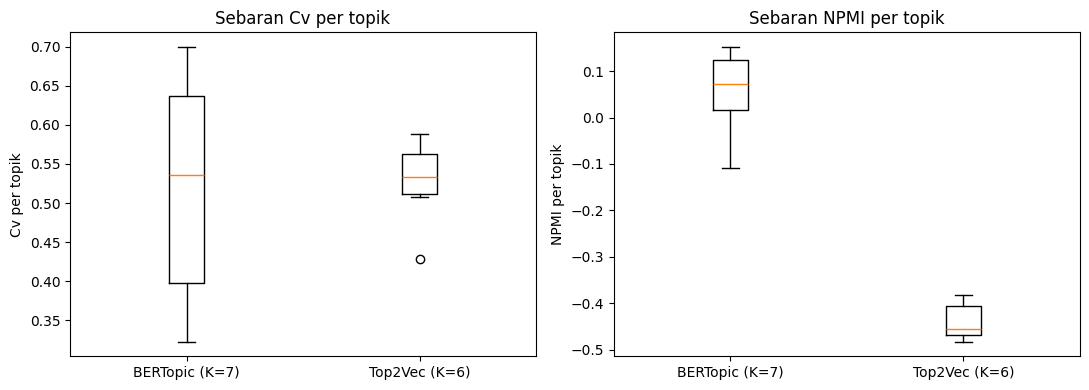

In [ ]:
eval_bt_alami = evaluasi_model([v['eval'] for v in kata_bt_alami.values()], per_topik=True)
eval_t2v = evaluasi_model([v['eval'] for v in kata_t2v.values()], per_topik=True)
N_UNIK = len(dokumen)
baris_eval = []
for nama, ev, params, out in [
        ('BERTopic', eval_bt_alami, params_bt,
         {'definisi': 'label -1, tidak diberi topik', 'n': int(np.sum(topics_bt_alami == -1)),
          'rasio': float(np.mean(topics_bt_alami == -1)), 'terverifikasi': True}),
        ('Top2Vec', eval_t2v, params_t2v,
         {'definisi': 'noise HDBSCAN internal, tetap diberi topik terdekat', 'n': rep_t2v['n_noise'],
          'rasio': rep_t2v['rasio_noise'], 'terverifikasi': rep_t2v['replikasi_terverifikasi']})]:
    baris_eval.append({'Model': nama, 'Jenis Hasil': 'clustering asli (hasil utama)',
                       'Konfigurasi': json.dumps(params), 'Jumlah Topik': ev['jumlah_topik'],
                       'Definisi Outlier': out['definisi'], 'Jumlah Outlier': out['n'],
                       'Rasio Outlier': round(out['rasio'], 4), 'Outlier Terverifikasi': out['terverifikasi'],
                       'Penyebut': N_UNIK, 'Topic Coherence (Cv)': round(ev['coherence_cv'], 4),
                       'Topic Coherence (NPMI)': round(ev['coherence_npmi'], 4),
                       'Topic Diversity': round(ev['topic_diversity'], 4),
                       'Kata Efektif Min': ev['kata_efektif_min'], 'Kata Efektif Rata': ev['kata_efektif_rata'],
                       'Topik Tidak Dinilai': ev['topik_tidak_dinilai']})
df_evaluasi = pd.DataFrame(baris_eval)
print('=' * 70); print('EVALUASI MODEL (embedding IndoBERT yang sama)'); print('=' * 70)
display(df_evaluasi)
df_evaluasi.to_csv(f'{OUTPUT_DIR}/hasil_evaluasi_alami.csv', index=False)
for nama, ev, ev_cek in [('BERTopic', eval_bt_alami, ev_bt_cek), ('Top2Vec', eval_t2v, ev_t2v_cek)]:
    catat_validasi('8.2', f'Tabel evaluasi {nama} = hasil latih_evaluasi model final',
                   all(abs(ev[k] - ev_cek[k]) < 1e-12 for k in ['coherence_cv', 'coherence_npmi', 'topic_diversity']))

cv_topik_bt, cv_topik_t2v = np.array(eval_bt_alami['cv_per_topik']), np.array(eval_t2v['cv_per_topik'])
print(f'Median Cv per topik BERTopic = {np.nanmedian(cv_topik_bt):.4f} | Top2Vec = {np.nanmedian(cv_topik_t2v):.4f}')
print(f'Median NPMI per topik BERTopic = {np.nanmedian(eval_bt_alami["npmi_per_topik"]):.4f} | '
      f'Top2Vec = {np.nanmedian(eval_t2v["npmi_per_topik"]):.4f}')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, kunci, judul in [(axes[0], 'cv_per_topik', 'Cv per topik'), (axes[1], 'npmi_per_topik', 'NPMI per topik')]:
    a, b = np.array(eval_bt_alami[kunci]), np.array(eval_t2v[kunci])
    ax.boxplot([a[~np.isnan(a)], b[~np.isnan(b)]])
    ax.set_xticks([1, 2]); ax.set_xticklabels([f'BERTopic (K={len(a)})', f'Top2Vec (K={len(b)})'])
    ax.set_ylabel(judul); ax.set_title(f'Sebaran {judul}')
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/sebaran_cv_per_topik.png', dpi=300, bbox_inches='tight'); plt.show()


### 8.3 Diagnostik Top2Vec
Jumlah klaster sebelum/sesudah penggabungan, anisotropi embedding, dan kata topik c-TF-IDF pada klaster Top2Vec yang
sama (untuk memisahkan pengaruh pemilihan kata dari pengelompokan).

In [ ]:
def ctfidf_kata(docs, label, min_df, topn=TOPN_EVAL):
    # memakai kosakata yang sama dengan BERTopic; label -1 (jika ada) ikut sebagai kelas, lalu tidak dilaporkan
    df_l = pd.DataFrame({'doc': docs, 'label': label})
    per = df_l.groupby('label')['doc'].apply(' '.join)       # dokumen sudah diakhiri penanda batas
    cv_ = buat_vectorizer(min_df if MIN_DF_TINGKAT == 'dokumen' else min(min_df, len(per)))
    X = cv_.fit_transform(per.values)
    ada = np.asarray(X.sum(axis=0)).ravel() > 0
    X = X[:, ada]
    c = ClassTfidfTransformer(reduce_frequent_words=True).fit_transform(X)
    vocab = np.array(cv_.get_feature_names_out())[ada]
    hasil = {}
    for baris_i, t in enumerate(per.index):
        if t == -1:
            continue
        skor = np.asarray(c[baris_i].todense()).ravel()
        urut = vocab[np.argsort(-skor)]
        hasil[int(t)] = {'tampil': list(urut[:topn]), 'eval': [w for w in urut if ' ' not in w][:topn]}
    return hasil

rng = np.random.default_rng(SEED)
def rata_cos_acak(M, n=3000):
    M = normalize(M); i, j = rng.integers(0, len(M), n), rng.integers(0, len(M), n)
    m = i != j
    return float(np.mean(np.sum(M[i[m]] * M[j[m]], axis=1)))

kata_t2v_ctfidf = ctfidf_kata(dokumen_batas, doc_topik_t2v, params_bt['min_df'])
eval_t2v_ctfidf = evaluasi_model([v['eval'] for v in kata_t2v_ctfidf.values()])
DIAG_T2V = {
    'versi_top2vec': VERSI['top2vec'], 'topic_merge_delta': TOP2VEC_MERGE_DELTA,
    'K_hdbscan_sebelum_merge': rep_t2v['K_hdbscan'], 'K_setelah_merge': rep_t2v['K_setelah_merge'],
    'rasio_noise_hdbscan': round(rep_t2v['rasio_noise'], 4), 'replikasi_terverifikasi': rep_t2v['replikasi_terverifikasi'],
    'cos_acak_dokumen': round(rata_cos_acak(embeddings_indobert), 4),
    'cos_acak_kata_top2vec': round(rata_cos_acak(model_t2v.word_vectors), 4),
    'ukuran_kosakata_top2vec': int(len(model_t2v.vocab)),
}
print('DIAGNOSTIK TOP2VEC'); print('-' * 60)
for k, v in DIAG_T2V.items():
    print(f'  {k:<28}: {v}')
banding_kata = pd.DataFrame([
    {'Representasi kata': 'Top2Vec bawaan (kata terdekat centroid)', **{k: eval_t2v[k] for k in ['jumlah_topik', 'coherence_cv', 'coherence_npmi', 'topic_diversity', 'kata_efektif_rata']}},
    {'Representasi kata': 'Top2Vec + c-TF-IDF (DIAGNOSTIK)', **{k: eval_t2v_ctfidf[k] for k in ['jumlah_topik', 'coherence_cv', 'coherence_npmi', 'topic_diversity', 'kata_efektif_rata']}},
    {'Representasi kata': 'BERTopic (c-TF-IDF)', **{k: eval_bt_alami[k] for k in ['jumlah_topik', 'coherence_cv', 'coherence_npmi', 'topic_diversity', 'kata_efektif_rata']}},
])
display(banding_kata)
banding_kata.to_csv(f'{OUTPUT_DIR}/diagnostik_top2vec_representasi_kata.csv', index=False)
json.dump(DIAG_T2V, open(f'{OUTPUT_DIR}/diagnostik_top2vec.json', 'w'), indent=2)
print('\nKata topik Top2Vec: bawaan vs c-TF-IDF diagnostik (6 kata pertama)')
for t in kata_t2v:
    print(f'  T{t:<2} bawaan : {", ".join(kata_t2v[t]["eval"][:6])}')
    print(f'      ctfidf : {", ".join(kata_t2v_ctfidf.get(t, {"eval": []})["eval"][:6])}')

DIAGNOSTIK TOP2VEC
------------------------------------------------------------
  versi_top2vec               : 1.0.36
  topic_merge_delta           : 0.1
  K_hdbscan_sebelum_merge     : 7
  K_setelah_merge             : 6
  rasio_noise_hdbscan         : 0.495
  replikasi_terverifikasi     : True
  cos_acak_dokumen            : 0.5445
  cos_acak_kata_top2vec       : 0.4695
  ukuran_kosakata_top2vec     : 1556


,Representasi kata,jumlah_topik,coherence_cv,coherence_npmi,topic_diversity,kata_efektif_rata
0,Top2Vec bawaan (kata terdekat centroid),6,0.526811,-0.439749,0.850000,10.0
1,Top2Vec + c-TF-IDF (DIAGNOSTIK),6,0.451581,0.050299,0.633333,10.0
2,BERTopic (c-TF-IDF),7,0.518053,0.056485,0.700000,10.0



Kata topik Top2Vec: bawaan vs c-TF-IDF diagnostik (6 kata pertama)
  T0  bawaan : tanpa_internet, jangan_sering, tidak_disarankan, cekatan, mendingan, bukan_mempermudah
      ctfidf : hari, gangguan, tidak_ada, internet, wifi, bayar
  T1  bawaan : tidak_nyala, berinovasi, berkedip, teksini, informatif, tidak_ada
      ctfidf : cepat, pemasangan, bagus, ramah, rapi, pelayanan
  T2  bawaan : tidak_diperbaiki, tanpa_internet, ganggu, whatsapp, tidak_connect, tidak_tau
      ctfidf : tidak_bisa, tidak_ada, sering, lambat, iconnet, aplikasi
  T3  bawaan : whatsapp, tidak_diperbaiki, ramah, tidak_ramah, waktu, myicon
      ctfidf : mantap, cepat, respon, bagus, icon, semakin
  T4  bawaan : mendingan, telpon, email, mengapai, percepat, masukan
      ctfidf : baik, cepat, pelayanan, membantu, ramah, mantap
  T5  bawaan : tidak_sesuai, oke, bukan_gratis, baik, tidak_ada, segitu
      ctfidf : mantap, oke, bagus, baik, terbaik, jos


### 8.4 Stabilitas antar-Seed
Uji awal dengan 5 seed. Uji 10 seed yang dilaporkan di paper ada di 14.1.

In [ ]:
STABILITAS = None
if JALANKAN_STABILITAS:
    baris_stab = []
    for nama, params, label_utama in [('BERTopic', params_bt, topics_bt_alami), ('Top2Vec', params_t2v, doc_topik_t2v)]:
        for s in SEED_STABILITAS:
            t0 = time.time()
            try:
                set_seed(s)
                ev, kel = latih_evaluasi(nama, params, seed=s)
                baris_stab.append({'model': nama, 'seed': s, 'status': 'berhasil', 'jumlah_topik': ev['jumlah_topik'],
                                   'coherence_cv': ev['coherence_cv'], 'coherence_npmi': ev['coherence_npmi'],
                                   'topic_diversity': ev['topic_diversity'], 'rasio_outlier': ev['rasio_outlier'],
                                   'ARI_vs_seed_utama': adjusted_rand_score(label_utama, kel['topics']),
                                   'waktu_detik': round(time.time() - t0, 1)})
            except Exception as e:
                baris_stab.append({'model': nama, 'seed': s, 'status': f'gagal: {type(e).__name__}: {e}'[:200]})
            print(baris_stab[-1])
    set_seed(SEED)
    df_stab = pd.DataFrame(baris_stab)
    df_stab.to_csv(f'{OUTPUT_DIR}/stabilitas_seed.csv', index=False)
    ok = df_stab[df_stab['status'] == 'berhasil']
    STABILITAS = ok.groupby('model')[['jumlah_topik', 'coherence_cv', 'coherence_npmi', 'topic_diversity',
                                      'rasio_outlier', 'ARI_vs_seed_utama']].agg(['mean', 'std', 'count'])
    display(STABILITAS)
    STABILITAS.to_csv(f'{OUTPUT_DIR}/stabilitas_ringkasan.csv')
else:
    print('Uji stabilitas tidak dijalankan. Hasil hanya dari satu seed; jangan mengklaim stabilitas.')

{'model': 'BERTopic', 'seed': 42, 'status': 'berhasil', 'jumlah_topik': 7, 'coherence_cv': 0.5180529013418829, 'coherence_npmi': 0.056484561302323634, 'topic_diversity': 0.7, 'rasio_outlier': 0.3653156247614686, 'ARI_vs_seed_utama': 1.0, 'waktu_detik': 17.9}
{'model': 'BERTopic', 'seed': 7, 'status': 'berhasil', 'jumlah_topik': 9, 'coherence_cv': 0.5271588576534222, 'coherence_npmi': 0.04611131961496762, 'topic_diversity': 0.6777777777777778, 'rasio_outlier': 0.592931837264331, 'ARI_vs_seed_utama': 0.3014246525181505, 'waktu_detik': 16.6}
{'model': 'BERTopic', 'seed': 123, 'status': 'berhasil', 'jumlah_topik': 8, 'coherence_cv': 0.5020652571498564, 'coherence_npmi': 0.04331459654656833, 'topic_diversity': 0.725, 'rasio_outlier': 0.3260819784749256, 'ARI_vs_seed_utama': 0.6389512216915384, 'waktu_detik': 16.2}
{'model': 'BERTopic', 'seed': 2024, 'status': 'berhasil', 'jumlah_topik': 8, 'coherence_cv': 0.5154155022218251, 'coherence_npmi': 0.039039216353986925, 'topic_diversity': 0.6875,

jumlah_topik                 coherence_cv                  \
                 mean       std count         mean       std count   
model                                                                
BERTopic          8.0  0.707107     5     0.518946  0.011587     5   
Top2Vec           6.2  0.447214     5     0.526639  0.007140     5   

         coherence_npmi                 topic_diversity                  \
                   mean       std count            mean       std count   
model                                                                     
BERTopic       0.044374  0.007662     5        0.693056  0.020365     5   
Top2Vec       -0.442349  0.006501     5        0.824286  0.043559     5   

         rasio_outlier                 ARI_vs_seed_utama                  
                  mean       std count              mean       std count  
model                                                                     
BERTopic       0.48865  0.144918     5          0.499997  0.318950     5  
Top2Vec        0.48033  0.022813     5          0.929025  0.063682     5

## 9. Identifikasi Topik
### 9.1 Tabel Topik dan Dokumen Representatif
Label dari tiga kata teratas; dokumen representatif = dokumen terdekat ke centroid topik.

In [ ]:
emb_norm = normalize(embeddings_indobert)
def dokumen_representatif(label, t, k=5):
    idx = np.where(label == t)[0]
    if len(idx) == 0:
        return []
    c = normalize(emb_norm[idx].mean(axis=0).reshape(1, -1))[0]
    return [dokumen[i] for i in idx[np.argsort(-(emb_norm[idx] @ c))][:k]]

def rep_bawaan_t2v(t, k=3):
    n = int(np.sum(doc_topik_t2v == t))
    _, _, ids = model_t2v.search_documents_by_topic(topic_num=int(t), num_docs=min(k, n))
    return [dokumen[int(i)] for i in ids]

def tabel_topik(nama, skenario, label, kata, ev, rep_bawaan=None):
    baris = []
    for posisi, t in enumerate(kata):          # urutan sama dengan urutan evaluasi
        n = int(np.sum(label == t))
        baris.append({'model': nama, 'skenario': skenario, 'topik': int(t), 'jumlah_dokumen_unik': n,
                      'persen_dari_unik': round(n / len(label) * 100, 2),
                      'kata_tampil': ', '.join(kata[t]['tampil']), 'kata_eval': ', '.join(kata[t]['eval']),
                      'cv_topik': ev['cv_per_topik'][posisi], 'kata_efektif': ev['kata_efektif_per_topik'][posisi],
                      'dok_rep_centroid': ' || '.join(d[:120] for d in dokumen_representatif(label, t, 3)),
                      'dok_rep_bawaan': ' || '.join(d[:120] for d in rep_bawaan(t)) if rep_bawaan else 'tidak dipakai'})
    if np.any(label == -1):
        n = int(np.sum(label == -1))
        baris.append({'model': nama, 'skenario': skenario, 'topik': -1, 'jumlah_dokumen_unik': n,
                      'persen_dari_unik': round(n / len(label) * 100, 2), 'kata_tampil': '(outlier)',
                      'kata_eval': '', 'cv_topik': np.nan, 'kata_efektif': 0,
                      'dok_rep_centroid': '', 'dok_rep_bawaan': ''})
    return pd.DataFrame(baris).sort_values('jumlah_dokumen_unik', ascending=False).reset_index(drop=True)

def rep_bawaan_bt(t):
    try:
        return model_bt_alami.get_representative_docs(t)[:3]
    except Exception:
        return []

SKENARIO_TOPIK = {
    'BERTopic':   ('BERTopic', 'default', topics_bt_alami, kata_bt_alami, eval_bt_alami, rep_bawaan_bt),
    'Top2Vec':    ('Top2Vec', 'default', doc_topik_t2v, kata_t2v, eval_t2v, rep_bawaan_t2v),
}
tabel_topik_semua = {}
for kunci, (nama, sk, label, kata, ev, rb) in SKENARIO_TOPIK.items():
    tb = tabel_topik(nama, sk, label, kata, ev, rb)
    tabel_topik_semua[kunci] = tb
    print('=' * 90); print(f'TOPIK {kunci.upper()} ({len(kata)} topik)'); print('=' * 90)
    for _, r in tb.iterrows():
        print(f'\nTopik {r["topik"]:>2} | {r["jumlah_dokumen_unik"]:>5} dokumen unik ({r["persen_dari_unik"]:>5.2f}%)')
        print(f'  Kata (tampil): {r["kata_tampil"]}')
        if r['topik'] != -1:
            print(f'  Kata (eval)  : {r["kata_eval"]}  | Cv={r["cv_topik"]:.3f}')
            print(f'  Contoh       : {r["dok_rep_centroid"][:200]}')
    tb.to_csv(f'{OUTPUT_DIR}/daftar_topik_{kunci.lower().replace(" ", "_")}.csv', index=False)

TOPIK BERTOPIC (7 topik)

Topik -1 |  4786 dokumen unik (36.53%)
  Kata (tampil): (outlier)

Topik  0 |  4718 dokumen unik (36.01%)
  Kata (tampil): hari, tidak_ada, bayar, gangguan, internet, wifi, bulan, laporan, jaringan, tidak_bisa
  Kata (eval)  : hari, tidak_ada, bayar, gangguan, internet, wifi, bulan, laporan, jaringan, tidak_bisa  | Cv=0.681
  Contoh       : aplikasi gangguan terus v terus kalau wifi masalah penanganan sudah pasti hari sampai hari baru solved saya sudah sering || lambat dalam proses gangguan jaringan kadang sudah buat kode laporan tapi be

Topik  1 |  1668 dokumen unik (12.73%)
  Kata (tampil): sering, tidak_ada, lambat, respon, tidak_bisa, gangguan, terus, wa, hari, iconnet
  Kata (eval)  : sering, tidak_ada, lambat, respon, tidak_bisa, gangguan, terus, wa, hari, iconnet  | Cv=0.592
  Contoh       : kenapa sih customer service by wa di hilangkan kalau by aplikasi sangat slowrespon keluhan internet lambat sudah hampir  || kacau sudah jam loss merah tidak ada pr

### 9.2 Distribusi Rating per Topik
Dihitung pada ulasan bermakna. Dominan keluhan: rating 1–2 ≥ 60%; dominan apresiasi: rating 4–5 ≥ 60%.

Penyebut: ulasan awal 28,267 | ulasan bermakna (termasuk duplikat) 16,166 | ulasan unik 13,101
RATING PER TOPIK - BERTOPIC


,topik,label_otomatis,jumlah_ulasan,ulasan_unik,persen_dari_bermakna,p_1,p_2,p_3,p_4,p_5,rata_rata_rating,kecenderungan
0,-1,outlier (tanpa topik),7156,4786,44.27,16.7,1.5,1.6,2.0,78.3,4.24,outlier
1,0,"T0: hari, tidak ada, bayar",4718,4718,29.18,74.7,6.1,4.3,3.2,11.7,1.71,dominan keluhan
2,1,"T1: sering, tidak ada, lambat",1670,1668,10.33,72.9,5.6,3.5,2.8,15.2,1.82,dominan keluhan
3,2,"T2: cepat, pemasangan, pemasangan cepat",1252,863,7.74,5.9,0.2,0.2,1.5,92.1,4.74,dominan apresiasi
4,6,"T6: oke, bagus, baik",438,182,2.71,0.9,0.0,0.2,1.6,97.3,4.94,dominan apresiasi
5,3,"T3: mantap, cepat, ramah",415,370,2.57,5.5,0.7,0.7,3.1,89.9,4.71,dominan apresiasi
6,4,"T4: mantap, baik, pelayanan",312,310,1.93,13.1,0.6,2.9,4.5,78.8,4.35,dominan apresiasi
7,5,"T5: membantu, aplikasi membantu, memudahkan",205,204,1.27,5.4,1.5,0.0,1.5,91.7,4.73,dominan apresiasi


RATING PER TOPIK - TOP2VEC


,topik,label_otomatis,jumlah_ulasan,ulasan_unik,persen_dari_bermakna,p_1,p_2,p_3,p_4,p_5,rata_rata_rating,kecenderungan
0,0,"T0: tanpa internet, jangan sering, tidak disar...",4804,4803,29.72,74.4,5.8,4.4,2.8,12.6,1.73,dominan keluhan
1,1,"T1: tidak nyala, berinovasi, berkedip",3966,2679,24.53,13.8,1.5,1.2,1.8,81.7,4.36,dominan apresiasi
2,5,"T5: tidak sesuai, oke, bukan gratis",2049,909,12.67,6.3,0.6,0.6,1.6,90.9,4.70,dominan apresiasi
3,2,"T2: tidak diperbaiki, tanpa internet, ganggu",1959,1926,12.12,66.5,5.5,3.4,2.6,22.1,2.08,dominan keluhan
4,3,"T3: whatsapp, tidak diperbaiki, ramah",1814,1392,11.22,13.3,1.1,1.1,2.8,81.7,4.38,dominan apresiasi
5,4,"T4: mendingan, telpon, email",1574,1392,9.74,19.0,1.3,1.9,3.2,74.6,4.13,dominan apresiasi


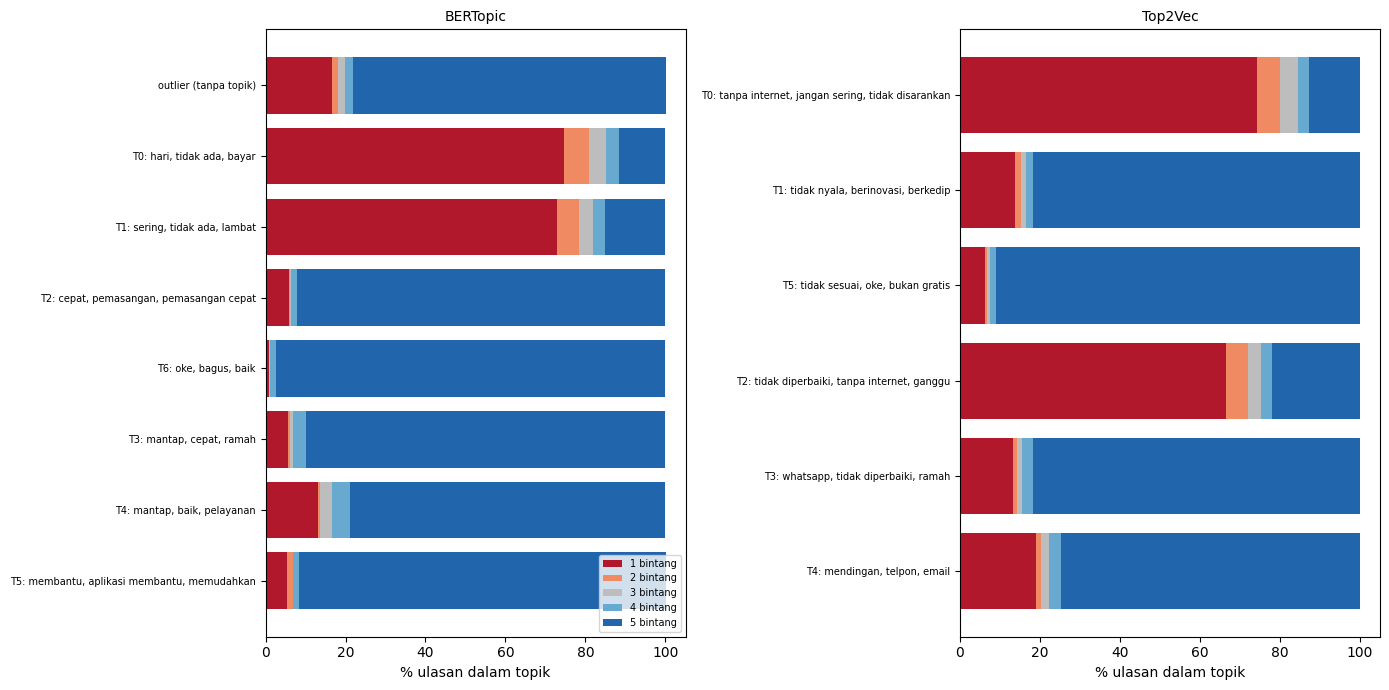

In [ ]:
def label_otomatis(kata, t):
    return 'outlier (tanpa topik)' if t == -1 else f'T{t}: ' + ', '.join(w.replace('_', ' ') for w in kata[t]['tampil'][:3])

def analisis_rating(kunci):
    nama, sk, label, kata, ev, _ = SKENARIO_TOPIK[kunci]
    peta = dict(zip(dokumen, label))
    d = df_semua_dasar.copy()
    d['topik'] = d['teks_embedding'].map(peta)
    assert d['topik'].notna().all(), 'Ada ulasan bermakna yang tidak terpetakan ke ulasan unik.'
    d['topik'] = d['topik'].astype(int)
    tab = pd.crosstab(d['topik'], d['rating']).reindex(columns=[1, 2, 3, 4, 5], fill_value=0)
    prop = tab.div(tab.sum(axis=1), axis=0)
    out = pd.DataFrame({'topik': tab.index, 'label_otomatis': [label_otomatis(kata, t) for t in tab.index],
                        'ulasan_unik': [int(np.sum(label == t)) for t in tab.index],
                        'jumlah_ulasan': tab.sum(axis=1).values})
    out['persen_dari_bermakna'] = (out['jumlah_ulasan'] / len(d) * 100).round(2)
    for r in [1, 2, 3, 4, 5]:
        out[f'n_{r}'] = tab[r].values
    for r in [1, 2, 3, 4, 5]:
        out[f'p_{r}'] = (prop[r].values * 100).round(1)
    out['rata_rata_rating'] = (tab.values @ np.arange(1, 6) / tab.sum(axis=1).values).round(2)
    out['persen_rating_1_2'] = (out['p_1'] + out['p_2']).round(1)
    out['persen_rating_4_5'] = (out['p_4'] + out['p_5']).round(1)
    out['kecenderungan'] = np.select([out['persen_rating_1_2'] >= 60, out['persen_rating_4_5'] >= 60],
                                     ['dominan keluhan', 'dominan apresiasi'], 'campuran')
    out.loc[out['topik'] == -1, 'kecenderungan'] = 'outlier'
    out = out.sort_values('jumlah_ulasan', ascending=False).reset_index(drop=True)
    d['label'] = d['topik'].map(dict(zip(out['topik'], out['label_otomatis'])))
    d['kecenderungan'] = d['topik'].map(dict(zip(out['topik'], out['kecenderungan'])))
    return out, d

RATING, DOK_SEMUA = {}, {}
print(f'Penyebut: ulasan awal {N_AWAL:,} | ulasan bermakna (termasuk duplikat) {len(df_semua_dasar):,} | '
      f'ulasan unik {N_UNIK:,}')
for kunci in SKENARIO_TOPIK:
    RATING[kunci], DOK_SEMUA[kunci] = analisis_rating(kunci)
    print('=' * 90); print(f'RATING PER TOPIK - {kunci.upper()}'); print('=' * 90)
    display(RATING[kunci][['topik', 'label_otomatis', 'jumlah_ulasan', 'ulasan_unik', 'persen_dari_bermakna',
                            'p_1', 'p_2', 'p_3', 'p_4', 'p_5', 'rata_rata_rating', 'kecenderungan']])
    RATING[kunci].to_csv(f'{OUTPUT_DIR}/rating_per_topik_{kunci.lower().replace(" ", "_")}.csv', index=False)

fig, axes = plt.subplots(1, len(RATING), figsize=(7 * len(RATING), 7))
for ax, (kunci, tb) in zip(np.atleast_1d(axes), RATING.items()):
    tb = tb.iloc[::-1]
    kiri = np.zeros(len(tb))
    for r, warna in zip([1, 2, 3, 4, 5], ['#b2182b', '#ef8a62', '#bdbdbd', '#67a9cf', '#2166ac']):
        ax.barh(tb['label_otomatis'], tb[f'p_{r}'], left=kiri, color=warna, label=f'{r} bintang')
        kiri += tb[f'p_{r}'].values
    ax.set_xlabel('% ulasan dalam topik'); ax.set_title(kunci, fontsize=10); ax.tick_params(axis='y', labelsize=7)
np.atleast_1d(axes)[0].legend(fontsize=7, loc='lower right')
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/rating_per_topik.png', dpi=300, bbox_inches='tight'); plt.show()

### 9.3 Distribusi Topik per Tahun
Persentase terhadap ulasan bermakna per tahun; outlier BERTopic dihitung sebagai satu kategori.

LIMA TOPIK TERATAS SETIAP TAHUN - BERTOPIC

Tahun 2023 (4,705 ulasan bermakna)
  1. outlier (tanpa topik)                               2556 ulasan (54.33%)
  2. T0: hari, tidak ada, bayar                          1024 ulasan (21.76%)
  3. T2: cepat, pemasangan, pemasangan cepat              401 ulasan ( 8.52%)
  4. T1: sering, tidak ada, lambat                        300 ulasan ( 6.38%)
  5. T6: oke, bagus, baik                                 145 ulasan ( 3.08%)

Tahun 2024 (7,200 ulasan bermakna)
  1. outlier (tanpa topik)                               2980 ulasan (41.39%)
  2. T0: hari, tidak ada, bayar                          2181 ulasan (30.29%)
  3. T1: sering, tidak ada, lambat                        851 ulasan (11.82%)
  4. T2: cepat, pemasangan, pemasangan cepat              532 ulasan ( 7.39%)
  5. T3: mantap, cepat, ramah                             204 ulasan ( 2.83%)

Tahun 2025 (3,553 ulasan bermakna)
  1. outlier (tanpa topik)                               1371 ulasan 

kecenderungan,dominan apresiasi,dominan keluhan,outlier
tahun,,,
2023,17.53,28.14,54.33
2024,16.50,42.11,41.39
2025,14.21,47.20,38.59
2026,14.69,50.14,35.17


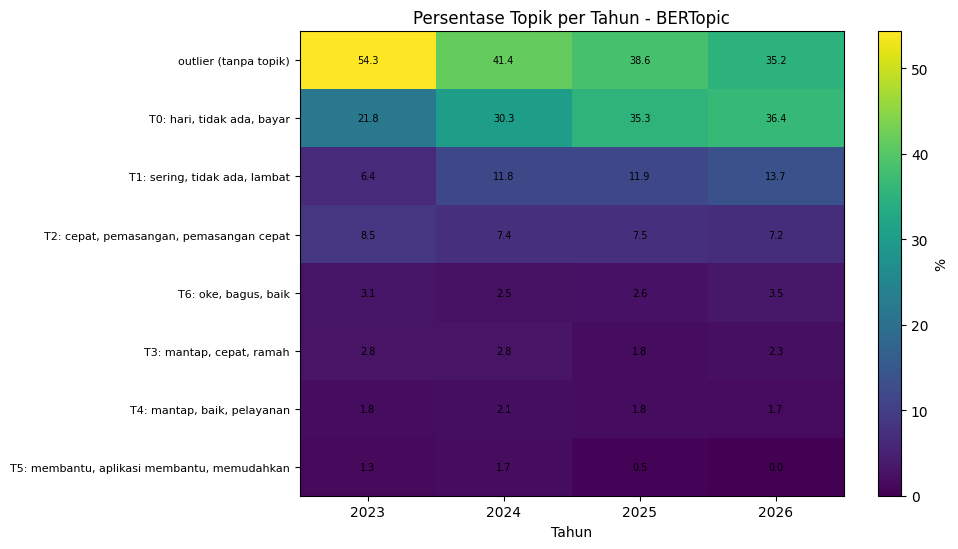

LIMA TOPIK TERATAS SETIAP TAHUN - TOP2VEC

Tahun 2023 (4,705 ulasan bermakna)
  1. T1: tidak nyala, berinovasi, berkedip               1333 ulasan (28.33%)
  2. T0: tanpa internet, jangan sering, tidak disarankan  1028 ulasan (21.85%)
  3. T5: tidak sesuai, oke, bukan gratis                  873 ulasan (18.55%)
  4. T3: whatsapp, tidak diperbaiki, ramah                697 ulasan (14.81%)
  5. T2: tidak diperbaiki, tanpa internet, ganggu         392 ulasan ( 8.33%)

Tahun 2024 (7,200 ulasan bermakna)
  1. T0: tanpa internet, jangan sering, tidak disarankan  2249 ulasan (31.24%)
  2. T1: tidak nyala, berinovasi, berkedip               1765 ulasan (24.51%)
  3. T2: tidak diperbaiki, tanpa internet, ganggu         991 ulasan (13.76%)
  4. T3: whatsapp, tidak diperbaiki, ramah                773 ulasan (10.74%)
  5. T4: mendingan, telpon, email                         759 ulasan (10.54%)

Tahun 2025 (3,553 ulasan bermakna)
  1. T0: tanpa internet, jangan sering, tidak disarankan  1273 ulasa

kecenderungan,dominan apresiasi,dominan keluhan
tahun,,
2023,69.82,30.18
2024,55.00,45.00
2025,50.80,49.20
2026,49.86,50.14


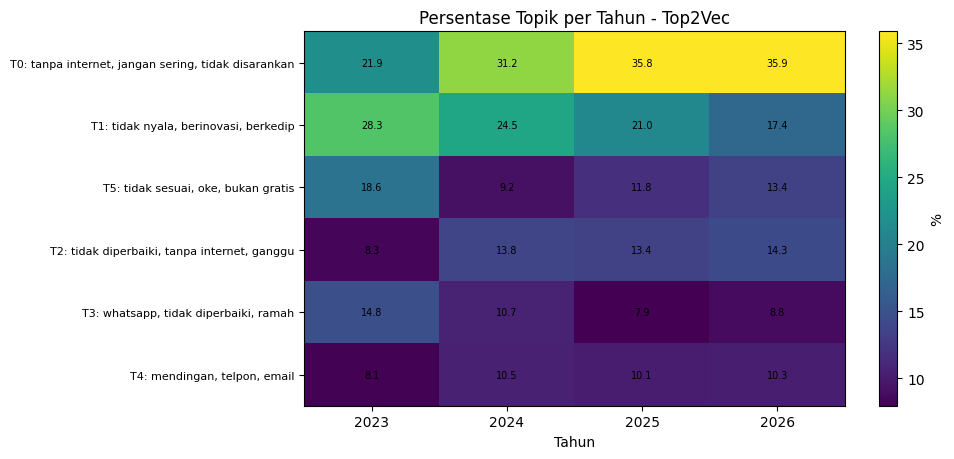

In [ ]:
TREN = {}
for kunci, d in DOK_SEMUA.items():
    jumlah = pd.crosstab(d['label'], d['tahun'])
    urutan = jumlah.sum(axis=1).sort_values(ascending=False).index
    persen = (pd.crosstab(d['label'], d['tahun'], normalize='columns') * 100).round(2).loc[urutan]
    jumlah = jumlah.loc[urutan]
    tag = kunci.lower().replace(' ', '_')
    jumlah.to_csv(f'{OUTPUT_DIR}/topik_per_tahun_jumlah_{tag}.csv'); persen.to_csv(f'{OUTPUT_DIR}/topik_per_tahun_persen_{tag}.csv')
    print('=' * 80); print(f'LIMA TOPIK TERATAS SETIAP TAHUN - {kunci.upper()}'); print('=' * 80)
    for th in persen.columns:
        print(f'\nTahun {int(th)} ({int(jumlah[th].sum()):,} ulasan bermakna)')
        for i, (lbl, p) in enumerate(persen[th].sort_values(ascending=False).head(5).items(), 1):
            print(f'  {i}. {lbl:<50} {jumlah.loc[lbl, th]:>5} ulasan ({p:5.2f}%)')
    TREN[kunci] = (pd.crosstab(d['tahun'], d['kecenderungan'], normalize='index') * 100).round(2)
    print(f'\nPROPORSI KECENDERUNGAN PER TAHUN (%) - {kunci}'); display(TREN[kunci])
    TREN[kunci].to_csv(f'{OUTPUT_DIR}/tren_kecenderungan_{tag}.csv')

    fig, ax = plt.subplots(figsize=(10, 0.45 * len(persen) + 2))
    im = ax.imshow(persen.values, aspect='auto')
    ax.set_xticks(range(len(persen.columns))); ax.set_xticklabels([int(t) for t in persen.columns])
    ax.set_yticks(range(len(persen.index))); ax.set_yticklabels(persen.index, fontsize=8)
    for i in range(persen.shape[0]):
        for j in range(persen.shape[1]):
            ax.text(j, i, f'{persen.values[i, j]:.1f}', ha='center', va='center', fontsize=7)
    ax.set_xlabel('Tahun'); ax.set_title(f'Persentase Topik per Tahun - {kunci}')
    fig.colorbar(im, ax=ax, label='%'); plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/topik_per_tahun_{tag}.png', dpi=300, bbox_inches='tight'); plt.show()

## 10. Perbandingan Topik BERTopic dan Top2Vec
Pasangan topik dicari dengan algoritma Hungaria.

### 10.1 Kesamaan Kata Topik (Jaccard)

PASANGAN SATU-SATU (HUNGARIA) BERDASARKAN JACCARD


,BERTopic,Top2Vec,nilai,kategori,label_BERTopic,label_Top2Vec
0,0,0,0.052632,tanpa padanan leksikal,"T0: hari, tidak ada, bayar","T0: tanpa internet, jangan sering, tidak disar..."
1,1,1,0.052632,tanpa padanan leksikal,"T1: sering, tidak ada, lambat","T1: tidak nyala, berinovasi, berkedip"
2,2,2,0.000000,tanpa padanan leksikal,"T2: cepat, pemasangan, pemasangan cepat","T2: tidak diperbaiki, tanpa internet, ganggu"
3,3,3,0.052632,tanpa padanan leksikal,"T3: mantap, cepat, ramah","T3: whatsapp, tidak diperbaiki, ramah"
4,4,4,0.000000,tanpa padanan leksikal,"T4: mantap, baik, pelayanan","T4: mendingan, telpon, email"
5,6,5,0.111111,padanan sebagian,"T6: oke, bagus, baik","T5: tidak sesuai, oke, bukan gratis"


Rata-rata Jaccard pasangan: 0.045 | rata-rata seluruh pasangan: 0.018
Padanan terbaik per arah (deskriptif): BERTopic->Top2Vec 0.061, Top2Vec->BERTopic 0.045 (arah kedua memilih dari 7 kandidat)


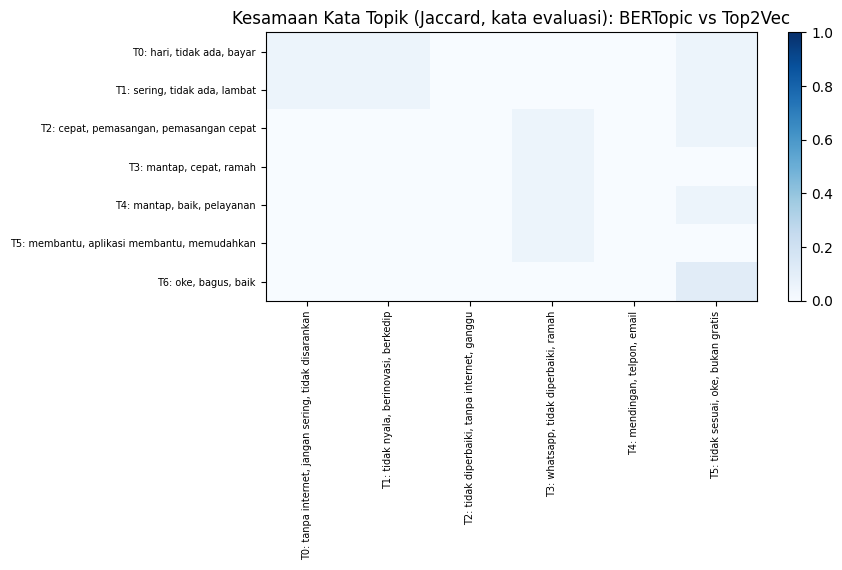

In [ ]:
AMBANG_KUAT, AMBANG_SEBAGIAN = 0.30, 0.10
kata_eval_bt  = {t: set(v['eval']) for t, v in kata_bt_alami.items()}
kata_eval_t2v = {t: set(v['eval']) for t, v in kata_t2v.items()}
lbl_bt  = {t: label_otomatis(kata_bt_alami, t) for t in kata_bt_alami}
lbl_t2v = {t: label_otomatis(kata_t2v, t) for t in kata_t2v}

jaccard = pd.DataFrame([[len(a & b) / len(a | b) if (a | b) else 0.0 for b in kata_eval_t2v.values()]
                        for a in kata_eval_bt.values()], index=list(kata_eval_bt), columns=list(kata_eval_t2v))
def kategori(j):
    return 'padanan kuat' if j >= AMBANG_KUAT else ('padanan sebagian' if j >= AMBANG_SEBAGIAN else 'tanpa padanan leksikal')

def cocok_hungaria(S):
    r, c = linear_sum_assignment(-S.values)
    return pd.DataFrame({'BERTopic': S.index[r], 'Top2Vec': S.columns[c], 'nilai': S.values[r, c]})

pas_j = cocok_hungaria(jaccard)
pas_j['kategori'] = pas_j['nilai'].apply(kategori)
pas_j['label_BERTopic'] = pas_j['BERTopic'].map(lbl_bt); pas_j['label_Top2Vec'] = pas_j['Top2Vec'].map(lbl_t2v)
print('PASANGAN SATU-SATU (HUNGARIA) BERDASARKAN JACCARD'); display(pas_j)
print(f'Rata-rata Jaccard pasangan: {pas_j["nilai"].mean():.3f} | rata-rata seluruh pasangan: {jaccard.values.mean():.3f}')
print(f'Padanan terbaik per arah (deskriptif): BERTopic->Top2Vec {jaccard.max(axis=1).mean():.3f}, '
      f'Top2Vec->BERTopic {jaccard.max(axis=0).mean():.3f} (arah kedua memilih dari {len(kata_eval_bt)} kandidat)')
jaccard.to_csv(f'{OUTPUT_DIR}/jaccard_topik.csv'); pas_j.to_csv(f'{OUTPUT_DIR}/pasangan_jaccard.csv', index=False)

fig, ax = plt.subplots(figsize=(0.5 * jaccard.shape[1] + 6, 0.4 * jaccard.shape[0] + 3))
im = ax.imshow(jaccard.values, aspect='auto', cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(jaccard.shape[1])); ax.set_xticklabels([lbl_t2v[t] for t in jaccard.columns], rotation=90, fontsize=7)
ax.set_yticks(range(jaccard.shape[0])); ax.set_yticklabels([lbl_bt[t] for t in jaccard.index], fontsize=7)
ax.set_title('Kesamaan Kata Topik (Jaccard, kata evaluasi): BERTopic vs Top2Vec'); fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/jaccard_topik.png', dpi=300, bbox_inches='tight'); plt.show()

### 10.2 Kesepakatan Pengelompokan Dokumen (ARI dan NMI)
Dihitung pada dokumen yang bukan outlier BERTopic dan bukan noise Top2Vec.

,kondisi,aturan,n_dokumen,persen_dari_unik,ARI,NMI,tafsir_ARI,tafsir_NMI
0,dokumen yang dikelompokkan kedua model,bukan outlier BERTopic DAN bukan noise Top2Vec,5882,44.9,0.890067,0.85073,kuat,kuat


ARI dikoreksi untuk kebetulan dan peka terhadap perbedaan jumlah serta ukuran kelompok; NMI tidak dikoreksi untuk kebetulan. Keduanya dibaca bersama tabel sebaran dokumen di bawah.

KE MANA DOKUMEN SETIAP TOPIK BERTOPIC DITEMPATKAN OLEH TOP2VEC (kondisi A)


,topik_BERTopic,topik_Top2Vec_dominan,persen_dokumen_ke_sana,tersebar_ke_n_topik_>=10%
0,"T0: hari, tidak ada, bayar","T0: tanpa internet, jangan sering, tidak disar...",94.4,1
1,"T1: sering, tidak ada, lambat","T2: tidak diperbaiki, tanpa internet, ganggu",94.6,1
2,"T2: cepat, pemasangan, pemasangan cepat","T1: tidak nyala, berinovasi, berkedip",97.7,1
3,"T3: mantap, cepat, ramah","T3: whatsapp, tidak diperbaiki, ramah",99.2,1
4,"T4: mantap, baik, pelayanan","T4: mendingan, telpon, email",100.0,1
5,"T5: membantu, aplikasi membantu, memudahkan","T0: tanpa internet, jangan sering, tidak disar...",50.0,2
6,"T6: oke, bagus, baik","T5: tidak sesuai, oke, bukan gratis",99.2,1


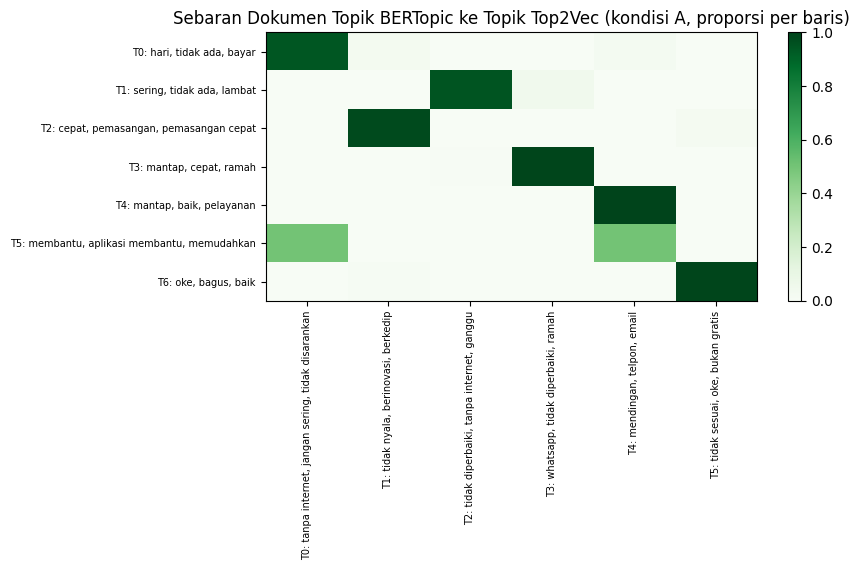

In [ ]:
def tafsir(v):
    return 'kuat' if v >= 0.5 else ('sedang' if v >= 0.3 else ('lemah' if v >= 0.1 else 'sangat lemah'))

mask_A = topics_bt_alami != -1
if rep_t2v['replikasi_terverifikasi']:
    mask_A &= rep_t2v['label_hdbscan'] != -1
    ket_A = 'bukan outlier BERTopic DAN bukan noise Top2Vec'
else:
    ket_A = 'bukan outlier BERTopic (noise Top2Vec tidak terverifikasi, tidak dipakai)'
KESEPAKATAN = pd.DataFrame([
    {'kondisi': 'dokumen yang dikelompokkan kedua model', 'aturan': ket_A, 'n_dokumen': int(mask_A.sum()), 'persen_dari_unik': round(mask_A.mean() * 100, 2),
     'ARI': adjusted_rand_score(topics_bt_alami[mask_A], doc_topik_t2v[mask_A]) if mask_A.sum() > 1 else np.nan,
     'NMI': normalized_mutual_info_score(topics_bt_alami[mask_A], doc_topik_t2v[mask_A]) if mask_A.sum() > 1 else np.nan},
    ])
KESEPAKATAN['tafsir_ARI'] = KESEPAKATAN['ARI'].apply(tafsir); KESEPAKATAN['tafsir_NMI'] = KESEPAKATAN['NMI'].apply(tafsir)
display(KESEPAKATAN)
KESEPAKATAN.to_csv(f'{OUTPUT_DIR}/kesepakatan_ari_nmi.csv', index=False)
print('ARI dikoreksi untuk kebetulan dan peka terhadap perbedaan jumlah serta ukuran kelompok; NMI tidak dikoreksi '
      'untuk kebetulan. Keduanya dibaca bersama tabel sebaran dokumen di bawah.')

kontingensi = pd.crosstab(pd.Series(topics_bt_alami[mask_A], name='BERTopic'), pd.Series(doc_topik_t2v[mask_A], name='Top2Vec'))
kontingensi.to_csv(f'{OUTPUT_DIR}/kontingensi_dokumen_kondisi_A.csv')
overlap_bt = kontingensi.div(kontingensi.sum(axis=1), axis=0)
sebaran = pd.DataFrame({'topik_BERTopic': [lbl_bt[t] for t in overlap_bt.index],
                        'topik_Top2Vec_dominan': [lbl_t2v[t] for t in overlap_bt.idxmax(axis=1)],
                        'persen_dokumen_ke_sana': (overlap_bt.max(axis=1) * 100).round(1).values,
                        'tersebar_ke_n_topik_>=10%': (overlap_bt >= 0.10).sum(axis=1).values})
print('\nKE MANA DOKUMEN SETIAP TOPIK BERTOPIC DITEMPATKAN OLEH TOP2VEC (kondisi A)'); display(sebaran)
sebaran.to_csv(f'{OUTPUT_DIR}/sebaran_dokumen_kondisi_A.csv', index=False)

fig, ax = plt.subplots(figsize=(0.5 * overlap_bt.shape[1] + 6, 0.4 * overlap_bt.shape[0] + 3))
im = ax.imshow(overlap_bt.values, aspect='auto', cmap='Greens', vmin=0, vmax=1)
ax.set_xticks(range(overlap_bt.shape[1])); ax.set_xticklabels([lbl_t2v[t] for t in overlap_bt.columns], rotation=90, fontsize=7)
ax.set_yticks(range(overlap_bt.shape[0])); ax.set_yticklabels([lbl_bt[t] for t in overlap_bt.index], fontsize=7)
ax.set_title('Sebaran Dokumen Topik BERTopic ke Topik Top2Vec (kondisi A, proporsi per baris)'); fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/overlap_dokumen.png', dpi=300, bbox_inches='tight'); plt.show()

### 10.3 Kemiripan Semantik Topik
Analisis pelengkap (tidak dilaporkan di paper): kata topik dikodekan dengan `paraphrase-multilingual-mpnet-base-v2`,
isi topik dengan centroid IndoBERT setelah mean-centering.

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.12k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

... (10 outputs left out)


PASANGAN HUNGARIA - ISI DOKUMEN


,BERTopic,Top2Vec,nilai,label_BERTopic,label_Top2Vec,centroid_tidak_stabil
0,0,0,0.996195,"T0: hari, tidak ada, bayar","T0: tanpa internet, jangan sering, tidak disar...",False
1,1,2,0.993057,"T1: sering, tidak ada, lambat","T2: tidak diperbaiki, tanpa internet, ganggu",False
2,2,1,0.938273,"T2: cepat, pemasangan, pemasangan cepat","T1: tidak nyala, berinovasi, berkedip",False
3,3,3,0.982018,"T3: mantap, cepat, ramah","T3: whatsapp, tidak diperbaiki, ramah",False
4,4,4,0.980201,"T4: mantap, baik, pelayanan","T4: mendingan, telpon, email",False
5,6,5,0.934123,"T6: oke, bagus, baik","T5: tidak sesuai, oke, bukan gratis",False


,aspek,rata_pasangan_hungaria,rata_seluruh_pasangan,terbaik_BERTopic_ke_Top2Vec,terbaik_Top2Vec_ke_BERTopic
0,kata topik,0.870,0.828,0.902,0.886
1,isi dokumen,0.971,0.019,0.919,0.971


Centroid tidak stabil (norma < 25% median): tidak ada


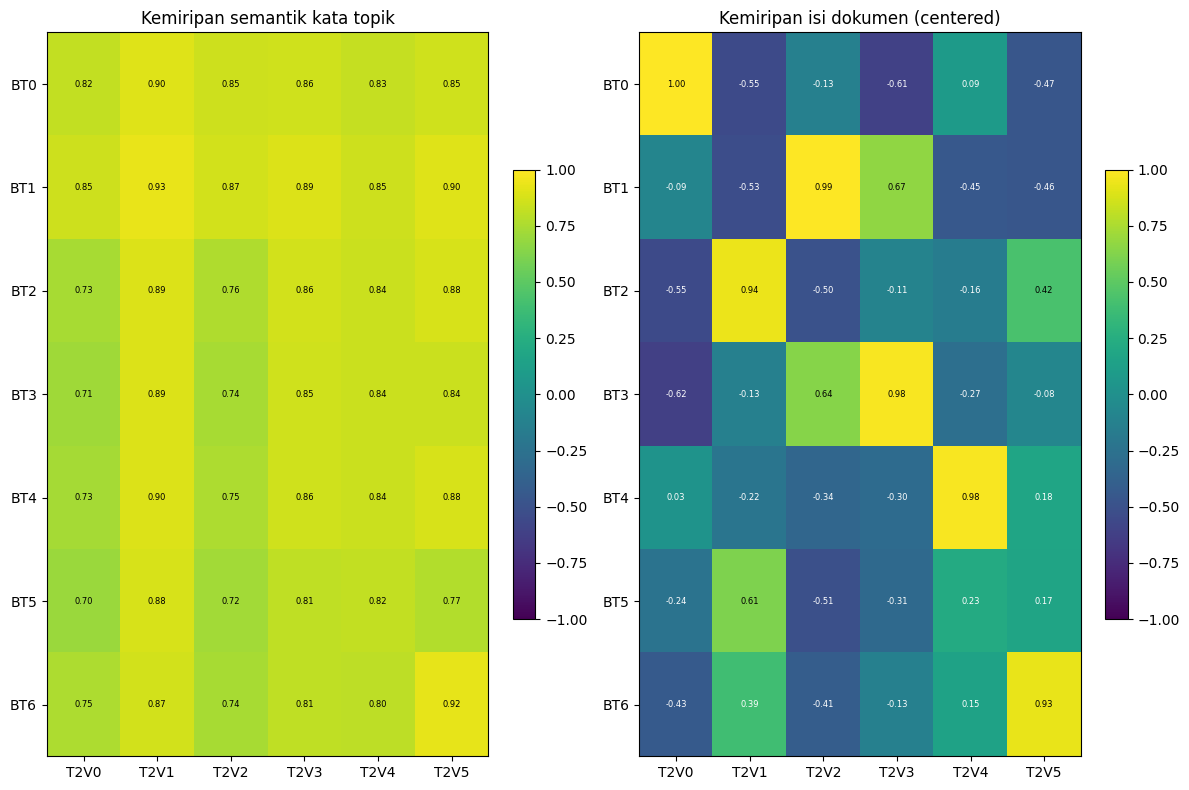

In [ ]:
model_semantik = SentenceTransformer(NAMA_MODEL_SEMANTIK, device=DEVICE)
def vektor_kata_topik(kata):
    return {t: normalize(normalize(model_semantik.encode([w.replace('_', ' ') for w in v['eval']], convert_to_numpy=True))
                         .mean(axis=0).reshape(1, -1))[0] for t, v in kata.items()}
vk_bt, vk_t2v = vektor_kata_topik(kata_bt_alami), vektor_kata_topik(kata_t2v)

emb_c = embeddings_indobert - embeddings_indobert.mean(axis=0)
def centroid_topik(label, ids):
    mentah = {t: emb_c[label == t].mean(axis=0) for t in ids}
    norma = {t: float(np.linalg.norm(v)) for t, v in mentah.items()}
    return {t: v / (norma[t] or 1.0) for t, v in mentah.items()}, norma
vd_bt, norma_bt = centroid_topik(topics_bt_alami, list(kata_bt_alami))
vd_t2v, norma_t2v = centroid_topik(doc_topik_t2v, list(kata_t2v))
median_norma = np.median(list(norma_bt.values()) + list(norma_t2v.values()))
tidak_stabil = {('BERTopic', t) for t, n in norma_bt.items() if n < 0.25 * median_norma} | \
               {('Top2Vec', t) for t, n in norma_t2v.items() if n < 0.25 * median_norma}

def matriks(va, vb):
    return pd.DataFrame([[float(va[a] @ vb[b]) for b in vb] for a in va], index=list(va), columns=list(vb))
sim_kata, sim_dok = matriks(vk_bt, vk_t2v), matriks(vd_bt, vd_t2v)

ringkas_sem = []
for nama_m, S in [('kata topik', sim_kata), ('isi dokumen', sim_dok)]:
    p = cocok_hungaria(S)
    ringkas_sem.append({'aspek': nama_m, 'rata_pasangan_hungaria': round(p['nilai'].mean(), 3),
                        'rata_seluruh_pasangan': round(S.values.mean(), 3),
                        'terbaik_BERTopic_ke_Top2Vec': round(S.max(axis=1).mean(), 3),
                        'terbaik_Top2Vec_ke_BERTopic': round(S.max(axis=0).mean(), 3)})
    p['label_BERTopic'] = p['BERTopic'].map(lbl_bt); p['label_Top2Vec'] = p['Top2Vec'].map(lbl_t2v)
    p['centroid_tidak_stabil'] = [('BERTopic', a) in tidak_stabil or ('Top2Vec', b) in tidak_stabil
                                  for a, b in zip(p['BERTopic'], p['Top2Vec'])]
    print(f'\nPASANGAN HUNGARIA - {nama_m.upper()}'); display(p)
    p.to_csv(f'{OUTPUT_DIR}/pasangan_semantik_{nama_m.replace(" ", "_")}.csv', index=False)
RINGKAS_SEMANTIK = pd.DataFrame(ringkas_sem)
display(RINGKAS_SEMANTIK)
print(f'Centroid tidak stabil (norma < 25% median): {sorted(tidak_stabil) if tidak_stabil else "tidak ada"}')
sim_kata.to_csv(f'{OUTPUT_DIR}/matriks_semantik_kata.csv'); sim_dok.to_csv(f'{OUTPUT_DIR}/matriks_semantik_dokumen.csv')
RINGKAS_SEMANTIK.to_csv(f'{OUTPUT_DIR}/ringkasan_semantik.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 8))
for ax, (judul, m) in zip(axes, [('Kemiripan semantik kata topik', sim_kata), ('Kemiripan isi dokumen (centered)', sim_dok)]):
    im = ax.imshow(m.values, cmap='viridis', aspect='auto', vmin=-1, vmax=1)
    ax.set_xticks(range(m.shape[1])); ax.set_xticklabels([f'T2V{t}' for t in m.columns])
    ax.set_yticks(range(m.shape[0])); ax.set_yticklabels([f'BT{t}' for t in m.index])
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f'{m.values[i, j]:.2f}', ha='center', va='center', fontsize=6, color='white' if m.values[i, j] < 0.4 else 'black')
    ax.set_title(judul); fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/kesamaan_semantik_topik.png', dpi=300, bbox_inches='tight'); plt.show()

### 10.4 Keterwakilan Kata Topik terhadap Ulasannya
Analisis pelengkap (tidak dilaporkan di paper): similarity kata topik ke ulasan topiknya dikurangi similarity ke
seluruh ulasan.

In [ ]:
emb_sem = normalize(model_semantik.encode(dokumen, batch_size=64, convert_to_numpy=True, show_progress_bar=True))
def keterwakilan(label, vk):
    baris = []
    for t, v in vk.items():
        sims = emb_sem @ v
        baris.append({'topik': t, 'n_dokumen': int(np.sum(label == t)), 'ke_ulasan_sendiri': round(float(sims[label == t].mean()), 3),
                      'ke_seluruh_ulasan': round(float(sims.mean()), 3)})
    d = pd.DataFrame(baris); d['selisih'] = (d['ke_ulasan_sendiri'] - d['ke_seluruh_ulasan']).round(3)
    return d
kw_bt, kw_t2v = keterwakilan(topics_bt_alami, vk_bt), keterwakilan(doc_topik_t2v, vk_t2v)
KETERWAKILAN = {nama: {'selisih_rata': round(kw['selisih'].mean(), 3),
                       'selisih_tertimbang': round(float(np.average(kw['selisih'], weights=kw['n_dokumen'])), 3),
                       'topik_selisih_positif': f'{int((kw["selisih"] > 0).sum())}/{len(kw)}'}
                for nama, kw in [('BERTopic', kw_bt), ('Top2Vec', kw_t2v)]}
display(kw_bt); display(kw_t2v); print(KETERWAKILAN)
kw_bt.to_csv(f'{OUTPUT_DIR}/keterwakilan_kata_bertopic.csv', index=False)
kw_t2v.to_csv(f'{OUTPUT_DIR}/keterwakilan_kata_top2vec.csv', index=False)

Batches:   0%|          | 0/205 [00:00<?, ?it/s]

,topik,n_dokumen,ke_ulasan_sendiri,ke_seluruh_ulasan,selisih
0,0,4718,0.411,0.420,-0.009
1,1,1668,0.367,0.400,-0.033
2,2,863,0.526,0.375,0.151
3,3,370,0.493,0.383,0.110
4,4,310,0.475,0.383,0.092
5,5,204,0.442,0.384,0.058
6,6,182,0.685,0.332,0.353


,topik,n_dokumen,ke_ulasan_sendiri,ke_seluruh_ulasan,selisih
0,0,4803,0.348,0.355,-0.007
1,1,2679,0.420,0.372,0.048
2,2,1926,0.393,0.401,-0.008
3,3,1392,0.417,0.375,0.042
4,4,1392,0.355,0.347,0.008
5,5,909,0.577,0.359,0.218


{'BERTopic': {'selisih_rata': np.float64(0.103), 'selisih_tertimbang': 0.021, 'topik_selisih_positif': '5/7'}, 'Top2Vec': {'selisih_rata': np.float64(0.05), 'selisih_tertimbang': 0.027, 'topik_selisih_positif': '4/6'}}


### 10.5 Ringkasan Perbandingan Topik

In [ ]:
rk_pas = pas_j['kategori'].value_counts().reindex(['padanan kuat', 'padanan sebagian', 'tanpa padanan leksikal'], fill_value=0)
ringkasan = pd.DataFrame({
    'nilai': {
        'Jumlah topik BERTopic / Top2Vec': f'{len(kata_bt_alami)} / {len(kata_t2v)}',
        'Outlier BERTopic (label -1)': f'{np.mean(topics_bt_alami == -1):.1%} dari {N_UNIK:,} ulasan unik',
        'Noise HDBSCAN Top2Vec (replikasi)': f'{rep_t2v["rasio_noise"]:.1%} (terverifikasi: {rep_t2v["replikasi_terverifikasi"]})',
        'Pasangan Hungaria Jaccard: kuat / sebagian / tanpa': f'{rk_pas.iloc[0]} / {rk_pas.iloc[1]} / {rk_pas.iloc[2]}',
        'ARI / NMI': f'{KESEPAKATAN.loc[0, "ARI"]:.3f} / {KESEPAKATAN.loc[0, "NMI"]:.3f} (n={KESEPAKATAN.loc[0, "n_dokumen"]:,})',
        'Semantik kata: pasangan vs seluruh': f'{RINGKAS_SEMANTIK.loc[0, "rata_pasangan_hungaria"]:.3f} vs {RINGKAS_SEMANTIK.loc[0, "rata_seluruh_pasangan"]:.3f}',
        'Semantik dokumen: pasangan vs seluruh': f'{RINGKAS_SEMANTIK.loc[1, "rata_pasangan_hungaria"]:.3f} vs {RINGKAS_SEMANTIK.loc[1, "rata_seluruh_pasangan"]:.3f}',
        'Keterwakilan kata (selisih rata) BERTopic / Top2Vec': f'{KETERWAKILAN["BERTopic"]["selisih_rata"]:.3f} / {KETERWAKILAN["Top2Vec"]["selisih_rata"]:.3f}',
    }})
display(ringkasan)
ringkasan.to_csv(f'{OUTPUT_DIR}/ringkasan_perbandingan_topik.csv')

,nilai
Jumlah topik BERTopic / Top2Vec,7 / 6
Outlier BERTopic (label -1),"36.5% dari 13,101 ulasan unik"
Noise HDBSCAN Top2Vec (replikasi),49.5% (terverifikasi: True)
Pasangan Hungaria Jaccard: kuat / sebagian / tanpa,0 / 1 / 5
ARI / NMI,"0.890 / 0.851 (n=5,882)"
Semantik kata: pasangan vs seluruh,0.870 vs 0.828
Semantik dokumen: pasangan vs seluruh,0.971 vs 0.019
Keterwakilan kata (selisih rata) BERTopic / Top2Vec,0.103 / 0.050


## 11. Visualisasi

Wordcloud topik Top2Vec (kata bawaan Top2Vec):


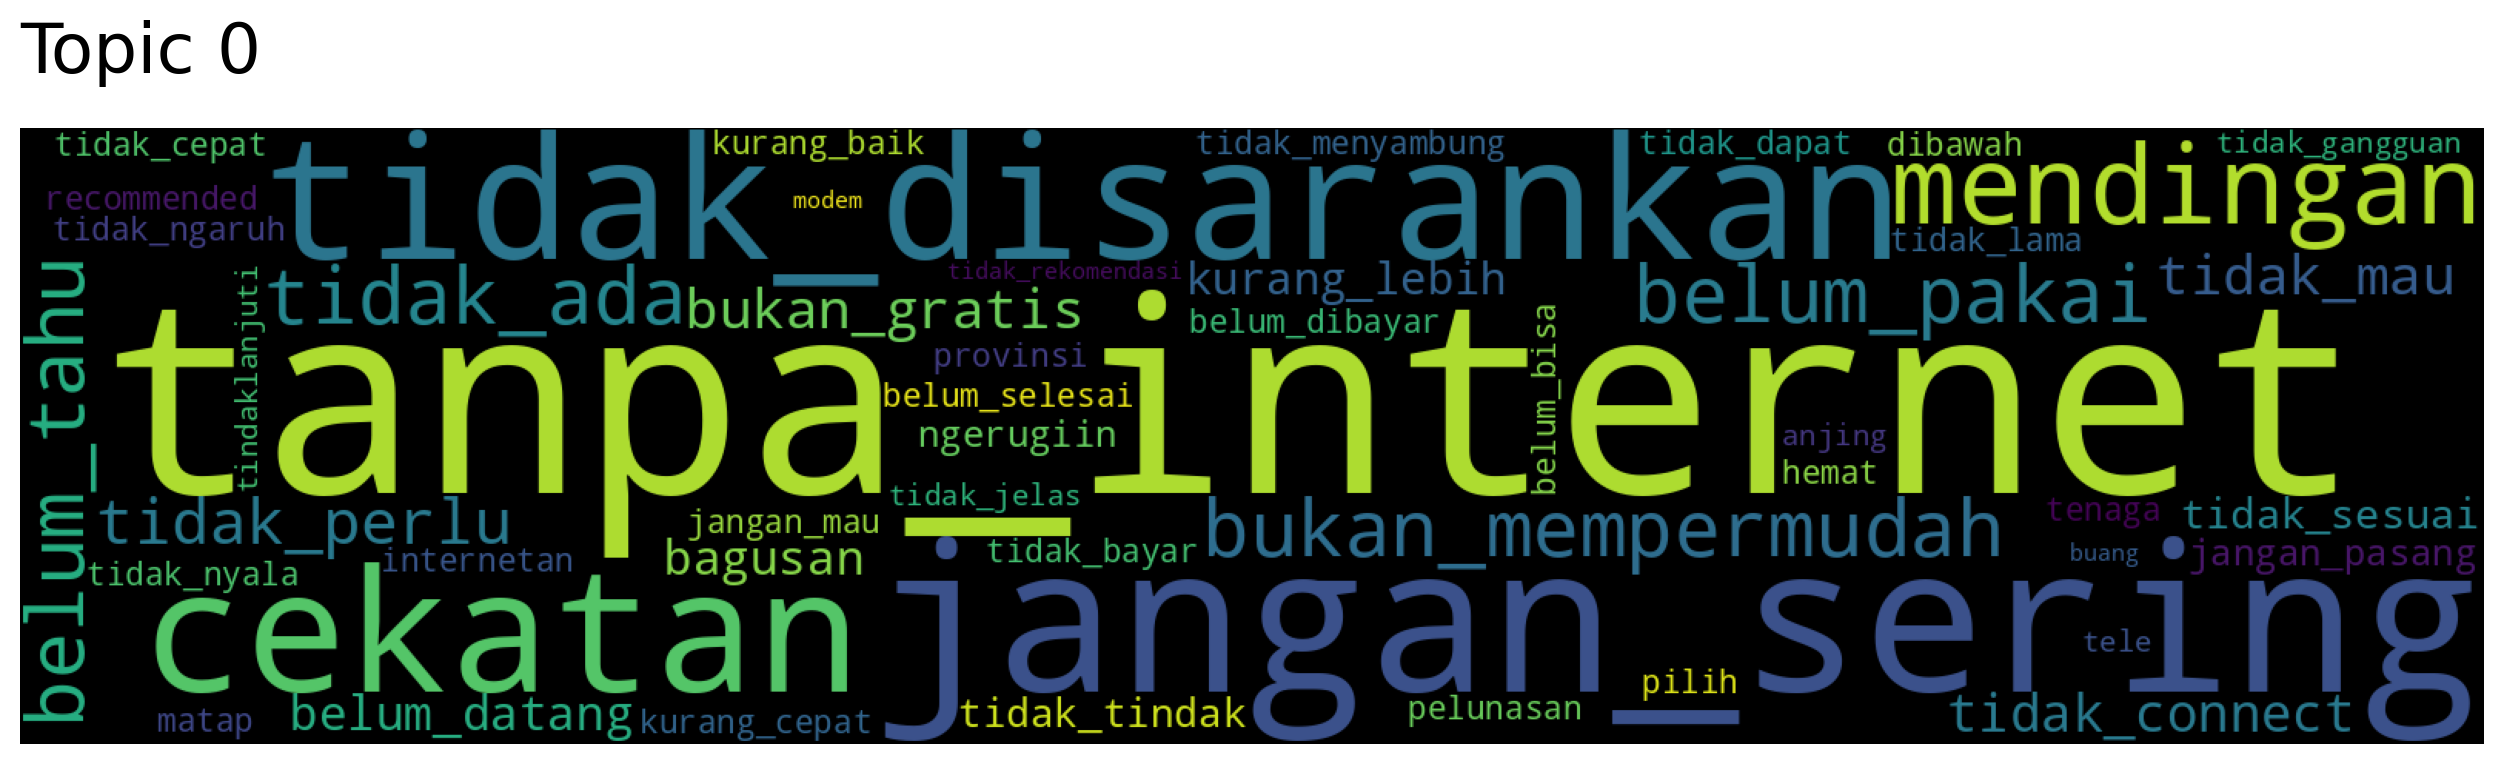

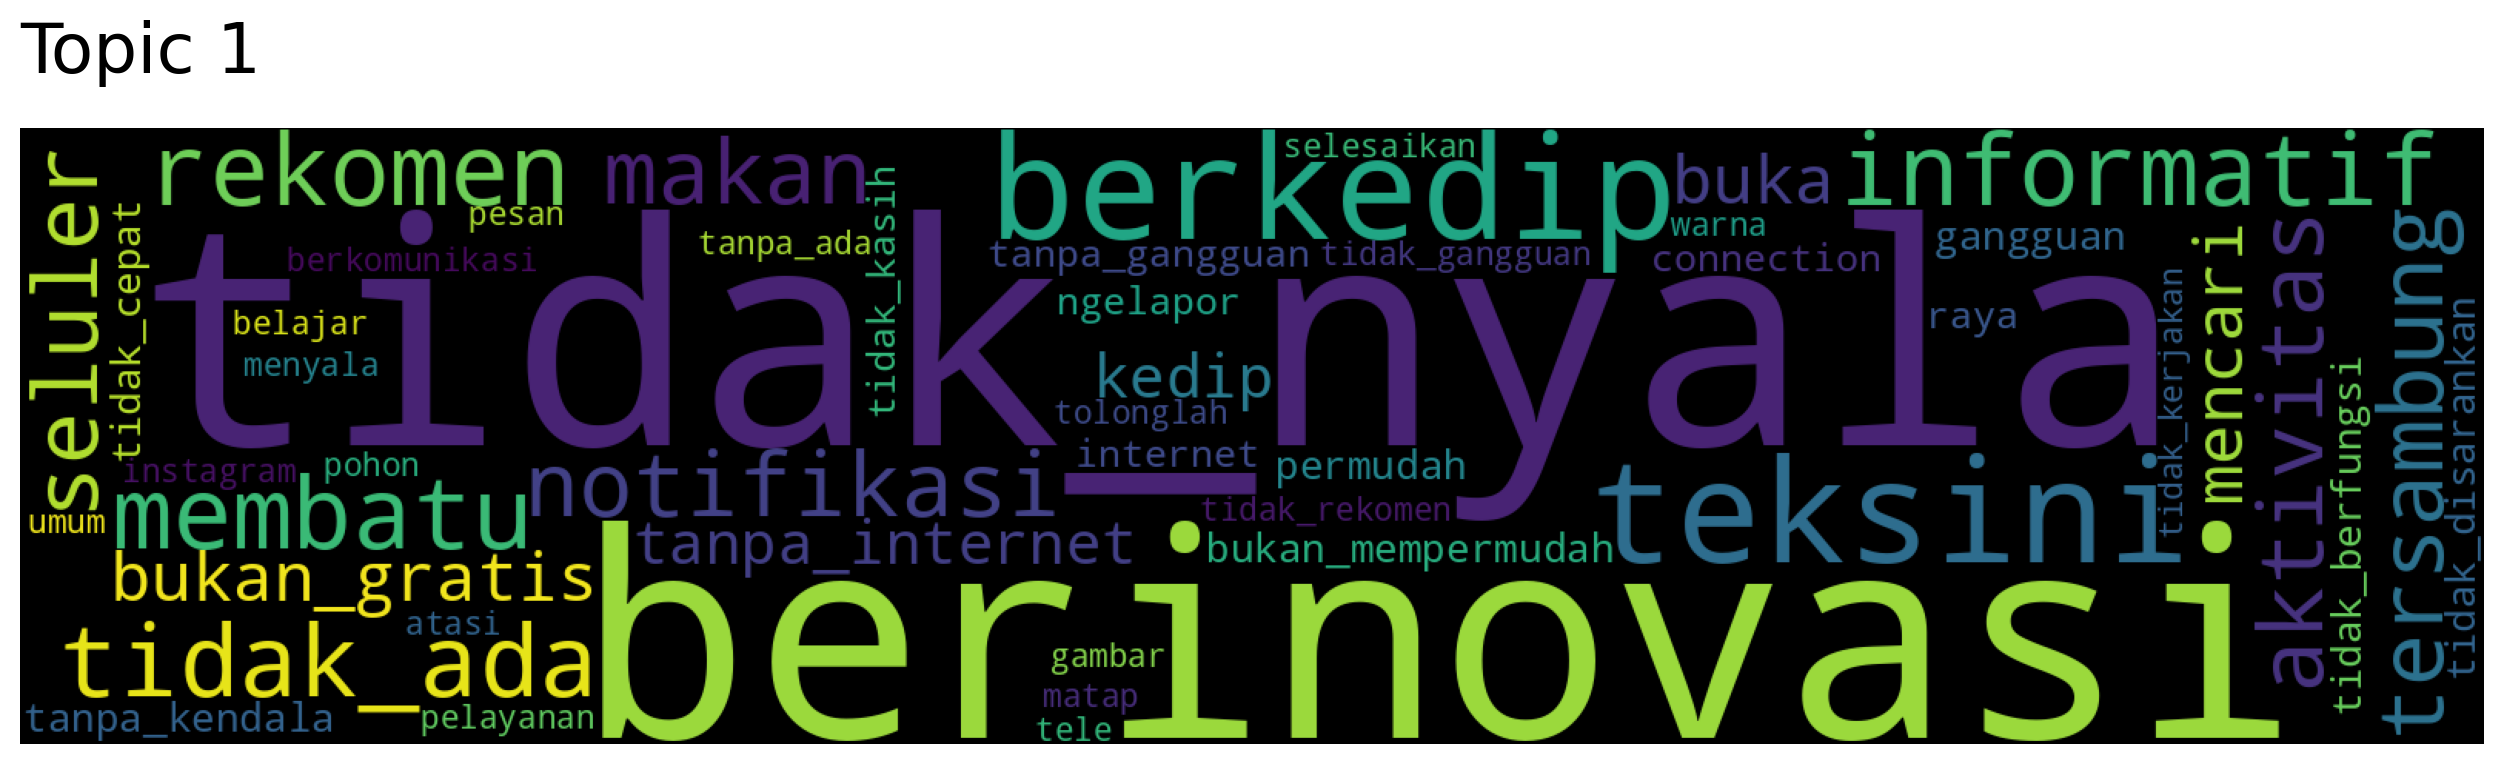

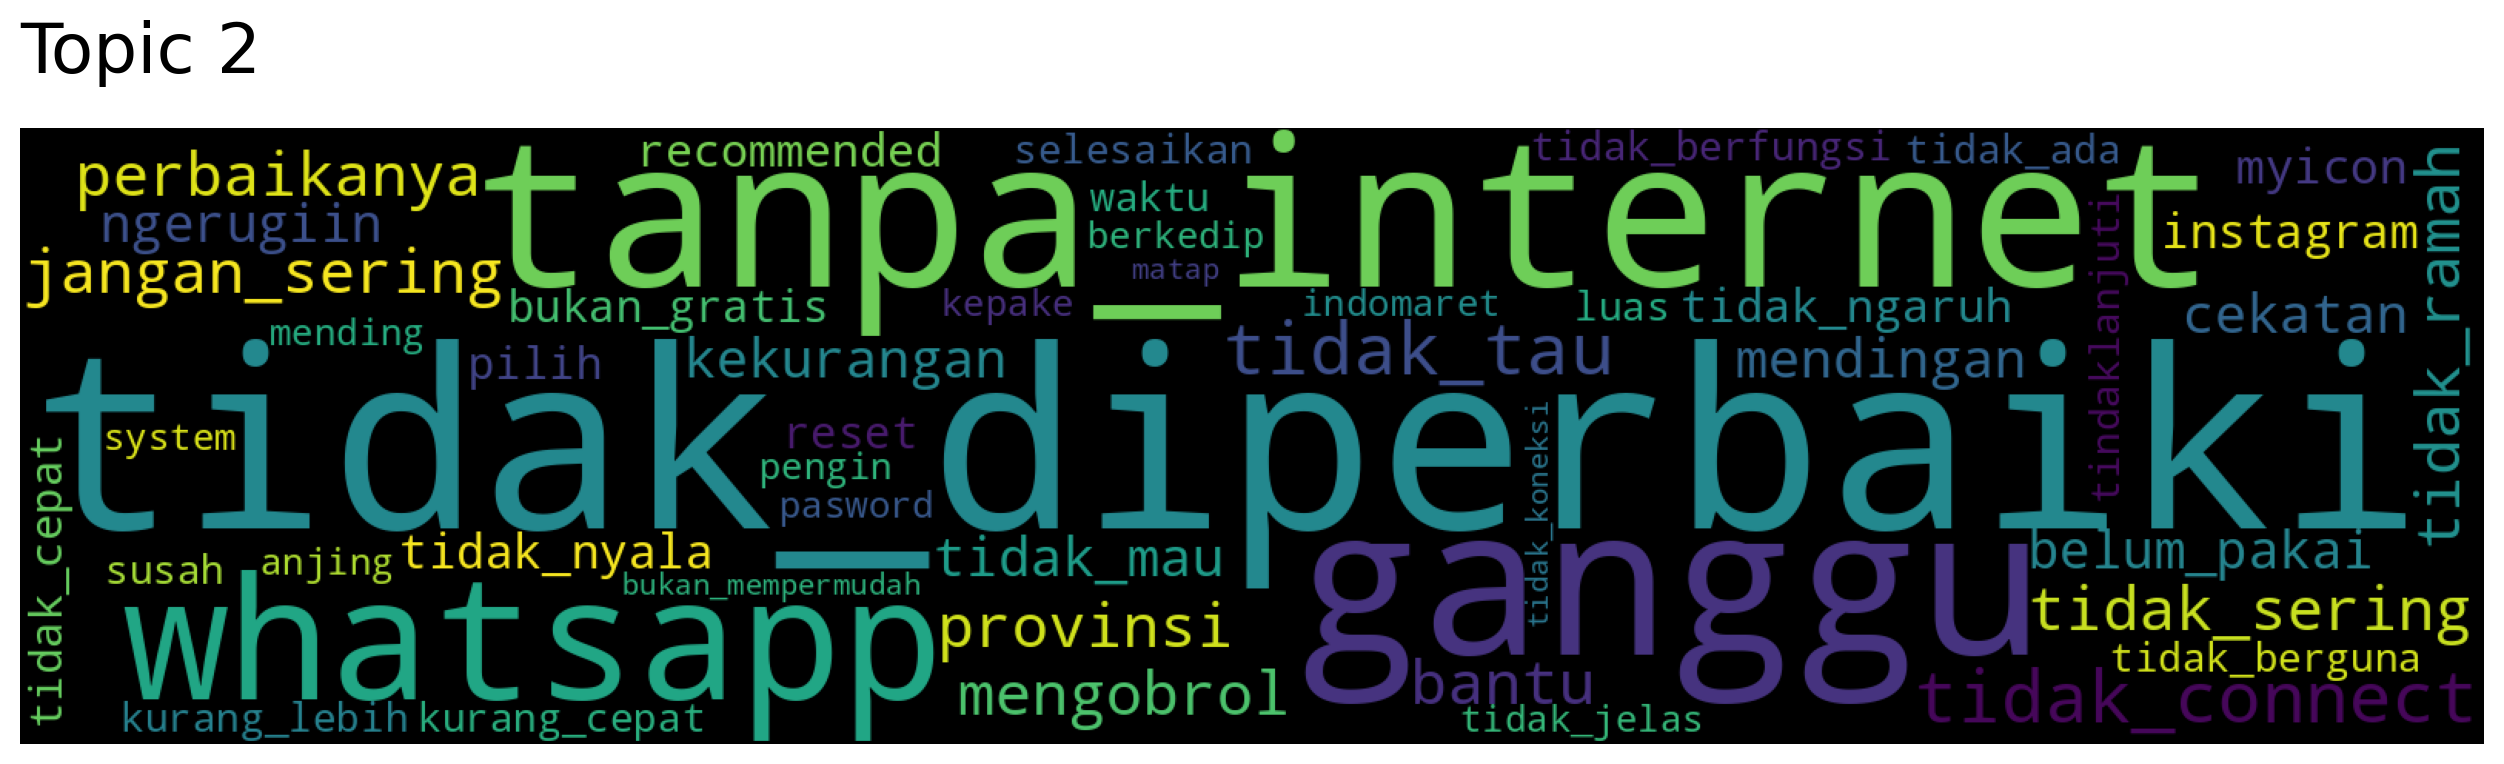

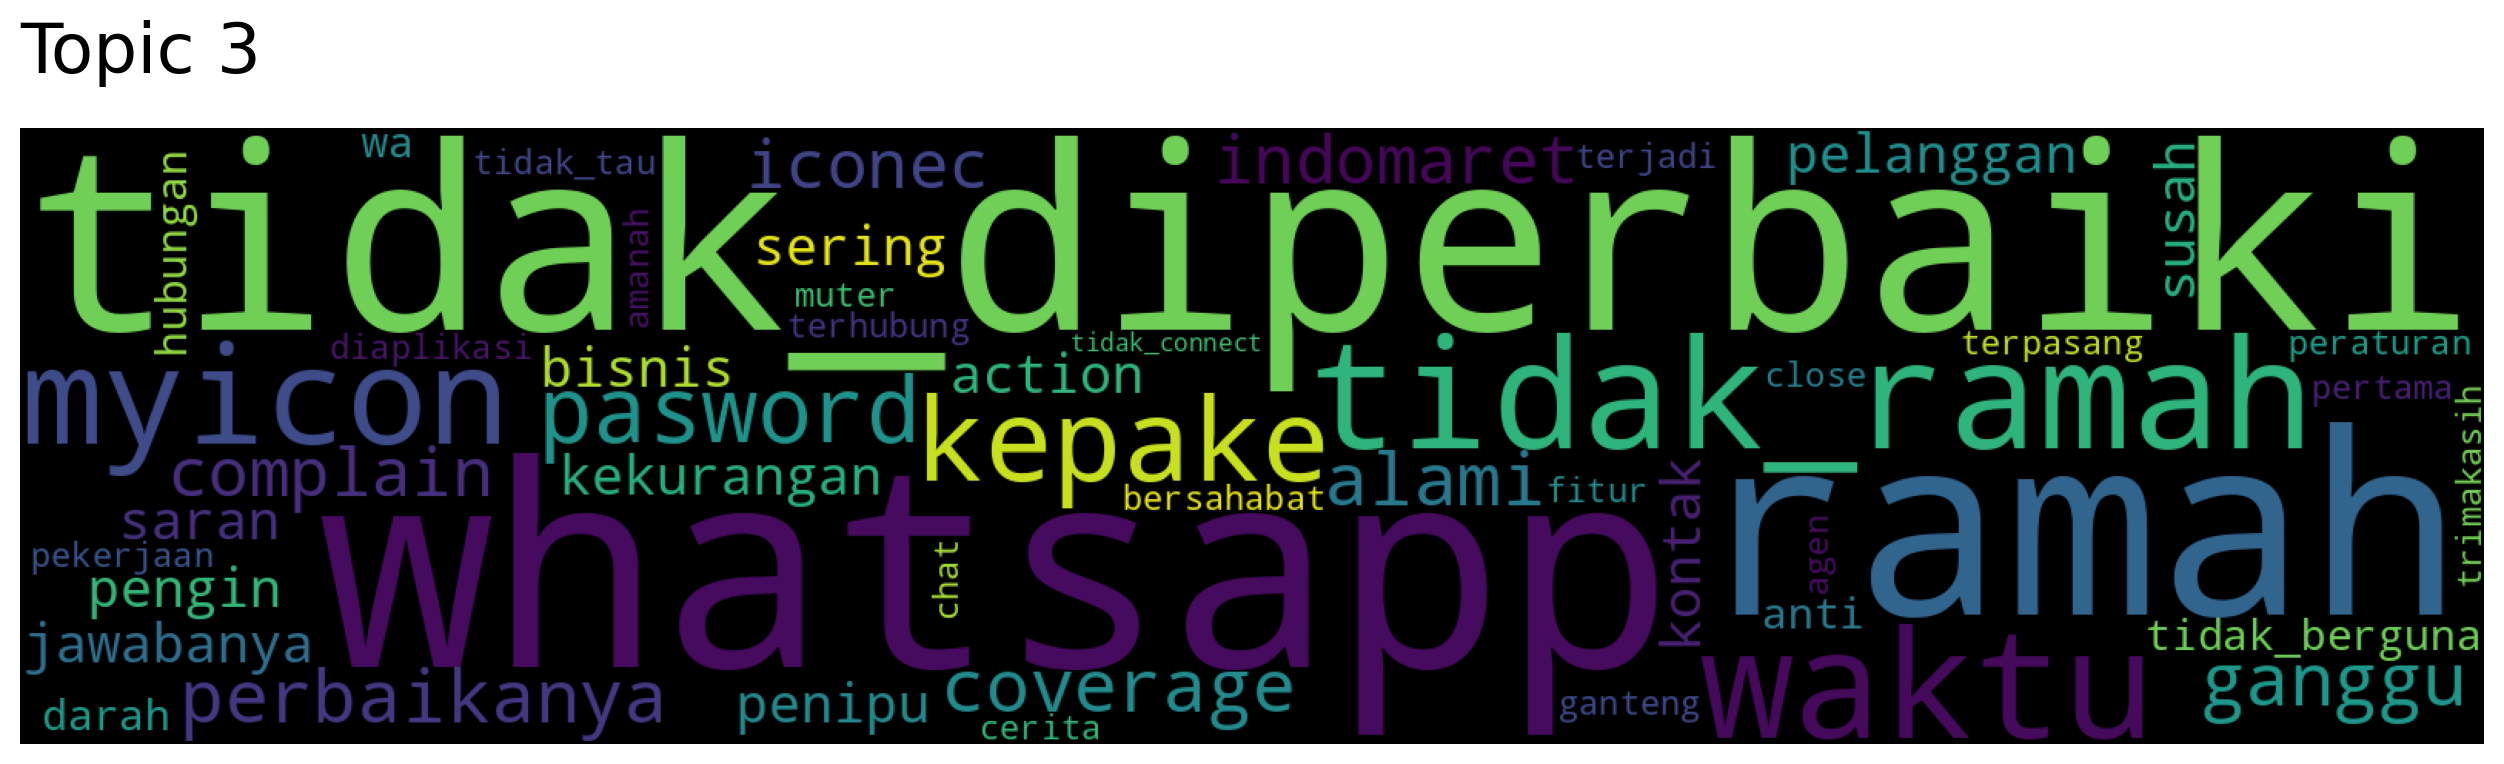

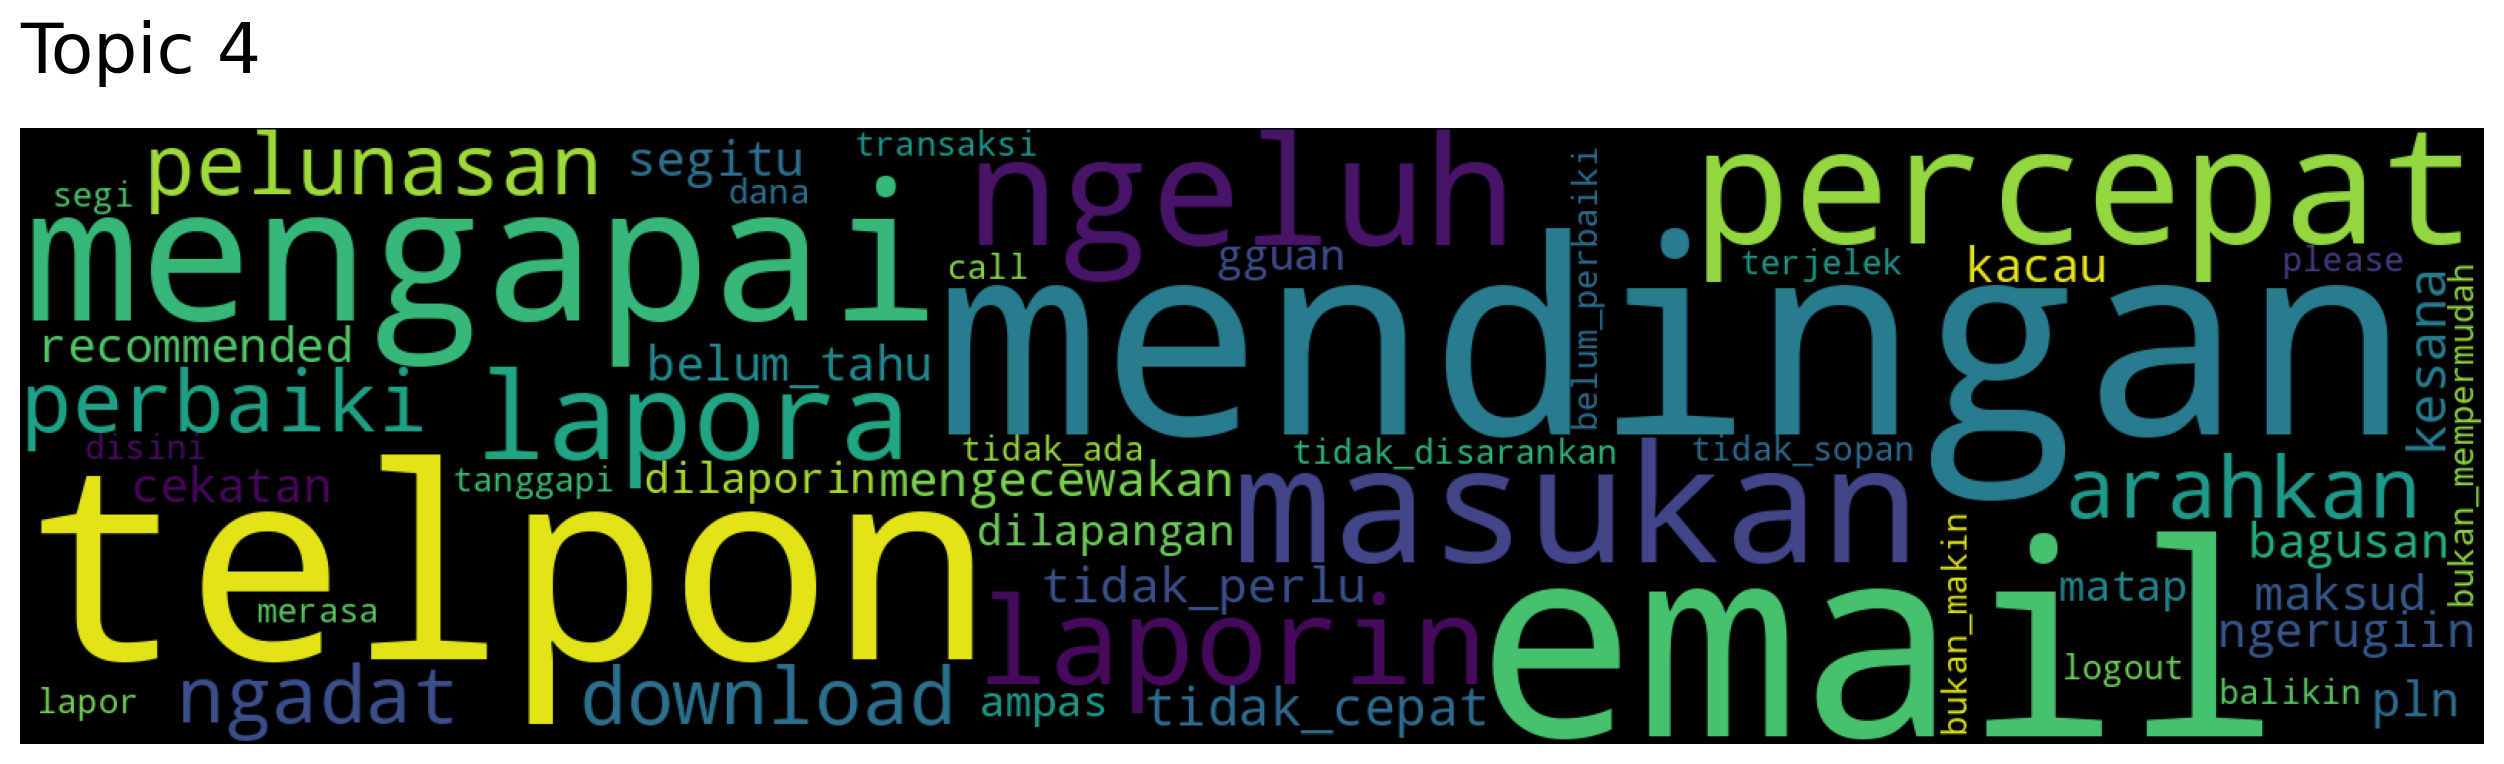

In [ ]:
model_bt_alami.set_topic_labels({t: lbl_bt[t] for t in kata_bt_alami})
for nama_vis, fungsi_vis in [('barchart', lambda: model_bt_alami.visualize_barchart(top_n_topics=8, n_words=8, custom_labels=True)),
                             ('intertopic', model_bt_alami.visualize_topics),
                             ('hierarchy', model_bt_alami.visualize_hierarchy)]:
    try:
        fig_vis = fungsi_vis(); display(fig_vis)
        fig_vis.write_html(f'{OUTPUT_DIR}/bertopic_{nama_vis}.html')
    except Exception as e:
        print(f'Visualisasi {nama_vis} BERTopic dilewati: {e}')

print('Wordcloud topik Top2Vec (kata bawaan Top2Vec):')
for t in list(kata_t2v)[:5]:
    try:
        model_t2v.generate_topic_wordcloud(int(t))
    except Exception as e:
        print(f'Wordcloud topik {t} dilewati: {e}')

## 12. Kesimpulan
### 12.1 Pemeriksaan Konsistensi Hasil
Cek parameter model final, tabel tuning, dan konsistensi antartabel.

In [ ]:
# ---- pemeriksaan tabel tuning ----
METRIK_TUNING = ['jumlah_topik', 'coherence_cv', 'coherence_npmi', 'topic_diversity']
for nama, tb, params in [('BERTopic', tabel_bt, params_bt), ('Top2Vec', tabel_t2v, params_t2v)]:
    catat_validasi('12.1', f'{nama}: id_konfig unik di tabel tuning', tb['id_konfig'].is_unique,
                   f'{len(tb)} baris')
    catat_validasi('12.1', f'{nama}: status hanya berhasil/gagal/dilewati', tb['status'].isin(STATUS_VALID).all(),
                   tb['status'].value_counts().to_dict())
    tidak_ok = tb[tb['status'] != 'berhasil']
    bocor = [c for c in METRIK_TUNING if c in tidak_ok and tidak_ok[c].notna().any()]
    catat_validasi('12.1', f'{nama}: baris gagal/dilewati tidak berisi nilai metrik', not bocor, bocor or '')
    ok = tb[tb['status'] == 'berhasil']
    catat_validasi('12.1', f'{nama}: baris berhasil berisi metrik numerik',
                   ok['jumlah_topik'].notna().all() and
                   np.isfinite(ok.loc[ok['topik_dinilai'] > 0, ['coherence_cv', 'coherence_npmi', 'topic_diversity']]
                               .values.astype(float)).all())
    catat_validasi('12.1', f'{nama}: semua baris tuning dari SIDIK run ini', (tb['sidik'] == SIDIK).all(),
                   tb['sidik'].unique().tolist())
    lengkap = ok['coherence_cv'].notna() & ok['coherence_npmi'].notna() & ok['topic_diversity'].notna() & ok['jumlah_topik'].notna()
    lengkap &= ok['rasio_outlier'].notna() | (ok['outlier_terverifikasi'] == False)
    catat_validasi('12.1', f'{nama}: setiap konfigurasi berhasil memiliki Cv, NPMI, TD, K, dan rasio outlier',
                   bool(lengkap[ok['topik_dinilai'] > 0].all()), f'{int((~lengkap).sum())} baris tidak lengkap')
    terpilih = tb[tb['terpilih'] == True]
    catat_validasi('12.1', f'{nama}: tepat satu konfigurasi terpilih dan sama dengan parameter model final',
                   len(terpilih) == 1 and terpilih.iloc[0]['id_konfig'] == id_konfig(params), json.dumps(params))
    gagal = tb[tb['status'] == 'gagal']
    catat_validasi('12.1', f'{nama}: setiap baris gagal memiliki pesan error', (gagal['pesan_error'].astype(str).str.len() > 0).all(),
                   f'{len(gagal)} baris gagal')
    for k, arah in di_batas(tb[tb['terpilih'] == True].iloc[0], GRID_AKHIR[nama]).items():
        print(f'[PERINGATAN] 12.1: {nama} {k}={params[k]} masih di batas {arah} rentang akhir {GRID_AKHIR[nama][k]}')

# ---- konsistensi antartabel ----
cek_eval = (np.isclose(df_evaluasi.loc[0, 'Topic Coherence (Cv)'], round(eval_bt_alami['coherence_cv'], 4)) and
            np.isclose(df_evaluasi.loc[1, 'Topic Coherence (Cv)'], round(eval_t2v['coherence_cv'], 4)) and
            df_evaluasi.loc[0, 'Jumlah Topik'] == len(kata_bt_alami) and df_evaluasi.loc[1, 'Jumlah Topik'] == len(kata_t2v))
catat_validasi('12.1', 'Tabel evaluasi = objek evaluasi final (K dan Cv)', cek_eval)
catat_validasi('12.1', 'Tabel topik memakai label final yang sama',
               set(tabel_topik_semua['BERTopic']['topik']) - {-1} == set(kata_bt_alami)
               and set(tabel_topik_semua['Top2Vec']['topik']) == set(kata_t2v))
catat_validasi('12.1', 'Metrik model final berada pada rentang sah (Cv 0..1, NPMI -1..1, TD 0..1)',
               all(0 <= e['coherence_cv'] <= 1 and -1 <= e['coherence_npmi'] <= 1 and 0 <= e['topic_diversity'] <= 1
                   for e in [eval_bt_alami, eval_t2v]))

for nama, at in [('BERTopic', aturan_bt), ('Top2Vec', aturan_t2v)]:
    if 'CADANGAN' in at:
        print(f'[PERINGATAN] 12.1: seleksi {nama} memakai aturan cadangan -> {at}')

TABEL_VALIDASI = pd.DataFrame(VALIDASI)
VALIDASI_LULUS = bool(TABEL_VALIDASI['lulus'].all())
display(TABEL_VALIDASI)
TABEL_VALIDASI.to_csv(f'{OUTPUT_DIR}/validasi_akhir.csv', index=False)
print(f'\nPEMERIKSAAN KONSISTENSI: {"SEMUA LULUS" if VALIDASI_LULUS else "ADA YANG GAGAL, kesimpulan ditunda"} '
      f'({int(TABEL_VALIDASI["lulus"].sum())}/{len(TABEL_VALIDASI)})')


[LULUS] 12.1: BERTopic: id_konfig unik di tabel tuning - 95 baris
[LULUS] 12.1: BERTopic: status hanya berhasil/gagal/dilewati - {'berhasil': 95}
[LULUS] 12.1: BERTopic: baris gagal/dilewati tidak berisi nilai metrik 
[LULUS] 12.1: BERTopic: baris berhasil berisi metrik numerik 
[LULUS] 12.1: BERTopic: semua baris tuning dari SIDIK run ini - ['c34fa09c8bc3']
[LULUS] 12.1: BERTopic: setiap konfigurasi berhasil memiliki Cv, NPMI, TD, K, dan rasio outlier - 0 baris tidak lengkap
[LULUS] 12.1: BERTopic: tepat satu konfigurasi terpilih dan sama dengan parameter model final - {"n_neighbors": 5, "n_components": 10, "min_cluster_size": 150, "cluster_selection_method": "leaf", "min_df": 10}
[LULUS] 12.1: BERTopic: setiap baris gagal memiliki pesan error - 0 baris gagal
[LULUS] 12.1: Top2Vec: id_konfig unik di tabel tuning - 92 baris
[LULUS] 12.1: Top2Vec: status hanya berhasil/gagal/dilewati - {'berhasil': 92}
[LULUS] 12.1: Top2Vec: baris gagal/dilewati tidak berisi nilai metrik 
[LULUS] 12.1: 

,bagian,pemeriksaan,lulus,rincian
0,8.1,BERTopic final memakai UMAP/HDBSCAN/min_df ter...,True,"{""n_neighbors"": 5, ""n_components"": 10, ""min_cl..."
1,8.1,Top2Vec final memakai UMAP/HDBSCAN/min_count t...,True,"{""n_neighbors"": 50, ""n_components"": 5, ""min_cl..."
2,8.1,BERTopic final mereproduksi baris tuning terpilih,True,"K=7 (tuning 7), selisih maks 3.47e-17, sidik_l..."
3,8.1,Top2Vec final mereproduksi baris tuning terpilih,True,"K=6 (tuning 6), selisih maks 0.00e+00, sidik_l..."
4,8.2,Tabel evaluasi BERTopic = hasil latih_evaluasi...,True,
5,8.2,Tabel evaluasi Top2Vec = hasil latih_evaluasi ...,True,
6,12.1,BERTopic: id_konfig unik di tabel tuning,True,95 baris
7,12.1,BERTopic: status hanya berhasil/gagal/dilewati,True,{'berhasil': 95}
8,12.1,BERTopic: baris gagal/dilewati tidak berisi ni...,True,
9,12.1,BERTopic: baris berhasil berisi metrik numerik,True,



PEMERIKSAAN KONSISTENSI: SEMUA LULUS (25/25)


### 12.2 Kesimpulan Perbandingan
Selisih metrik dianggap bermakna kalau lebih besar dari dua kali SD antar-seed.

In [ ]:
def sd_stabilitas(model, metrik):
    if STABILITAS is None or (metrik, 'std') not in STABILITAS.columns or model not in STABILITAS.index:
        return None
    n = STABILITAS.loc[model, (metrik, 'count')]
    return float(STABILITAS.loc[model, (metrik, 'std')]) if n >= 2 else None

def nilai_banding(metrik_key, label):
    a, b = eval_bt_alami[metrik_key], eval_t2v[metrik_key]
    lebih = 'BERTopic' if a > b else ('Top2Vec' if b > a else 'sama')
    sa, sb = sd_stabilitas('BERTopic', metrik_key), sd_stabilitas('Top2Vec', metrik_key)
    bermakna = False
    if sa is not None and sb is not None:
        ambang = 2 * max(sa, sb)
        if ambang == 0:
            putusan = (f'{lebih} lebih tinggi (selisih {abs(a - b):.4f}); hasil identik di semua seed sehingga variasi '
                       'antar-seed nol. Selisih ini konsisten, tetapi variasi dari sumber lain (data, parameter) tidak terukur.')
            bermakna = lebih != 'sama'
        elif abs(a - b) > ambang:
            putusan = f'{lebih} lebih tinggi; selisih {abs(a - b):.4f} melebihi 2x simpangan baku antar-seed ({ambang:.4f}).'
            bermakna = True
        else:
            putusan = (f'selisih {abs(a - b):.4f} tidak melebihi 2x simpangan baku antar-seed ({ambang:.4f}); '
                       'tidak disimpulkan ada model yang lebih tinggi.')
    else:
        putusan = f'{lebih} lebih tinggi secara deskriptif (selisih {abs(a - b):.4f}); stabilitas antar-seed tidak tersedia.'
    return {'metrik': label, 'BERTopic': round(a, 4), 'Top2Vec': round(b, 4), 'lebih_tinggi': lebih,
            'selisih_bermakna': bermakna, 'putusan': putusan}

KESIMPULAN = [nilai_banding('coherence_cv', 'Topic Coherence (Cv)'),
              nilai_banding('coherence_npmi', 'Topic Coherence (NPMI)'),
              nilai_banding('topic_diversity', 'Topic Diversity')]
df_kesimpulan = pd.DataFrame(KESIMPULAN)

def stab_teks(model):
    if STABILITAS is None or model not in STABILITAS.index:
        return 'tidak diuji'
    s = STABILITAS.loc[model]
    return (f'SD Cv {s[("coherence_cv", "std")]:.4f}; K {s[("jumlah_topik", "mean")]:.1f}±{s[("jumlah_topik", "std")]:.1f}; '
            f'ARI vs seed utama {s[("ARI_vs_seed_utama", "mean")]:.3f}')

MULTI_KRITERIA = pd.DataFrame([
    {'kriteria': 'Jumlah topik (K)', 'BERTopic': eval_bt_alami['jumlah_topik'], 'Top2Vec': eval_t2v['jumlah_topik'],
     'catatan': 'TD dan C_v dibaca bersama K'},
    {'kriteria': 'C_v', 'BERTopic': round(eval_bt_alami['coherence_cv'], 4), 'Top2Vec': round(eval_t2v['coherence_cv'], 4),
     'catatan': KESIMPULAN[0]['putusan']},
    {'kriteria': 'NPMI', 'BERTopic': round(eval_bt_alami['coherence_npmi'], 4), 'Top2Vec': round(eval_t2v['coherence_npmi'], 4),
     'catatan': KESIMPULAN[1]['putusan']},
    {'kriteria': 'Topic Diversity', 'BERTopic': round(eval_bt_alami['topic_diversity'], 4),
     'Top2Vec': round(eval_t2v['topic_diversity'], 4), 'catatan': KESIMPULAN[2]['putusan']},
    {'kriteria': 'Outlier', 'BERTopic': f'{np.mean(topics_bt_alami == -1):.1%} tanpa topik',
     'Top2Vec': f'{rep_t2v["rasio_noise"]:.1%} noise (tetap diberi topik)', 'catatan': 'definisi berbeda, tidak dibandingkan langsung'},
    {'kriteria': 'Stabilitas antar-seed', 'BERTopic': stab_teks('BERTopic'), 'Top2Vec': stab_teks('Top2Vec'),
     'catatan': 'ARI tinggi = pengelompokan konsisten antar-seed'},
    {'kriteria': 'Keterwakilan kata (selisih rata)', 'BERTopic': KETERWAKILAN['BERTopic']['selisih_rata'],
     'Top2Vec': KETERWAKILAN['Top2Vec']['selisih_rata'], 'catatan': 'positif = kata topik lebih menggambarkan ulasannya sendiri'},
])
display(df_kesimpulan); display(MULTI_KRITERIA)
df_kesimpulan.to_csv(f'{OUTPUT_DIR}/kesimpulan_perbandingan.csv', index=False)
MULTI_KRITERIA.to_csv(f'{OUTPUT_DIR}/perbandingan_multi_kriteria.csv', index=False)

garis = '=' * 78
if not VALIDASI_LULUS:
    print(garis); print('KESIMPULAN DITUNDA: pemeriksaan konsistensi belum lulus. Pemeriksaan yang gagal:'); print(garis)
    for _, r in TABEL_VALIDASI[~TABEL_VALIDASI['lulus']].iterrows():
        print(f'- [{r["bagian"]}] {r["pemeriksaan"]}: {r["rincian"]}')
else:
    print(garis); print('KESIMPULAN KUANTITATIF (embedding IndoBERT yang sama)'); print(garis)
    for k in KESIMPULAN:
        print(f'- {k["metrik"]}: {k["putusan"]}')
    bermakna = [k for k in KESIMPULAN if k['selisih_bermakna']]
    arah = {k['lebih_tinggi'] for k in bermakna}
    if len(bermakna) == len(KESIMPULAN) and len(arah) == 1:
        print(f'- Ketiga metrik kuantitatif menunjuk {arah.pop()} dengan selisih melebihi variasi antar-seed. '
              'Interpretasi topik tetap dibaca dari kata topik dan contoh ulasan di bagian 9.')
    else:
        per_model = {m: [k['metrik'] for k in bermakna if k['lebih_tinggi'] == m] for m in ['BERTopic', 'Top2Vec']}
        tidak = [k['metrik'] for k in KESIMPULAN if not k['selisih_bermakna']]
        print('- Keunggulan per kriteria: ' + '; '.join(f'{m} lebih tinggi pada {", ".join(v)}' for m, v in per_model.items() if v)
              + (f'; tidak berbeda bermakna pada {", ".join(tidak)}' if tidak else '') + '.')
        print('- Karena metrik tidak seluruhnya menunjuk model yang sama dengan selisih bermakna, TIDAK ada model yang '
              'dinyatakan terbaik secara menyeluruh.')
    if eval_bt_alami['jumlah_topik'] != eval_t2v['jumlah_topik']:
        print(f'- Jumlah topik berbeda ({eval_bt_alami["jumlah_topik"]} vs {eval_t2v["jumlah_topik"]}); TD cenderung lebih '
              'tinggi pada K kecil, sehingga TD dibaca bersama K. Lihat juga skenario K disamakan (8.6).')
    print(f'- Outlier: BERTopic {np.mean(topics_bt_alami == -1):.1%} dokumen tanpa topik; Top2Vec {rep_t2v["rasio_noise"]:.1%} '
          'noise HDBSCAN internal yang tetap diberi topik terdekat. Definisi berbeda, jadi angka ini tidak dibandingkan langsung.')
    print(f'- Penggabungan topik Top2Vec: {DIAG_T2V["K_hdbscan_sebelum_merge"]} klaster HDBSCAN menjadi '
          f'{DIAG_T2V["K_setelah_merge"]} topik setelah topic_merge_delta={TOP2VEC_MERGE_DELTA}.')
    cv_t2v_b, cv_t2v_c, cv_bt = eval_t2v['coherence_cv'], eval_t2v_ctfidf['coherence_cv'], eval_bt_alami['coherence_cv']
    print(f'- Diagnostik kata Top2Vec: Cv kata bawaan {cv_t2v_b:.4f}, Cv kata c-TF-IDF pada klaster yang sama {cv_t2v_c:.4f} '
          f'(BERTopic {cv_bt:.4f}); NPMI bawaan {eval_t2v["coherence_npmi"]:.4f} vs c-TF-IDF {eval_t2v_ctfidf["coherence_npmi"]:.4f}. '
          'Perbedaan ini menunjukkan seberapa besar selisih berasal dari mekanisme pemilihan kata, bukan pengelompokan.')
    print(f'- Kesepakatan pengelompokan dokumen: ARI {KESEPAKATAN.loc[0, "ARI"]:.3f} ({tafsir(KESEPAKATAN.loc[0, "ARI"])}), '
          f'NMI {KESEPAKATAN.loc[0, "NMI"]:.3f} ({tafsir(KESEPAKATAN.loc[0, "NMI"])}), n={KESEPAKATAN.loc[0, "n_dokumen"]:,}.')
    print(f'- Seleksi memakai batas minimal {K_MIN} topik; konfigurasi di bawah aturan lain ada pada tabel sensitivitas (7.5).')
    if STABILITAS is None:
        print('- Stabilitas antar-seed tidak diuji: hasil di atas berasal dari satu seed.')
if MODE_UJI:
    print('- MODE_UJI aktif: angka di atas hanya uji cepat pada subset, bukan hasil penelitian.')


,metrik,BERTopic,Top2Vec,lebih_tinggi,selisih_bermakna,putusan
0,Topic Coherence (Cv),0.5181,0.5268,Top2Vec,False,selisih 0.0088 tidak melebihi 2x simpangan bak...
1,Topic Coherence (NPMI),0.0565,-0.4397,BERTopic,True,BERTopic lebih tinggi; selisih 0.4962 melebihi...
2,Topic Diversity,0.7000,0.8500,Top2Vec,True,Top2Vec lebih tinggi; selisih 0.1500 melebihi ...


,kriteria,BERTopic,Top2Vec,catatan
0,Jumlah topik (K),7,6,TD dan C_v dibaca bersama K
1,C_v,0.5181,0.5268,selisih 0.0088 tidak melebihi 2x simpangan bak...
2,NPMI,0.0565,-0.4397,BERTopic lebih tinggi; selisih 0.4962 melebihi...
3,Topic Diversity,0.7,0.85,Top2Vec lebih tinggi; selisih 0.1500 melebihi ...
4,Outlier,36.5% tanpa topik,49.5% noise (tetap diberi topik),"definisi berbeda, tidak dibandingkan langsung"
5,Stabilitas antar-seed,SD Cv 0.0116; K 8.0±0.7; ARI vs seed utama 0.500,SD Cv 0.0071; K 6.2±0.4; ARI vs seed utama 0.929,ARI tinggi = pengelompokan konsisten antar-seed
6,Keterwakilan kata (selisih rata),0.103,0.05,positif = kata topik lebih menggambarkan ulasa...


KESIMPULAN KUANTITATIF (embedding IndoBERT yang sama)
- Topic Coherence (Cv): selisih 0.0088 tidak melebihi 2x simpangan baku antar-seed (0.0232); tidak disimpulkan ada model yang lebih tinggi.
- Topic Coherence (NPMI): BERTopic lebih tinggi; selisih 0.4962 melebihi 2x simpangan baku antar-seed (0.0153).
- Topic Diversity: Top2Vec lebih tinggi; selisih 0.1500 melebihi 2x simpangan baku antar-seed (0.0871).
- Keunggulan per kriteria: BERTopic lebih tinggi pada Topic Coherence (NPMI); Top2Vec lebih tinggi pada Topic Diversity; tidak berbeda bermakna pada Topic Coherence (Cv).
- Karena metrik tidak seluruhnya menunjuk model yang sama dengan selisih bermakna, TIDAK ada model yang dinyatakan terbaik secara menyeluruh.
- Jumlah topik berbeda (7 vs 6); TD cenderung lebih tinggi pada K kecil, sehingga TD dibaca bersama K. Lihat juga skenario K disamakan (8.6).
- Outlier: BERTopic 36.5% dokumen tanpa topik; Top2Vec 49.5% noise HDBSCAN internal yang tetap diberi topik terdekat. Definisi berbeda,

## 13. Simpan Model dan Metadata

In [ ]:
import shutil
# label BERTopic setelah outlier ditempatkan ke topik terdekat (juga dipakai di 14.3)
if 'topics_bt_reduksi' not in globals():
    topics_bt_reduksi = np.array(model_bt_alami.reduce_outliers(dokumen_batas, topics_bt_alami, strategy='embeddings',
                                                                embeddings=embeddings_indobert, threshold=AMBANG_REDUKSI_HILIR))
if 'eval_bt_reduksi' not in globals():
    eval_bt_reduksi = {}
PENYIMPANAN = [
    ('BERTopic (safetensors)', f'{OUTPUT_DIR}/model_bertopic_alami',
     lambda p: model_bt_alami.save(p, serialization='safetensors', save_ctfidf=True, save_embedding_model=NAMA_MODEL_INDOBERT)),
    ('BERTopic (pickle, cadangan)', f'{OUTPUT_DIR}/model_bertopic_alami.pkl',
     lambda p: model_bt_alami.save(p, serialization='pickle', save_embedding_model=False)),
    ('Top2Vec', f'{OUTPUT_DIR}/model_top2vec_alami', lambda p: model_t2v.save(p))]
tersimpan = set()
for nama, path, fungsi in PENYIMPANAN:
    if nama.startswith('BERTopic (pickle') and 'BERTopic' in tersimpan:
        continue
    sudah_ada = os.path.exists(path)
    try:
        fungsi(path); tersimpan.add(nama.split()[0]); print(f'Model {nama} disimpan: {path}')
    except Exception as e:
        print(f'Model {nama} tidak dapat disimpan ({type(e).__name__}: {e}).')
        if not sudah_ada and os.path.exists(path):      # hapus hanya file parsial yang baru dibuat percobaan ini
            shutil.rmtree(path) if os.path.isdir(path) else os.remove(path)
            print(f'  File parsial dari percobaan gagal dihapus: {path}')
print('Label dokumen dan vektor topik selalu disimpan terpisah (.npy) sebagai cadangan.')
np.save(f'{OUTPUT_DIR}/label_bertopic_alami.npy', topics_bt_alami)
np.save(f'{OUTPUT_DIR}/label_bertopic_reduksi.npy', topics_bt_reduksi)
np.save(f'{OUTPUT_DIR}/label_top2vec.npy', doc_topik_t2v)
np.save(f'{OUTPUT_DIR}/label_hdbscan_top2vec_replikasi.npy', rep_t2v['label_hdbscan'])
np.save(f'{OUTPUT_DIR}/top2vec_topic_vectors.npy', model_t2v.topic_vectors)

WAKTU_SELESAI = datetime.now(ZoneInfo('Asia/Makassar'))
METADATA = {
    'judul': 'Topic Modeling pada Ulasan Aplikasi MyIcon+ Menggunakan Algoritma BERTopic dan Top2Vec',
    'mode_uji': MODE_UJI, 'mulai': str(WAKTU_MULAI), 'selesai': str(WAKTU_SELESAI),
    'durasi_menit': round((WAKTU_SELESAI - WAKTU_MULAI).total_seconds() / 60, 1),
    'dataset': {'path': FILE_PATH, 'sha256': SHA_DATASET}, 'kamus': {'path': KAMUS_LOKAL, 'sha256': SHA_KAMUS, 'sumber': SUMBER_KAMUS},
    'tahap_data': CATATAN_TAHAP, 'embedding': INFO_EMBEDDING, 'kunci_embedding': KUNCI_EMB, 'sidik_tuning': SIDIK,
    'seed': SEED, 'seed_stabilitas': SEED_STABILITAS if JALANKAN_STABILITAS else None,
    'umap_default': UMAP_DEFAULT, 'hdbscan_default': HDBSCAN_DEFAULT, 'grid_klaster': GRID_KLASTER, 'grid_repr': GRID_REPR,
    'batas_outlier': BATAS_OUTLIER, 'params_bertopic': params_bt, 'aturan_bertopic': aturan_bt,
    'params_top2vec': params_t2v, 'aturan_top2vec': aturan_t2v, 'ambang_reduksi_hilir': AMBANG_REDUKSI_HILIR,
    'evaluasi_bertopic_alami': {k: v for k, v in eval_bt_alami.items() if not k.endswith('_per_topik')},
    'evaluasi_bertopic_setelah_penugasan_outlier': {k: v for k, v in eval_bt_reduksi.items() if not k.endswith('_per_topik')},
    'evaluasi_top2vec': {k: v for k, v in eval_t2v.items() if not k.endswith('_per_topik')},
    'pengaturan_tambahan': {'min_df_tingkat': MIN_DF_TINGKAT, 'k_min': K_MIN, 'negasi_tunggal_dipertahankan': NEGASI_TUNGGAL_DIPERTAHANKAN,
                     'jendela_koherensi': JENDELA_KOHERENSI, 'perluasan_grid': PERLUASAN_GRID, 'grid_akhir': GRID_AKHIR,
                     'log_perluasan': LOG_PERLUASAN, 'status_tuning': {f'{m} | {st}': int(n) for (m, st), n in tabel_tuning.groupby(['model', 'status']).size().items()},
                     'validasi_lulus': VALIDASI_LULUS, 'validasi': VALIDASI,
                     'audit_negasi': AUDIT_NEGASI.to_dict()},
    'diagnostik_top2vec': DIAG_T2V, 'statistik_normalisasi': dict(STAT_NORMAL), 'statistik_embed_top2vec': dict(STAT_EMBED),
    'versi': VERSI, 'keputusan_preprocessing': {'peta_icon_ke_iconnet': PETA_ICON_KE_ICONNET,
        'pertahankan_kata_evaluatif': PERTAHANKAN_KATA_EVALUATIF, 'kata_domain_dipertahankan': KATA_DOMAIN_DIPERTAHANKAN},
}
with open(f'{OUTPUT_DIR}/metadata_eksperimen.json', 'w') as f:
    json.dump(METADATA, f, indent=2, default=str)
pd.DataFrame(LOG_CACHE).to_csv(f'{OUTPUT_DIR}/log_cache.csv', index=False)
with open(f'{OUTPUT_DIR}/info_run.txt', 'a') as f:
    f.write(f"Selesai : {WAKTU_SELESAI:%Y-%m-%d %H:%M:%S} WITA\nSIDIK   : {SIDIK}\n")

manifest = []
for akar, _, files in os.walk(OUTPUT_DIR):
    for nama_f in files:
        p = os.path.join(akar, nama_f)
        manifest.append({'file': os.path.relpath(p, OUTPUT_DIR), 'ukuran_byte': os.path.getsize(p), 'sha256': sha256_file(p)})
pd.DataFrame(manifest).sort_values('file').to_csv(f'{OUTPUT_DIR}/manifest_hasil.csv', index=False)

print('=' * 60); print('LOG PEMAKAIAN CACHE'); print('=' * 60)
display(pd.DataFrame(LOG_CACHE))
print(f'\n{len(manifest)} file hasil tersimpan di {OUTPUT_DIR}')
if MODE_UJI:
    print('PERINGATAN: run ini adalah MODE_UJI (uji teknis), bukan hasil penelitian.')

Model BERTopic (safetensors) disimpan: /content/drive/MyDrive/DATASET TA/hasil_revisi/run_20261108_2305_revisiR2/model_bertopic_alami
Model Top2Vec disimpan: /content/drive/MyDrive/DATASET TA/hasil_revisi/run_20261108_2305_revisiR2/model_top2vec_alami
Label dokumen dan vektor topik selalu disimpan terpisah (.npy) sebagai cadangan.
LOG PEMAKAIAN CACHE


,waktu,jenis,kunci,status,keterangan
0,23:06:03,embedding,3fcf9ab07003cccb,dipakai,/content/drive/MyDrive/DATASET TA/hasil_revisi...
1,23:06:11,tuning,BERTopic_c34fa09c8bc3,ringkasan,tahap 1 (klaster): {'cache': 80} dari 80 konfi...
2,23:06:11,tuning,BERTopic_c34fa09c8bc3,ringkasan,tahap 1b (perluasan terarah): {'cache': 9} dar...
3,23:06:11,tuning,BERTopic_c34fa09c8bc3,ringkasan,"tahap 2 (representasi): {'cache': 6, 'dilewati..."
4,23:06:11,tuning,Top2Vec_c34fa09c8bc3,ringkasan,tahap 1 (klaster): {'cache': 80} dari 80 konfi...
5,23:06:11,tuning,Top2Vec_c34fa09c8bc3,ringkasan,tahap 1b (perluasan terarah): {'cache': 6} dar...
6,23:06:11,tuning,Top2Vec_c34fa09c8bc3,ringkasan,"tahap 2 (representasi): {'cache': 6, 'dilewati..."



75 file hasil tersimpan di /content/drive/MyDrive/DATASET TA/hasil_revisi/run_20261108_2305_revisiR2


## 14. Analisis Tambahan
Memakai model final dari bagian 8. Hasil disimpan di folder `revisi_R2`; run yang sudah selesai tidak diulang.

### 14.0 Persiapan
Cek bahwa model sesi ini sama dengan yang dilaporkan (K = 7 dan 6, outlier BERTopic 36,53%).

In [ ]:
# 14.0 Persiapan: folder keluaran, daftar seed, dan fungsi untuk melatih ulang serta meringkas hasil per seed.
# Hasil setiap run disimpan di {OUTPUT_DIR}/revisi_R2/runs dan dipakai ulang jika sudah ada.
import os, json, time, gc, re, textwrap
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from sklearn.metrics import adjusted_rand_score as ARI, normalized_mutual_info_score as NMI

REV_DIR = f'{OUTPUT_DIR}/revisi_R2'
os.makedirs(REV_DIR, exist_ok=True)
SEED_R2 = [42, 7, 123, 2024, 777, 1, 13, 99, 314, 2026]   # 10 seed -> 45 pasangan
KUNCI_KLASTER = ['n_neighbors', 'n_components', 'min_cluster_size', 'cluster_selection_method']
RINGKASAN = []
def tulis(*a):
    s = ' '.join(str(x) for x in a); print(s); RINGKASAN.append(s)
def simpan_ringkasan():
    with open(f'{REV_DIR}/RINGKASAN_REVISI_R2.txt', 'w') as f:
        f.write('\n'.join(RINGKASAN))

def _js(o):
    return o.item() if hasattr(o, 'item') else str(o)
def js(o):
    return json.dumps(o, default=_js)

assert np.array_equal(topics_bt_alami, TOPICS_BT_ALAMI_ASLI), 'Label BERTopic alami berubah; jalankan ulang notebook.'
tulis('OUTPUT_DIR :', OUTPUT_DIR)
tulis('params_bt  :', js(params_bt))
tulis('params_t2v :', js(params_t2v))
# model sesi ini harus sama dengan model yang dilaporkan (diperiksa lewat validasi 8.1, K, dan rasio outlier)
gagal_81 = [v for v in VALIDASI if v['bagian'] == '8.1' and not v['lulus']]
assert not gagal_81, f'Validasi 8.1 GAGAL, hasil berbeda dari paper: {gagal_81}'
assert len(kata_bt_alami) == 7 and len(kata_t2v) == 6, 'K berbeda dari paper (7 dan 6)'
assert abs(np.mean(topics_bt_alami == -1) - 0.3653) < 5e-4, 'Rasio outlier BERTopic berbeda dari paper (36,53%)'
tulis(f'Model sesi ini = model paper: K 7/6, outlier BERTopic {np.mean(topics_bt_alami == -1):.4f}, '
      f'Cv {eval_bt_alami["coherence_cv"]:.3f}/{eval_t2v["coherence_cv"]:.3f}, NPMI {eval_bt_alami["coherence_npmi"]:.3f}/{eval_t2v["coherence_npmi"]:.3f}')
tulis(f'N unik = {len(dokumen):,} | N bermakna = {len(df_semua_dasar):,}')

def jalan_simpan(tag, nama, params, s):
    """Latih satu run, simpan label + inti (bukan outlier/noise) + metrik + kata topik."""
    f_lab, f_core, f_ev = (f'{REV_DIR}/runs/{tag}_s{s}_{x}' for x in ['label.npy', 'inti.npy', 'eval.json'])
    os.makedirs(f'{REV_DIR}/runs', exist_ok=True)
    if all(os.path.exists(f) for f in [f_lab, f_core, f_ev]):
        return json.load(open(f_ev)), np.load(f_lab), np.load(f_core)
    set_seed(s); t0 = time.time()
    ev, kel = latih_evaluasi(nama, params, seed=s)
    lab = np.asarray(kel['topics']).astype(int)
    if nama == 'BERTopic':
        inti = lab != -1
    else:
        rep = kel['replikasi']
        inti = (rep['label_hdbscan'] != -1) if rep['replikasi_terverifikasi'] else np.ones(len(lab), bool)
    rec = {'tag': tag, 'model': nama, 'seed': s, 'params': params,
           'K': int(ev['jumlah_topik']), 'Cv': float(ev['coherence_cv']), 'NPMI': float(ev['coherence_npmi']),
           'TD': float(ev['topic_diversity']), 'outlier': float(np.mean(~inti)),
           'outlier_terverifikasi': bool(ev['outlier_terverifikasi']),
           'kata': {str(t): v['eval'] for t, v in kel['kata'].items()},
           'detik': round(time.time() - t0, 1)}
    np.save(f_lab, lab); np.save(f_core, inti); json.dump(rec, open(f_ev, 'w'), indent=1, default=_js)
    del kel; gc.collect()
    print(f'  {tag:<12} seed {s:<5} K={rec["K"]} Cv={rec["Cv"]:.3f} NPMI={rec["NPMI"]:.3f} '
          f'TD={rec["TD"]:.3f} outlier={rec["outlier"]:.3f} ({rec["detik"]} s)')
    return rec, lab, inti

def ringkas_runs(tag, runs):
    """runs: dict seed -> (rec, lab, inti). Metrik mean±SD + ARI semua pasangan + ARI vs seed 42 tanpa 42-42."""
    d = pd.DataFrame([r for r, _, _ in runs.values()])
    pas = []
    for a, b in combinations(list(runs), 2):
        la, lb = runs[a][1], runs[b][1]
        m = runs[a][2] & runs[b][2]
        pas.append({'tag': tag, 'seed_a': a, 'seed_b': b, 'ARI_semua': ARI(la, lb),
                    'ARI_inti': ARI(la[m], lb[m]), 'NMI_semua': NMI(la, lb), 'n_inti': int(m.sum())})
    pas = pd.DataFrame(pas)
    v42 = pas[(pas['seed_a'] == 42) | (pas['seed_b'] == 42)]
    out = {'tag': tag, 'n_seed': len(d)}
    for k in ['K', 'Cv', 'NPMI', 'TD', 'outlier']:
        out[f'{k}_mean'], out[f'{k}_sd'] = d[k].mean(), d[k].std(ddof=1)
        out[f'{k}_min'], out[f'{k}_max'] = d[k].min(), d[k].max()
    for k in ['ARI_semua', 'ARI_inti', 'NMI_semua']:
        out[f'{k}_pair_mean'], out[f'{k}_pair_sd'] = pas[k].mean(), pas[k].std(ddof=1)
        out[f'{k}_vs42_mean'], out[f'{k}_vs42_sd'] = v42[k].mean(), v42[k].std(ddof=1)
    out['n_pasangan'] = len(pas)
    return d, pas, out

def cetak_ringkas(o):
    tulis(f"[{o['tag']}] {o['n_seed']} seed | K {o['K_mean']:.2f}±{o['K_sd']:.2f} ({o['K_min']:.0f}-{o['K_max']:.0f}) | "
          f"Cv {o['Cv_mean']:.3f}±{o['Cv_sd']:.3f} | NPMI {o['NPMI_mean']:.3f}±{o['NPMI_sd']:.3f} | "
          f"TD {o['TD_mean']:.3f}±{o['TD_sd']:.3f} | outlier {o['outlier_mean']:.3f}±{o['outlier_sd']:.3f} "
          f"({o['outlier_min']:.3f}-{o['outlier_max']:.3f})")
    tulis(f"      ARI semua pasangan ({o['n_pasangan']}) = {o['ARI_semua_pair_mean']:.3f}±{o['ARI_semua_pair_sd']:.3f} | "
          f"ARI vs seed 42 (tanpa 42-42) = {o['ARI_semua_vs42_mean']:.3f}±{o['ARI_semua_vs42_sd']:.3f} | "
          f"ARI inti pasangan = {o['ARI_inti_pair_mean']:.3f}±{o['ARI_inti_pair_sd']:.3f} | "
          f"NMI pasangan = {o['NMI_semua_pair_mean']:.3f}±{o['NMI_semua_pair_sd']:.3f}")
print('Sel R2-0 siap.')



OUTPUT_DIR : /content/drive/MyDrive/DATASET TA/hasil_revisi/run_20261108_2305_revisiR2
params_bt  : {"n_neighbors": 5, "n_components": 10, "min_cluster_size": 150, "cluster_selection_method": "leaf", "min_df": 10}
params_t2v : {"n_neighbors": 50, "n_components": 5, "min_cluster_size": 150, "cluster_selection_method": "leaf", "min_count": 5}
Model sesi ini = model paper: K 7/6, outlier BERTopic 0.3653, Cv 0.518/0.527, NPMI 0.056/-0.440
N unik = 13,101 | N bermakna = 16,166
Sel R2-0 siap.


### 14.1 Stabilitas dengan 10 Seed
ARI pada 45 pasangan seed, untuk semua ulasan dan untuk ulasan inti saja.

In [ ]:
# 14.1 Stabilitas 10 seed; label setiap run disimpan agar ARI dapat dihitung pada 45 pasangan seed.
RUNS = {}
for tag, nama, params in [('BT', 'BERTopic', params_bt), ('T2V', 'Top2Vec', params_t2v)]:
    print(f'== {tag} ==')
    RUNS[tag] = {s: jalan_simpan(tag, nama, params, s) for s in SEED_R2}

# pemeriksaan: seed 42 harus mereproduksi model final
tulis('Reproduksi seed 42 BERTopic =', bool(np.array_equal(RUNS['BT'][42][1], topics_bt_alami)),
      '| Top2Vec =', bool(np.array_equal(RUNS['T2V'][42][1], doc_topik_t2v)))
STAB_R2, PAS_R2, RUN_R2 = [], [], []
tulis('\n=== STABILITAS 10 SEED ===')
for tag in ['BT', 'T2V']:
    d, pas, o = ringkas_runs(tag, RUNS[tag]); cetak_ringkas(o)
    STAB_R2.append(o); PAS_R2.append(pas); RUN_R2.append(d.drop(columns=['kata', 'params']))
STAB_R2 = pd.DataFrame(STAB_R2); STAB_R2.to_csv(f'{REV_DIR}/R2_1_stabilitas_ringkasan.csv', index=False)
pd.concat(PAS_R2).to_csv(f'{REV_DIR}/R2_1_ari_semua_pasangan.csv', index=False)
pd.concat(RUN_R2).to_csv(f'{REV_DIR}/R2_1_metrik_per_seed.csv', index=False)

# aturan 2×SD terbesar dengan 10 seed
b, t = STAB_R2.set_index('tag').loc['BT'], STAB_R2.set_index('tag').loc['T2V']
for k in ['Cv', 'NPMI', 'TD']:
    gap = abs(eval_bt_alami[{'Cv': 'coherence_cv', 'NPMI': 'coherence_npmi', 'TD': 'topic_diversity'}[k]] -
              eval_t2v[{'Cv': 'coherence_cv', 'NPMI': 'coherence_npmi', 'TD': 'topic_diversity'}[k]])
    sd = max(b[f'{k}_sd'], t[f'{k}_sd'])
    tulis(f'  selisih {k} model final = {gap:.3f} | 2×SD terbesar (10 seed) = {2*sd:.3f} -> '
          f'{"MELAMPAUI" if gap > 2*sd else "TIDAK melampaui"} variasi antar-run')
# metrik rata-rata 10 seed: apakah urutan model konsisten di setiap seed?
for k in ['Cv', 'NPMI', 'TD']:
    a = RUN_R2[0].set_index('seed')[k]; c = RUN_R2[1].set_index('seed')[k]
    tulis(f'  {k}: BERTopic > Top2Vec pada {(a > c).sum()}/{len(a)} seed (seed berpasangan)')
simpan_ringkasan()



== BT ==
  BT           seed 42    K=7 Cv=0.518 NPMI=0.056 TD=0.700 outlier=0.365 (23.8 s)
  BT           seed 7     K=9 Cv=0.527 NPMI=0.046 TD=0.678 outlier=0.593 (16.2 s)
  BT           seed 123   K=8 Cv=0.502 NPMI=0.043 TD=0.725 outlier=0.326 (15.6 s)
  BT           seed 2024  K=8 Cv=0.515 NPMI=0.039 TD=0.688 outlier=0.493 (15.5 s)
  BT           seed 777   K=8 Cv=0.532 NPMI=0.037 TD=0.675 outlier=0.666 (15.4 s)
  BT           seed 1     K=8 Cv=0.507 NPMI=0.051 TD=0.675 outlier=0.505 (15.4 s)
  BT           seed 13    K=6 Cv=0.493 NPMI=0.054 TD=0.733 outlier=0.238 (15.4 s)
  BT           seed 99    K=8 Cv=0.533 NPMI=0.053 TD=0.650 outlier=0.615 (16.6 s)
  BT           seed 314   K=5 Cv=0.554 NPMI=0.078 TD=0.720 outlier=0.245 (18.2 s)
  BT           seed 2026  K=7 Cv=0.494 NPMI=0.070 TD=0.729 outlier=0.300 (16.6 s)
== T2V ==
  T2V          seed 42    K=6 Cv=0.527 NPMI=-0.440 TD=0.850 outlier=0.495 (73.0 s)
  T2V          seed 7     K=6 Cv=0.520 NPMI=-0.443 TD=0.883 outlier=0.489 (71.

### 14.2 Kontrol Parameter Klaster Ditukar
Parameter UMAP/HDBSCAN kedua model ditukar, 10 seed.

In [ ]:
# 14.2 Kontrol parameter klaster ditukar
# BT_swap  = BERTopic dengan parameter klaster Top2Vec (n_neighbors, n_components, min_cluster_size, metode),
#            tetap min_df BERTopic. T2V_swap = Top2Vec dengan parameter klaster BERTopic, tetap min_count Top2Vec.
# Jika selisih NPMI tetap muncul pada parameter klaster yang SAMA, penyebabnya pemilihan kata, bukan UMAP.
params_bt_swap  = {**{k: params_t2v[k] for k in KUNCI_KLASTER}, 'min_df': params_bt['min_df']}
params_t2v_swap = {**{k: params_bt[k] for k in KUNCI_KLASTER}, 'min_count': params_t2v['min_count']}
tulis('\n=== KONTROL PARAMETER KLASTER DITUKAR ===')
tulis('BT_swap :', js(params_bt_swap)); tulis('T2V_swap:', js(params_t2v_swap))
for tag, nama, params in [('BT_swap', 'BERTopic', params_bt_swap), ('T2V_swap', 'Top2Vec', params_t2v_swap)]:
    print(f'== {tag} ==')
    RUNS[tag] = {s: jalan_simpan(tag, nama, params, s) for s in SEED_R2}
SWAP = []
for tag in ['BT_swap', 'T2V_swap']:
    d, pas, o = ringkas_runs(tag, RUNS[tag]); cetak_ringkas(o); SWAP.append(o)
    d.drop(columns=['kata', 'params']).to_csv(f'{REV_DIR}/R2_2_{tag}_per_seed.csv', index=False)
pd.DataFrame(SWAP).to_csv(f'{REV_DIR}/R2_2_swap_ringkasan.csv', index=False)

# perbandingan dua model pada parameter klaster yang sama, seed yang sama
baris = []
for s in SEED_R2:
    for pasangan, (ta, tb) in {'nn/nc/mcs Top2Vec': ('BT_swap', 'T2V'), 'nn/nc/mcs BERTopic': ('BT', 'T2V_swap')}.items():
        ra, la, ia = RUNS[ta][s]; rb, lb, ib = RUNS[tb][s]
        m = ia & ib
        baris.append({'klaster_sama': pasangan, 'seed': s, 'NPMI_BERTopic': ra['NPMI'], 'NPMI_Top2Vec': rb['NPMI'],
                      'Cv_BERTopic': ra['Cv'], 'Cv_Top2Vec': rb['Cv'], 'TD_BERTopic': ra['TD'], 'TD_Top2Vec': rb['TD'],
                      'K_BERTopic': ra['K'], 'K_Top2Vec': rb['K'],
                      'ARI_inti_antarmodel': ARI(la[m], lb[m]) if m.sum() > 1 else np.nan,
                      'NMI_inti_antarmodel': NMI(la[m], lb[m]) if m.sum() > 1 else np.nan, 'n_inti': int(m.sum())})
SAMA = pd.DataFrame(baris); SAMA.to_csv(f'{REV_DIR}/R2_2_dua_model_klaster_sama.csv', index=False)
for p, g in SAMA.groupby('klaster_sama'):
    tulis(f'[{p}] NPMI BT {g.NPMI_BERTopic.mean():.3f}±{g.NPMI_BERTopic.std():.3f} vs T2V '
          f'{g.NPMI_Top2Vec.mean():.3f}±{g.NPMI_Top2Vec.std():.3f} | BT>T2V pada {(g.NPMI_BERTopic > g.NPMI_Top2Vec).sum()}/{len(g)} seed | '
          f'Cv BT {g.Cv_BERTopic.mean():.3f} vs T2V {g.Cv_Top2Vec.mean():.3f} | TD BT {g.TD_BERTopic.mean():.3f} vs '
          f'T2V {g.TD_Top2Vec.mean():.3f} | ARI inti antarmodel {g.ARI_inti_antarmodel.mean():.3f}±{g.ARI_inti_antarmodel.std():.3f}')
for tag in ['BT_swap', 'T2V_swap']:
    r42 = RUNS[tag][42][0]
    tulis(f'  {tag} seed 42 kata topik (5 pertama):')
    for t, w in list(r42['kata'].items())[:8]:
        tulis(f'    T{t}: {", ".join(w[:5])}')
simpan_ringkasan()




=== KONTROL PARAMETER KLASTER DITUKAR ===
BT_swap : {"n_neighbors": 50, "n_components": 5, "min_cluster_size": 150, "cluster_selection_method": "leaf", "min_df": 10}
T2V_swap: {"n_neighbors": 5, "n_components": 10, "min_cluster_size": 150, "cluster_selection_method": "leaf", "min_count": 5}
== BT_swap ==
  BT_swap      seed 42    K=7 Cv=0.506 NPMI=0.049 TD=0.671 outlier=0.695 (37.0 s)
  BT_swap      seed 7     K=5 Cv=0.468 NPMI=0.043 TD=0.700 outlier=0.334 (37.9 s)
  BT_swap      seed 123   K=7 Cv=0.469 NPMI=0.033 TD=0.643 outlier=0.462 (37.7 s)
  BT_swap      seed 2024  K=6 Cv=0.507 NPMI=0.059 TD=0.650 outlier=0.485 (38.8 s)
  BT_swap      seed 777   K=5 Cv=0.472 NPMI=0.027 TD=0.700 outlier=0.292 (37.4 s)
  BT_swap      seed 1     K=6 Cv=0.497 NPMI=0.047 TD=0.650 outlier=0.535 (38.2 s)
  BT_swap      seed 13    K=6 Cv=0.482 NPMI=0.052 TD=0.633 outlier=0.512 (37.5 s)
  BT_swap      seed 99    K=6 Cv=0.495 NPMI=0.050 TD=0.633 outlier=0.522 (37.7 s)
  BT_swap      seed 314   K=6 Cv=0.43

### 14.3 Kesepakatan Pengelompokan pada Seluruh Ulasan
ARI/NMI pada inti, seluruh ulasan, dan setelah outlier BERTopic ditempatkan ke topik terdekat.

In [ ]:
# 14.3 Kesepakatan pengelompokan pada seluruh ulasan
if 'topics_bt_reduksi' not in globals():   # outlier BERTopic ditugaskan ke topik terdekat (strategi embedding)
    topics_bt_reduksi = np.array(model_bt_alami.reduce_outliers(dokumen_batas, topics_bt_alami, strategy='embeddings',
                                                                embeddings=embeddings_indobert, threshold=AMBANG_REDUKSI_HILIR))
inti_t2v = rep_t2v['label_hdbscan'] != -1
inti_bt = topics_bt_alami != -1
kondisi = [
    ('A: inti kedua model (dilaporkan di paper)', inti_bt & inti_t2v, topics_bt_alami, doc_topik_t2v),
    ('B: semua ulasan, outlier BERTopic = 1 kelompok', np.ones(len(dokumen), bool), topics_bt_alami, doc_topik_t2v),
    ('C: bukan outlier BERTopic, Top2Vec termasuk noise yang ditugaskan', inti_bt, topics_bt_alami, doc_topik_t2v),
    ('D: semua ulasan, outlier BERTopic ditugaskan ke topik terdekat', np.ones(len(dokumen), bool), topics_bt_reduksi, doc_topik_t2v),
]
KS = pd.DataFrame([{'kondisi': n, 'n': int(m.sum()), 'persen_unik': round(m.mean() * 100, 1),
                    'ARI': ARI(a[m], b[m]), 'NMI': NMI(a[m], b[m])} for n, m, a, b in kondisi])
KS.to_csv(f'{REV_DIR}/R2_3_kesepakatan_korpus_penuh.csv', index=False)
tulis('\n=== KESEPAKATAN BERTOPIC vs TOP2VEC (ulasan unik) ===')
for _, r in KS.iterrows():
    tulis(f"  {r['kondisi']:<70} n={r['n']:>6,} ({r['persen_unik']:>5.1f}%) ARI={r['ARI']:.3f} NMI={r['NMI']:.3f}")
tulis(f'  Noise Top2Vec yang tetap ditugaskan: {(~inti_t2v).sum():,} ({(~inti_t2v).mean()*100:.1f}%) | '
      f'outlier BERTopic: {(~inti_bt).sum():,} ({(~inti_bt).mean()*100:.1f}%) | '
      f'outlier BT ∩ noise T2V: {((~inti_bt) & (~inti_t2v)).sum():,}')

# Ke mana outlier BERTopic ditempatkan Top2Vec? (dibobot ulasan bermakna, 16.166)
DB, DT = DOK_SEMUA['BERTopic'], DOK_SEMUA['Top2Vec']
assert (DB.index == DT.index).all()
kec_bt = DB['kecenderungan'].replace({'dominan keluhan': 'complaint', 'dominan apresiasi': 'praise',
                                      'campuran': 'mixed', 'outlier': 'outlier'})
kec_t2v = DT['kecenderungan'].replace({'dominan keluhan': 'complaint', 'dominan apresiasi': 'praise', 'campuran': 'mixed'})
silang = pd.crosstab(kec_bt.rename('BERTopic'), kec_t2v.rename('Top2Vec'), margins=True, margins_name='total')
silang_pct = (silang / len(DB) * 100).round(2)
silang.to_csv(f'{REV_DIR}/R2_3_kecenderungan_BT_x_T2V_jumlah.csv'); silang_pct.to_csv(f'{REV_DIR}/R2_3_kecenderungan_BT_x_T2V_persen.csv')
tulis('\nKecenderungan BERTopic (baris) x Top2Vec (kolom), % dari 16.166 ulasan bermakna:')
tulis(silang_pct.to_string())
o = DB['topik'] == -1
tulis(f"  Outlier BERTopic: {o.sum():,} ulasan bermakna; rating 5 = {(DB.loc[o,'rating']==5).mean()*100:.1f}%, "
      f"rating 4-5 = {(DB.loc[o,'rating']>=4).mean()*100:.1f}%, rating 1-2 = {(DB.loc[o,'rating']<=2).mean()*100:.1f}%")
tulis(f"  Panjang token median: outlier {DB.loc[o,'teks_embedding'].str.split().str.len().median():.0f} vs "
      f"bertopik {DB.loc[~o,'teks_embedding'].str.split().str.len().median():.0f}")
tujuan = pd.crosstab(DB.loc[o, 'topik'], DT.loc[o, 'topik'], normalize='index').T.round(3) * 100
tulis('  Outlier BERTopic -> topik Top2Vec (% ulasan bermakna outlier):'); tulis(tujuan.to_string())
neg = DB['rating'] <= 2
tulis(f"  Ulasan rating 1-2: {neg.sum():,}; yang menjadi outlier BERTopic: {(neg & o).sum():,} "
      f"({(neg & o).sum()/neg.sum()*100:.1f}%) | yang masuk topik keluhan BERTopic: "
      f"{(neg & (DB['kecenderungan']=='dominan keluhan')).sum()/neg.sum()*100:.1f}% | topik keluhan Top2Vec: "
      f"{(neg & (DT['kecenderungan']=='dominan keluhan')).sum()/neg.sum()*100:.1f}%")
simpan_ringkasan()




=== KESEPAKATAN BERTOPIC vs TOP2VEC (ulasan unik) ===
  A: inti kedua model (dilaporkan di paper)                              n= 5,882 ( 44.9%) ARI=0.890 NMI=0.851
  B: semua ulasan, outlier BERTopic = 1 kelompok                         n=13,101 (100.0%) ARI=0.422 NMI=0.473
  C: bukan outlier BERTopic, Top2Vec termasuk noise yang ditugaskan      n= 8,315 ( 63.5%) ARI=0.768 NMI=0.723
  D: semua ulasan, outlier BERTopic ditugaskan ke topik terdekat         n=13,101 (100.0%) ARI=0.746 NMI=0.729
  Noise Top2Vec yang tetap ditugaskan: 6,485 (49.5%) | outlier BERTopic: 4,786 (36.5%) | outlier BT ∩ noise T2V: 4,052

Kecenderungan BERTopic (baris) x Top2Vec (kolom), % dari 16.166 ulasan bermakna:
Top2Vec    complaint  praise   total
BERTopic                            
complaint      34.86    4.65   39.52
outlier         6.56   37.71   44.27
praise          0.41   15.80   16.22
total          41.83   58.17  100.00
  Outlier BERTopic: 7,156 ulasan bermakna; rating 5 = 78.3%, rating 4-5 = 80.2

### 14.4 Inspeksi Topik dan Outlier
Topik yang terbagi, sampel 100 outlier rating 1–2, dan ulasan tentang aplikasi (uji `min_cluster_size` 30/50/75).

In [ ]:
# 14.4 Inspeksi topik yang terbagi, outlier negatif, dan ulasan tentang aplikasi
kol_asli = next((c for c in ['ulasan_asli', 'case_folding'] if c in df_semua_dasar.columns), 'teks_embedding')
mA = inti_bt & inti_t2v
tulis('\n=== INSPEKSI TOPIK BERTOPIC YANG TERBAGI (kondisi A) ===')
for t in kata_bt_alami:
    row = overlap_bt.loc[t] if t in overlap_bt.index else None
    if row is not None and row.max() < 0.9:
        tulis(f'BERTopic T{t} ({lbl_bt[t]}): ' + ', '.join(f'T2V T{c}={v*100:.1f}%' for c, v in row.items() if v > 0.01))
        for c, v in row.items():
            if v < 0.05: continue
            idx = np.where(mA & (topics_bt_alami == t) & (doc_topik_t2v == c))[0]
            sub = DB[DB['teks_embedding'].isin(set(dokumen[i] for i in idx))]
            tulis(f'  -> T2V T{c} ({lbl_t2v[c]}): {len(idx)} unik, {len(sub)} bermakna, '
                  f'rating 4-5 = {(sub.rating>=4).mean()*100:.1f}%, rating 1-2 = {(sub.rating<=2).mean()*100:.1f}%')
            for _, r in sub.drop_duplicates('teks_embedding').sample(min(8, len(sub.drop_duplicates('teks_embedding'))), random_state=42).iterrows():
                tulis(f'       [{r.rating}*] {str(r[kol_asli])[:110]}')
        pd.DataFrame({'teks': [dokumen[i] for i in np.where(mA & (topics_bt_alami == t))[0]],
                      'T2V': doc_topik_t2v[mA & (topics_bt_alami == t)]}).to_csv(f'{REV_DIR}/R2_4_BT_T{t}_terbagi.csv', index=False)

# Sampel 100 ulasan rating 1-2 yang menjadi outlier BERTopic (unik), beserta topik Top2Vec-nya
neg_out = DB[(DB['topik'] == -1) & (DB['rating'] <= 2)].copy()
neg_out['topik_T2V'] = DT.loc[neg_out.index, 'topik']
neg_out['n_token'] = neg_out['teks_embedding'].str.split().str.len()
unik_neg = neg_out.drop_duplicates('teks_embedding')
sampel = unik_neg.sample(min(100, len(unik_neg)), random_state=42)
sampel[['rating', 'tahun', kol_asli, 'teks_embedding', 'n_token', 'topik_T2V']].to_csv(
    f'{REV_DIR}/R2_4_sampel100_outlier_negatif.csv', index=False)
tulis(f'\nOutlier BERTopic rating 1-2: {len(neg_out):,} bermakna / {len(unik_neg):,} unik; median token {neg_out.n_token.median():.0f}; '
      f'sampel {len(sampel)} disimpan (R2_4_sampel100_outlier_negatif.csv)')
tulis('  Topik Top2Vec untuk outlier negatif (% bermakna): ' +
      ', '.join(f'T{k}={v:.1f}%' for k, v in (neg_out.topik_T2V.value_counts(normalize=True) * 100).items()))

# Kata kunci aplikasi/antarmuka: di mana ulasan tentang aplikasi berada?
POLA_UI = r'\b(login|otp|update|upgrade|versi|error|eror|bug|loading|crash|keluar sendiri|akun|verifikasi|tampilan|fitur|menu|notifikasi|lemot aplikasi|tidak bisa masuk|gagal masuk|daftar)\b'
ui = DB['teks_embedding'].str.contains(POLA_UI, regex=True)
tulis(f'\nUlasan dengan kata kunci aplikasi/antarmuka: {ui.sum():,} ({ui.mean()*100:.1f}% bermakna); '
      f'outlier BERTopic {(ui & o).sum()/ui.sum()*100:.1f}%; '
      'sebaran topik BERTopic: ' + ', '.join(f'T{k}={v:.1f}%' for k, v in (DB.loc[ui, 'topik'].value_counts(normalize=True) * 100).items()))
tulis('  Contoh: ' + ' || '.join(str(x)[:80] for x in DB.loc[ui, kol_asli].drop_duplicates().sample(6, random_state=1)))

# Sensitivitas min_cluster_size kecil: apakah muncul topik aplikasi/antarmuka?
tulis('\nSensitivitas min_cluster_size (BERTopic, seed 42, parameter lain tetap):')
for mcs in [30, 50, 75]:
    p = {**params_bt, 'min_cluster_size': mcs}
    r, lab, inti = jalan_simpan(f'BT_mcs{mcs}', 'BERTopic', p, 42)
    tulis(f'  mcs={mcs}: K={r["K"]}, outlier={r["outlier"]:.3f}, Cv={r["Cv"]:.3f}, NPMI={r["NPMI"]:.3f}')
    for t, w in r['kata'].items():
        n = int((lab == int(t)).sum())
        ui_share = np.mean([bool(re.search(POLA_UI, dokumen[i])) for i in np.where(lab == int(t))[0]]) * 100
        tulis(f'     T{t} (n={n}, UI={ui_share:.0f}%): {", ".join(w[:6])}')
simpan_ringkasan()




=== INSPEKSI TOPIK BERTOPIC YANG TERBAGI (kondisi A) ===
BERTopic T5 (T5: membantu, aplikasi membantu, memudahkan): T2V T0=50.0%, T2V T4=50.0%
  -> T2V T0 (T0: tanpa internet, jangan sering, tidak disarankan): 1 unik, 1 bermakna, rating 4-5 = 100.0%, rating 1-2 = 0.0%
       [4*] kalau bisa ada pemberitahuan gangguan sinyal di aplikasi ini
  -> T2V T4 (T4: mendingan, telpon, email): 1 unik, 1 bermakna, rating 4-5 = 100.0%, rating 1-2 = 0.0%
       [5*] Keren, sangat membantu dalam proses pembayaran. 👍

Outlier BERTopic rating 1-2: 1,302 bermakna / 1,227 unik; median token 6; sampel 100 disimpan (R2_4_sampel100_outlier_negatif.csv)
  Topik Top2Vec untuk outlier negatif (% bermakna): T1=27.1%, T0=25.7%, T2=15.1%, T4=12.1%, T3=11.3%, T5=8.6%

Ulasan dengan kata kunci aplikasi/antarmuka: 1,037 (6.4% bermakna); outlier BERTopic 24.5%; sebaran topik BERTopic: T0=49.6%, T-1=24.5%, T1=23.0%, T2=1.3%, T4=0.6%, T5=0.6%, T3=0.5%, T6=0.1%
  Contoh: Ga bisa login, ada yang salah, padahal email sdh

### 14.5 NPMI per Topik, Tabel Topik, Gambar 2 dan 3


=== NPMI DAN Cv PER TOPIK ===
BERTopic T0: n=4718 (29.18%) 4-5*=14.9% Cv=0.681 NPMI=0.027 | hari, tidak_ada, bayar, gangguan, internet, wifi, bulan, laporan, jaringan, tidak_bisa
     "Aplikasi gangguan terus v 2.0.4 terus kalo wifi problem penanganan udh pasti 1 hari sampai 2 hari baru solved," | "Lambat dalam proses gangguan jaringan, kadang udh buat kode laporan tapi blum kunjunh datang tuk di perbaiki, "
BERTopic T1: n=1670 (10.33%) 4-5*=18.0% Cv=0.592 NPMI=0.005 | sering, tidak_ada, lambat, respon, tidak_bisa, gangguan, terus, wa, hari, iconnet
     "Kenapa sih cs by wa d hilangkan, klo by aplikasi sangat slowrespon.. Keluhan internet lambat sudah hampir sebu" | ""
BERTopic T2: n=1252 (7.74%) 4-5*=93.6% Cv=0.536 NPMI=0.133 | cepat, pemasangan, rapi, ramah, bagus, oke, pelayanan, memuaskan, teknisi, stabil
     "Teknisi ramah dan pemasangan cepat" | "pelayanan sangat memuaskan, teknisi ramah dan sopan"
BERTopic T3: n=415 (2.57%) 4-5*=93.0% Cv=0.412 NPMI=0.115 | mantap, cepat, rama

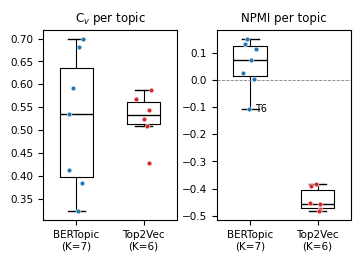

Topik BERTopic dengan NPMI negatif: T6 (NPMI=-0.108; oke, bagus, baik, lumayan, jos, joss)


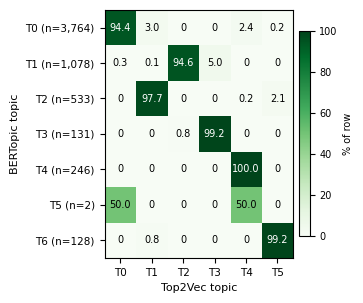

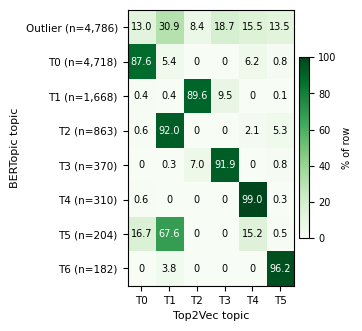

Heatmap korpus penuh (baris outlier, %): T0=13.0, T1=30.9, T2=8.4, T3=18.7, T4=15.5, T5=13.5


In [ ]:
# 14.5 NPMI per topik, tabel topik, Gambar 2 dan Gambar 3
tulis('\n=== NPMI DAN Cv PER TOPIK ===')
TAB = {}
for kunci, kata, ev in [('BERTopic', kata_bt_alami, eval_bt_alami), ('Top2Vec', kata_t2v, eval_t2v)]:
    R = RATING[kunci].set_index('topik')
    baris = []
    for pos, t in enumerate(kata):
        ex = dokumen_representatif(SKENARIO_TOPIK[kunci][2], t, 15)
        asli = []
        for d_ in ex:
            cand = DB.loc[DB['teks_embedding'] == d_, kol_asli]
            if len(cand): asli.append(str(cand.iloc[0]).strip())
        asli = [a for a in asli if 25 <= len(a) <= 140][:2] or asli[:2]
        baris.append({'model': kunci, 'topik': int(t), 'n_bermakna': int(R.loc[t, 'jumlah_ulasan']),
                      'persen_bermakna': R.loc[t, 'persen_dari_bermakna'], 'persen_4_5': R.loc[t, 'persen_rating_4_5'],
                      'persen_1_2': R.loc[t, 'persen_rating_1_2'], 'rata_rating': R.loc[t, 'rata_rata_rating'],
                      'kecenderungan': R.loc[t, 'kecenderungan'], 'Cv': round(ev['cv_per_topik'][pos], 3),
                      'NPMI': round(ev['npmi_per_topik'][pos], 3), 'unigram_top10': ', '.join(kata[t]['eval'][:10]),
                      'kutipan_1': asli[0] if asli else '', 'kutipan_2': asli[1] if len(asli) > 1 else ''})
        b = baris[-1]
        tulis(f"{kunci} T{t}: n={b['n_bermakna']} ({b['persen_bermakna']}%) 4-5*={b['persen_4_5']}% Cv={b['Cv']} NPMI={b['NPMI']} | "
              f"{b['unigram_top10']}\n     \"{b['kutipan_1'][:110]}\" | \"{b['kutipan_2'][:110]}\"")
    TAB[kunci] = pd.DataFrame(baris).sort_values('n_bermakna', ascending=False)
    TAB[kunci].to_csv(f'{REV_DIR}/R2_5_tabel_topik_{kunci}.csv', index=False)

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8, 'axes.titlesize': 8.5, 'axes.labelsize': 8,
                     'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5})
# Gambar 2: box plot + titik setiap topik
rng_j = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(3.5, 2.5))
for ax, kunci_m, judul in [(axes[0], 'cv_per_topik', 'C$_v$ per topic'), (axes[1], 'npmi_per_topik', 'NPMI per topic')]:
    data = [np.array(eval_bt_alami[kunci_m]), np.array(eval_t2v[kunci_m])]
    ax.boxplot([x[~np.isnan(x)] for x in data], widths=0.5, showfliers=False,
               medianprops=dict(color='black'), boxprops=dict(linewidth=0.8), whiskerprops=dict(linewidth=0.8))
    for j, (x, kata) in enumerate(zip(data, [kata_bt_alami, kata_t2v]), start=1):
        xs = j + rng_j.uniform(-0.12, 0.12, len(x))
        ax.scatter(xs, x, s=12, zorder=3, color=['#1f77b4', '#d62728'][j - 1], edgecolor='white', linewidth=0.4)
        if kunci_m == 'npmi_per_topik' and j == 1:
            for xx, yy, t in zip(xs, x, kata):
                if yy < 0:
                    ax.annotate(f'T{t}', (xx, yy), xytext=(4, -2), textcoords='offset points', fontsize=7)
    if kunci_m == 'npmi_per_topik':
        ax.axhline(0, color='grey', linewidth=0.6, linestyle='--')
    ax.set_xticks([1, 2]); ax.set_xticklabels([f'BERTopic\n(K={len(data[0])})', f'Top2Vec\n(K={len(data[1])})'])
    ax.set_title(judul)
plt.tight_layout(pad=0.4)
for ext in ['png', 'pdf']:
    plt.savefig(f'{REV_DIR}/Fig2_boxplot_points.{ext}', dpi=600, bbox_inches='tight')
plt.show()
neg_bt = [f'T{t} (NPMI={v:.3f}; {", ".join(kata_bt_alami[t]["eval"][:6])})'
          for t, v in zip(kata_bt_alami, eval_bt_alami['npmi_per_topik']) if v < 0]
tulis('Topik BERTopic dengan NPMI negatif: ' + ('; '.join(neg_bt) if neg_bt else 'tidak ada'))

# Gambar 3: heatmap dengan angka di setiap sel, label T# sama dengan Tabel V/VI
def heatmap(tab, nama_file, baris_label, kolom_label, judul_y='BERTopic topic', judul_x='Top2Vec topic'):
    fig, ax = plt.subplots(figsize=(3.5, 0.28 * tab.shape[0] + 1.0))
    im = ax.imshow(tab.values * 100, aspect='auto', cmap='Greens', vmin=0, vmax=100)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j] * 100
            ax.text(j, i, f'{v:.1f}' if v >= 0.05 else '0', ha='center', va='center', fontsize=7,
                    color='white' if v > 60 else 'black')
    ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(kolom_label)
    ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels(baris_label)
    ax.set_xlabel(judul_x); ax.set_ylabel(judul_y)
    cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03); cb.set_label('% of row', fontsize=7); cb.ax.tick_params(labelsize=7)
    plt.tight_layout(pad=0.4)
    for ext in ['png', 'pdf']:
        plt.savefig(f'{REV_DIR}/{nama_file}.{ext}', dpi=600, bbox_inches='tight')
    plt.show()

nA = kontingensi.sum(axis=1)
heatmap(overlap_bt, 'Fig3_heatmap_numbers', [f'T{t} (n={nA[t]:,})' for t in overlap_bt.index],
        [f'T{t}' for t in overlap_bt.columns])
overlap_bt.round(4).to_csv(f'{REV_DIR}/R2_5_heatmap_kondisiA_proporsi.csv')
# varian korpus penuh (outlier BERTopic sebagai baris tersendiri, Top2Vec termasuk noise)
kont_B = pd.crosstab(pd.Series(topics_bt_alami, name='BERTopic'), pd.Series(doc_topik_t2v, name='Top2Vec'))
ov_B = kont_B.div(kont_B.sum(axis=1), axis=0)
heatmap(ov_B, 'FigS_heatmap_full_corpus', [('Outlier' if t == -1 else f'T{t}') + f' (n={kont_B.sum(axis=1)[t]:,})' for t in ov_B.index],
        [f'T{t}' for t in ov_B.columns])
ov_B.round(4).to_csv(f'{REV_DIR}/R2_5_heatmap_korpus_penuh_proporsi.csv')
tulis('Heatmap korpus penuh (baris outlier, %): ' + ', '.join(f'T{c}={v*100:.1f}' for c, v in ov_B.loc[-1].items()))
simpan_ringkasan()



### 14.6 Ekspor Kamus dan Konfigurasi

In [ ]:
# 14.6 Ekspor kamus, stopword, dan konfigurasi
REPO = f'{REV_DIR}/repo_anonim'
os.makedirs(REPO, exist_ok=True)
pd.DataFrame(sorted(kamus_normalisasi.items()), columns=['slang', 'formal']).to_csv(f'{REPO}/normalization_lexicon_merged.csv', index=False)
pd.DataFrame(sorted(KAMUS_DOMAIN.items()), columns=['slang', 'formal']).to_csv(f'{REPO}/domain_dictionary.csv', index=False)
pd.DataFrame(sorted(KAMUS_TYPO.items()), columns=['typo', 'correct']).to_csv(f'{REPO}/domain_typo_dictionary.csv', index=False)
pd.DataFrame(sorted(KAMUS_FRASA.items()), columns=['phrase', 'replacement']).to_csv(f'{REPO}/phrase_dictionary.csv', index=False)
with open(f'{REPO}/stopwords.txt', 'w') as f: f.write('\n'.join(sorted(STOPWORDS)))
with open(f'{REPO}/negation_words.txt', 'w') as f: f.write('\n'.join(sorted(KATA_NEGASI)))
with open(f'{REPO}/kept_domain_words.txt', 'w') as f: f.write('\n'.join(sorted(KATA_DOMAIN_DIPERTAHANKAN)))
json.dump({'params_bertopic': params_bt, 'params_top2vec': params_t2v, 'seeds_stability': SEED_R2,
           'umap_default': UMAP_DEFAULT, 'hdbscan_default': HDBSCAN_DEFAULT, 'grid': GRID_KLASTER,
           'grid_repr': GRID_REPR, 'grid_extension': PERLUASAN_GRID, 'outlier_cap': BATAS_OUTLIER, 'k_min': K_MIN,
           'embedding_model': NAMA_MODEL_INDOBERT, 'max_seq_length': MAX_SEQ_LENGTH, 'topn_eval': TOPN_EVAL,
           'coherence_window': JENDELA_KOHERENSI, 'top2vec_merge_delta': TOP2VEC_MERGE_DELTA,
           'versions': {k: VERSI.get(k) for k in ['python', 'bertopic', 'top2vec', 'umap-learn', 'hdbscan', 'gensim',
                                                  'sentence-transformers', 'scikit-learn', 'numpy', 'torch']}},
          open(f'{REPO}/config_final.json', 'w'), indent=2, default=str)
tulis(f'\nRepositori: kamus gabungan {len(kamus_normalisasi):,} entri | domain {len(KAMUS_DOMAIN)} | typo {len(KAMUS_TYPO)} | '
      f'frasa {len(KAMUS_FRASA)} | stopword {len(STOPWORDS)} | negasi {len(KATA_NEGASI)}')
simpan_ringkasan()

import shutil
zip_path = shutil.make_archive(f'{OUTPUT_DIR}/revisi_R2_hasil', 'zip', REV_DIR)
set_seed(SEED)
print('\nSelesai. Arsip hasil:', zip_path)



Repositori: kamus gabungan 4,385 entri | domain 102 | typo 54 | frasa 3 | stopword 274 | negasi 6

Selesai. Arsip hasil: /content/drive/MyDrive/DATASET TA/hasil_revisi/run_20261108_2305_revisiR2/revisi_R2_hasil.zip
